# مخطط خلايا مولد بيانات الخط السامري

| الخلية | الاسم | عملها |
|---:|---|---|
| 0 | **Mount & Imports** | تركيب Google Drive، تثبيت `pyyaml` إن لزم، استيراد المكتبات المسموحة فقط، وطباعة الإصدارات. لا تكتب ملفات. |
| 1 | **CONFIG** | القاموس المرجعي الوحيد حرفياً: المسارات، الأبعاد `640`، عدد الصور `200000`، حجم الدفعة `5000`، الخطوط الأربعة وأوزانها، الألوان، الملامس، التدهورات، الجدولة، التخزين، QA والتدريب. جميع الخلايا تقرأ منه فقط. |
| 2 | **Constants & Validation** | تعريف الأصناف الـ23: الأصناف `0–21` حروف، والصنف `22` هو `DOT`. حساب `SC = S / 640` ودالة `px(v)`، والتحقق من `image_size` ومضاعف 32 وتحذير `360 → 384`، وحساب `controlled_steps` و`n_batches`، وإنشاء مجلدات Drive والمجلدات المحلية. |
| 3 | **Fonts** | تحميل الخطوط الأربعة، قراءة `samaritan-key.txt` للخط legacy باستخدام regex، حذف الخط المفقود أو الناقص مع تحذير وتسوية الأوزان، والتحقق بالرسم الفعلي من وجود بكسلات لكل حرف، ومعايرة `height_ratio = median_h / 100`. المخرج جدول `FONTS`. |
| 4 | **Colors** | حساب `luminance`، وبناء كل أزواج الحبر والخلفية الصالحة بفرق إضاءة `>= 90`. الموزع `pick_colors` يختار الرمادي افتراضياً أو RGB من اللوحات، مع دعم `bg_mean` للخلفيات الحقيقية، و`line_ink_color` بتذبذب `±6` لكل سطر. |
| 5 | **Backgrounds** | الموزع `build_background`: استخدام الخلفيات الحقيقية إن كانت مفعلة وموجودة، وإلا إنشاء خلفية اصطناعية. الخلفيات الاصطناعية تتكون من لون وثلاث طبقات ضوضاء منخفضة وملمس `paper` أو `parchment` أو `stone`. الخلفيات الحقيقية تدعم `full` و`medium_crop` و`small_crop` مع سطوع/تباين `±10%`. تشمل أيضاً `build_outer_surface` للصفحة المدرجة و`draw_ruling_lines` للتسطير الباهت. |
| 6 | **Content Sampler** | حساب الموازنة `(1 / (counts + 1)) ^ beta`، وتوليد عينة حرف وكلمة بطول `2–7`، وخطة الوثيقة `has_dots` و`has_title` ومولد كلمات كسول، وخطة الزينة غير المصنفة: `ruling` و`colon` و`dash` و`extender` و`residue`. |
| 7 | **Layout Engine** | عقل التخطيط RTL: اختيار ارتفاع لوغاريتمي، حجم الخط، صفحة كاملة أو مدرجة مع هوامش، الأسطر، العنوان الممركز، الكلمات المتلاصقة أو المتداخلة، النقاط `DOT=22` المرفوعة في الفجوات، `justify`، خط أساس متموج مع ميل، حذف الكلمة الخارجة، حذف الأسطر السفلية عند زيادة الكثافة، إعادة المحاولة باستخدام `×0.85` حتى أربع مرات، وإضافة الزينة بلا صناديق. |
| 8 | **Glyph Renderer** | رسم كل حرف على قناع صغير مع هامش `25%` باستخدام PIL، ثم تطبيق التحويل الأفيني عبر `warpAffine` و`INTER_LINEAR`. لصق الأقنعة باستخدام `maximum` وختم `id_map` بمعرف متزايد حيث القناع `>=128`. النقطة مضلع من 10 نقاط مع blur. الزينة ترسم في `ink_alpha` فقط بلا هوية. المخرج: `ink_alpha` و`id_map` و`instances`. |
| 9 | **Degradations** | تطبيق ثلاث مراحل: **(أ) الحبر:** تغيير السمك والبهتان والكسر والحبيبية والمرونة نسبياً إلى `char_h × s` مع ظل للنقش الحجري. **(ب) الهندسة:** دوران ومنظور وانحناء وتموج في `remap` واحد، والحدود من السطح الخارجي. **(ج) الكاميرا:** إضاءة وظل وبقع وثقوب تمسح الهوية وخدوش للحجر وblur مقيد وضوضاء وJPEG وثنائية. تشمل أيضاً `legibility_check`. |
| 10 | **Severity & Schedule** | `controlled_params(step)`: تغيير الحد السفلي لارتفاع الحرف من `60 → 14`، والكثافة من `0.40 → 0.85`، وسلالم الشدة بتأخير `0/3/5`. `sample_image_params`: في controlled تكون الشدة `U(0,max)`، وفي fullrandom تكون `U(0,1)` مع نفس نطاق الارتفاع والكثافة، إضافة إلى اختيار الخط والملمس والألوان والعتامة والنقاط والعنوان وإدراج الصفحة. `advance_schedule` يتقدم فقط بعد controlled. |
| 11 | **Single-Image Pipeline** | `generate_one(index, kind)`: إنشاء RNG من `base_seed + index`، اختيار وثيقة فارغة باحتمال `4%`، إنشاء الخلفية والسطح الخارجي، التخطيط، التسطير، الرسم، حلقة المقروئية التي تخفض `ink_s` بمقدار `0.25`، دمج الخلفية والحبر، استخراج الصناديق من `id_map` مع `pad=1px` وتحويلها إلى YOLO بست منازل عشرية، ثم ترميز JPEG. لا يُحذف الصندوق إلا إذا اختفى الحرف فعلياً إلى أقل من `4` بكسلات. |
| 12 | **Writer** | `write_sample`: كتابة الصور في `images/img_*.jpg` والتسميات في `labels/img_*.txt`. توفير `worker_init` و`worker_task` للتعددية: العامل يولد ويكتب مباشرة ويعيد إحصاءات خفيفة فقط. الخطأ يرجع كنص ولا يقتل الدفعة بصمت. |
| 13 | **Batch Manager** | إدارة الدفعات: الدفعات الفردية `controlled` والزوجية `fullrandom`، إنشاء `checkpoint.json` و`metadata.json` بكتابة ذرية، أرشفة `ZIP_STORED` محلياً ثم نسخها إلى Drive والتحقق باستخدام `testzip` والعدد، دعم الاستئناف عبر امتصاص الأرشيف الموجود، وتشغيل `run_batch` باستخدام `Pool` و`fork` و`imap_unordered` بحجم `16` مع `tqdm`. |
| 14 | **Main Loop** | `run_generation`: الاستئناف من checkpoint، قراءة الخلفيات ديناميكياً لكل دفعة، تشغيل أو امتصاص الدفعة، أرشفتها، تحديث الجدول، وطباعة الملخص: النوع و`step` ونطاق الارتفاع والكثافة و`s_max` ومتوسط الحروف ونسبة النقاط وأكثر وأقل حرف والسرعة `img/s` والزمن المتبقي. تعرض شبكة `5×6` وتحفظ `previews/batch_XXX.png`. |
| 15 | **Standalone Preview** | معاينة مستقلة تحتاج إلى الخلايا `0–2` فقط. تقرأ من `last_batch_keep`، وإلا من أرشيف عشوائي باستخدام `zipfile.read` دون فك الأرشيف كاملاً. تعرض شبكة من 5 أعمدة بصناديق بألوان `tab20+3`. مناسبة للفحص السريع دون تشغيل التوليد. |
| 16 | **QA** | فحص عينة من أرشيف: التحقق من صيغة 5 قيم، والصنف `0–22`، والقيم ضمن `0–1`، ونسبة الحبر داخل الصندوق مقارنة بوسيط إطار محلي حجمه `3×` الصندوق، والمكونات الكبيرة بلا صندوق بنسبة تغطية أقل من `50%` مع استثناء التسطير، وهيستوغرام IoU والتحذير عند `>0.30`، والتحذير من الصناديق تحت `14px`، وتوزيع الأصناف ونسبة الصور الفارغة، وعرض حتى 15 عينة مشكوك فيها. |
| 17 | **Finalize** | كتابة `data.yaml` باستخدام `path=/content/dataset` و23 اسماً، وتوفير `extract_and_split` لفك جميع الأرشيفات إلى `/content/dataset` وتقسيمها حتمياً باستخدام `md5(filename) % 100`. طباعة الإجماليات وفارق الموازنة. |
| 18 | **Train** | خلية مرجعية معطلة افتراضياً عبر `RUN_TRAINING=False`. عند التفعيل تنفذ `YOLO(model_name).train(...)` باستخدام إعدادات `CONFIG` فقط، مع `fliplr=0` و`flipud=0` و`degrees=0`. ملاحظة: يمكن تجربة `yolov8n-p2.yaml` للحروف الصغيرة، واستخدام `lr0=0.001` عند fine-tune. |

## ترتيب التشغيل

1. شغّل الخلايا من **0 إلى 14** بالترتيب لتوليد البيانات.
2. شغّل الخلية **15** في أي وقت للمعاينة المستقلة.
3. شغّل الخلية **16** لفحص الجودة.
4. شغّل الخلية **17** لتجهيز Dataset النهائي لـ YOLO.

5. شغّل الخلية **18** أخيراً للتدريب، بعد تغيير `RUN_TRAINING=False` إلى `True` عند الحاجة.

In [ ]:
import os
import psutil
import platform
import subprocess

print("CPU:", platform.processor())
print("CPU Cores:", os.cpu_count())

ram = psutil.virtual_memory()
print("RAM Total:", round(ram.total / (1024**3), 2), "GB")

disk = psutil.disk_usage('/')
print("Disk Total:", round(disk.total / (1024**3), 2), "GB")
print("Disk Free :", round(disk.free / (1024**3), 2), "GB")

print("\n===== GPU =====")
os.system("nvidia-smi")

CPU: x86_64
CPU Cores: 2
RAM Total: 12.67 GB
Disk Total: 107.72 GB
Disk Free : 72.3 GB

===== GPU =====


32512

تركّب Drive وتستورد كل المكتبات المسموحة وتطبع إصداراتها. المخرج المتوقع: رسالة "Mounted at /content/drive" ثم 6 أسطر إصدارات. لا ملفات تُكتب.

In [ ]:
# ===================== الخلية 0: Mount & Imports =====================
from google.colab import drive
drive.mount('/content/drive')

# pyyaml إن لزم
try:
    import yaml
except ImportError:
    !pip install -q pyyaml
    import yaml

# مكتبات قياسية مسموحة (+ re و functools المفروضتان بالمواصفة)
import os, re, csv, json, time, math, shutil, zipfile, hashlib, multiprocessing
from pathlib import Path
from functools import lru_cache

# مكتبات علمية مسموحة
import numpy as np
import cv2
import PIL
from PIL import Image, ImageDraw, ImageFont
import matplotlib
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# طباعة الإصدارات
print("numpy      :", np.__version__)
print("opencv     :", cv2.__version__)
print("Pillow     :", PIL.__version__)
print("matplotlib :", matplotlib.__version__)
print("pyyaml     :", yaml.__version__)
print("cpu_count  :", os.cpu_count())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
numpy      : 2.1.3
opencv     : 4.14.0
Pillow     : 11.3.0
matplotlib : 3.10.0
pyyaml     : 6.0.3
cpu_count  : 2


القاموس المرجعي الوحيد للمشروع، منسوخ حرفيا. كل الخلايا اللاحقة تقرأ منه فقط. المخرج: CONFIG loaded: 13 sections.

In [ ]:
# ===================== الخلية 1: CONFIG =====================
CONFIG = {
  "paths": {
    "drive_root": "/content/drive/MyDrive/OCR_Alsameri_Lang_1",
    "fonts_dir": "/content/drive/MyDrive/OCR_Alsameri_Lang_1/Fonts",
    "keymaps_dir": "/content/drive/MyDrive/OCR_Alsameri_Lang_1/Fonts/samaritan",
    "backgrounds_dir": "/content/drive/MyDrive/OCR_Alsameri_Lang_1/Backgrounds",
    "dataset_dir": "/content/drive/MyDrive/OCR_Alsameri_Lang_1/Dataset_Multi",
    "previews_dir": "/content/drive/MyDrive/OCR_Alsameri_Lang_1/Dataset_Multi/previews",
    "local_work_dir": "/content/samaritan_work",
    "local_batch_dir": "/content/samaritan_work/current_batch",
    "local_keep_dir": "/content/samaritan_work/last_batch_keep",
    "checkpoint_filename": "checkpoint.json",
    "metadata_filename": "metadata.json",
    "data_yaml_filename": "data.yaml",
    "background_extensions": [".png",".jpg",".jpeg",".tif",".tiff",".webp",".bmp"],
  },
  "general": {
    "total_images": 100_000,
    "batch_size": 5000,
    "base_seed": 20240601,
    "empty_document_prob": 0.04,
    "preview_samples_per_batch": 30,
    "save_preview_png_to_drive": True,
    "keep_last_batch_local": True,
  },
  "dimensions": {
    "image_size": 640,
    "reference_size": 640,
    "min_char_height_px_at_640": 14,
    "max_char_height_px_at_640": 110,
    "absolute_min_char_height_px": 10,
    "margin_frac_range": (0.03, 0.10),
    "line_height_factor_range": (1.35, 1.90),
    "page_inset_prob": 0.30,
    "page_inset_scale_range": (0.85, 0.97),
  },
  "fonts": {
    "registry": {
      "NotoSansSamaritan-Regular.ttf": {"type": "unicode", "weight": 0.10},
      "Hebrew-Samaritan.ttf": {"type": "unicode", "weight": 0.30},
      "Hebrew-Samaritan_new.ttf": {"type": "unicode", "weight": 0.30},
      "SAMARIT2.TTF": {"type": "legacy", "weight": 0.30, "keymap_file": "samaritan-key.txt"},
    },
    "coverage_test_size": 48,
    "calibration_size": 100,
    "italic_shear_range": (-0.12, 0.12),
    "glyph_scale_x_range": (0.88, 1.12),
    "glyph_scale_y_range": (0.90, 1.10),
    "glyph_rotation_deg_range": (-2.0, 2.0),
    "glyph_baseline_jitter_frac": 0.06,
  },
  "text": {
    "word_length_range": (2, 7),
    "min_chars_per_document": 10,
    "intra_word_gap_frac_range": (0.02, 0.12),
    "touch_prob": 0.12,
    "touch_overlap_frac_range": (0.0, 0.10),
    "inter_word_gap_frac_range": (0.35, 0.70),
    "justify_prob": 0.70,
    "justify_jitter_frac": 0.25,
    "last_line_short_prob": 0.60,
    "baseline_wave_amp_frac_range": (0.0, 0.35),
    "baseline_wave_period_frac_range": (0.8, 2.5),
    "line_skew_deg_range": (-0.5, 0.5),
    "title_prob": 0.10,
    "title_scale_range": (1.3, 1.8),
    "class_balance_beta": 1.5,
    "target_balance_tolerance": 0.05,
  },
  "dot": {
    "document_has_dots_prob": 0.75,
    "dot_after_word_prob": 0.85,
    "dot_radius_frac_range": (0.06, 0.12),
    "dot_raise_frac": 0.40,
    "dot_irregularity": 0.20,
  },
  "decorations": {
    "ruling_lines_prob": 0.35,
    "ruling_darken_frac_range": (0.06, 0.15),
    "ruling_thickness_px_at_640": 1,
    "line_end_colon_prob": 0.15,
    "line_end_dash_prob": 0.05,
    "extender_prob": 0.05,
    "ink_residue_prob": 0.10,
  },
  "colors": {
    "color_mode_rgb": True,
    "gray_ink_range": (0, 70),
    "gray_bg_range": (150, 245),
    "light_on_dark_prob": 0.08,
    "min_luminance_diff": 90,
    "unrealistic_pair_prob": 0.10,
    "ink_palette_rgb": [(15,15,15),(30,22,18),(60,40,25),(95,45,30),(120,25,25),(50,50,55),(120,95,70),(20,25,60),(35,60,45),(70,45,80)],
    "bg_palette_rgb": [(255,255,240),(250,245,225),(245,238,215),(245,232,200),(238,225,190),(230,215,180),(222,205,170),(210,190,155),(200,180,145),(190,165,130),(175,150,115),(160,135,100),(225,225,225),(210,210,205),(195,195,190),(180,178,172),(165,162,155),(150,148,140),(220,205,170),(205,190,155),(190,175,140),(200,200,170),(185,185,160),(235,220,215),(250,248,235),(245,242,228),(200,205,210),(185,192,200),(200,175,165),(185,160,150)],
    "ink_line_color_jitter": 6,
    "ink_opacity_range": (0.75, 1.0),
    "brightness_jitter": 0.10,
    "contrast_jitter": 0.10,
  },
  "backgrounds": {
    "use_real_backgrounds": True,
    "real_mode_probs": {"full": 0.30, "medium_crop": 0.40, "small_crop": 0.30},
    "medium_crop_frac_range": (0.40, 0.75),
    "small_crop_frac_range": (0.15, 0.40),
    "real_blend_alpha": 0.0,
    "synthetic_texture_probs": {"paper": 0.50, "parchment": 0.30, "stone": 0.20},
    "lowfreq_noise_sigmas_frac": (0.25, 0.083, 0.025),
    "lowfreq_noise_amps": (12, 6, 3),
    "stone_highfreq_noise_std_range": (10, 25),
    "engraved_mode_prob_when_stone": 0.60,
    "outer_surface_darken_range": (0.25, 0.60),
  },
  "degradations": {
    "ink": {
      "stroke_change_prob": 0.60, "stroke_change_frac_range": (-0.05, 0.08), "line_stroke_variation_frac": 0.02,
      "bleed_prob": 0.50, "bleed_sigma_frac_max": 0.06, "fade_max": 0.45, "glyph_fade_jitter": 0.10,
      "broken_prob": 0.50, "broken_removal_frac_max": 0.30, "granularity_prob": 0.40, "granularity_range": (0.85, 1.0),
      "elastic_prob": 0.40, "elastic_amp_frac_max": 0.04, "elastic_smooth_frac": 0.30,
    },
    "geometry": {
      "rotation_small_deg_range": (0.5, 3.0), "rotation_large_deg_range": (3.0, 8.0), "rotation_large_prob": 0.10,
      "perspective_prob": 0.50, "perspective_shift_frac_max": 0.04, "curl_prob": 0.35, "curl_amp_frac_max": 0.015,
      "paper_wave_prob": 0.30, "paper_wave_amp_frac_max": 0.006,
    },
    "camera": {
      "illum_gradient_prob": 0.60, "illum_amp_range": (0.05, 0.30), "shadow_prob": 0.25, "shadow_darken_range": (0.10, 0.35),
      "vignette_prob": 0.40, "vignette_strength_range": (0.05, 0.35), "blur_sigma_max_px": 2.0, "blur_cap_frac_of_min_char": 0.08,
      "motion_blur_prob": 0.15, "motion_blur_len_max_px": 7, "gauss_noise_prob": 0.70, "gauss_noise_std_range": (2, 18),
      "sp_noise_prob": 0.20, "sp_noise_density_max": 0.004, "poisson_noise_prob": 0.20, "jpeg_prob": 0.80,
      "jpeg_quality_min": 35, "jpeg_quality_max": 95, "brightness_range": (-0.25, 0.25), "contrast_range": (-0.25, 0.25),
      "gamma_range": (0.80, 1.25), "sharpen_prob": 0.20, "showthrough_prob": 0.25, "showthrough_opacity_range": (0.05, 0.15),
      "stains_prob": 0.40, "stains_count_range": (1, 4), "stains_radius_frac_range": (0.05, 0.25), "stains_darken_range": (0.05, 0.25),
      "holes_prob": 0.10, "holes_count_range": (1, 2), "holes_radius_frac_range": (0.02, 0.08), "scratches_prob_stone": 0.30,
      "scratches_count_range": (2, 8), "binarize_prob_base": 0.08, "binarize_prob_extra": 0.12,
    },
    "legibility": {"min_ink_remaining_ratio": 0.55, "max_bad_glyph_frac": 0.05, "max_retries": 3, "severity_step_down": 0.25, "min_remaining_pixels_per_glyph": 12},
    "bbox_pad_px": 1,
  },
  "schedule": {
    "controlled_steps": 20, "char_lower_start_at_640": 60, "char_lower_end_at_640": 14, "char_upper_at_640": 110,
    "density_start": 0.40, "density_end": 0.85, "ink_severity_delay_steps": 0, "camera_severity_delay_steps": 3, "geometry_severity_delay_steps": 5,
  },
  "storage": {"image_format": "jpg", "jpeg_quality": 93, "image_name_pattern": "img_{index:07d}", "archive_name_pattern": "batch_{batch_no:03d}_{kind}.zip", "zip_compression": "stored"},
  "performance": {"num_workers": None},
  "qa": {"sample_size": 500, "ink_diff_threshold": 25, "min_box_ink_ratio": 0.02, "iou_warn": 0.30},
  "train": {"model_name": "yolov8n.yaml", "epochs": 100, "batch": 32, "imgsz": None, "max_det": 1500, "fliplr": 0.0, "flipud": 0.0, "degrees": 0.0, "mosaic": 1.0, "close_mosaic": 10, "hsv_h": 0.005, "hsv_s": 0.3, "hsv_v": 0.3, "val_fraction": 0.05},
}
print("CONFIG loaded:", len(CONFIG), "sections")

CONFIG loaded: 15 sections


تعرّف الأصناف الثابتة وpx() وSC، تتحقق من الأبعاد والدفعات، تحسب controlled_steps وتنشئ مجلدات Drive والعمل المحلي. المخرج: سطر ✓ بالقيم المشتقة، حدود الحرف (14, 110) عند 640، وقائمة الأصناف.

In [ ]:
# ===================== الخلية 2: Constants & Validation =====================
# الأصناف الثابتة: 22 حرفا + النقطة
SAMARITAN_LETTERS = (
    (0, "ALAF", 0x0800), (1, "BIT", 0x0801), (2, "GAMAN", 0x0802), (3, "DALAT", 0x0803),
    (4, "IY", 0x0804), (5, "BAA", 0x0805), (6, "ZEN", 0x0806), (7, "IT", 0x0807),
    (8, "TIT", 0x0808), (9, "YUT", 0x0809), (10, "KAAF", 0x080A), (11, "LABAT", 0x080B),
    (12, "MIM", 0x080C), (13, "NUN", 0x080D), (14, "SINGAAT", 0x080E), (15, "IN", 0x080F),
    (16, "FI", 0x0810), (17, "TSAADIY", 0x0811), (18, "QUF", 0x0812), (19, "RISH", 0x0813),
    (20, "SHAN", 0x0814), (21, "TAAF", 0x0815),
)
DOT_CLASS_ID = 22
CLASS_NAMES = [name for _, name, _ in SAMARITAN_LETTERS] + ["DOT"]
NUM_CLASSES = len(CLASS_NAMES)
NUM_LETTERS = len(SAMARITAN_LETTERS)
LETTER_CODEPOINTS = [cp for _, _, cp in SAMARITAN_LETTERS]
assert NUM_LETTERS == 22 and NUM_CLASSES == 23

SC = 1.0  # مقياس عام يُحدَّث في validate_config

def px(v):
    """تحويل قيمة موصوفة px@640 إلى بكسل عند الحجم الحالي."""
    return max(1, int(round(v * SC)))

def validate_config(cfg):
    """تحقق من CONFIG، حساب المشتقات، إنشاء المجلدات."""
    global SC
    d, g, p, sch = cfg["dimensions"], cfg["general"], cfg["paths"], cfg["schedule"]
    S = int(d["image_size"])
    if S <= 0:
        raise ValueError(f"image_size يجب أن يكون > 0، الحالي {S}")
    if S % 32 != 0:
        print(f"⚠ تحذير: image_size={S} ليس مضاعف 32.")
        if S == 360:
            print("⚠ YOLO سيقربها إلى 384")
    total, bs = int(g["total_images"]), int(g["batch_size"])
    if bs <= 0:
        raise ValueError("batch_size يجب أن يكون > 0")
    if total % bs != 0:
        print(f"⚠ تحذير: total_images={total} ليس مضاعف batch_size={bs}.")
    n_batches = math.ceil(total / bs)
    if n_batches % 2 != 0:
        print(f"⚠ تحذير: عدد الدفعات {n_batches} فردي (يفضل زوجي: controlled/fullrandom).")
    # controlled_steps = total/batch/2 (حد أدنى 1)
    controlled_steps = max(1, n_batches // 2)
    if sch["controlled_steps"] != controlled_steps:
        print(f"ℹ controlled_steps محسوب = {controlled_steps} (كان {sch['controlled_steps']}).")
    sch["controlled_steps"] = controlled_steps
    # مقياس البكسل
    SC = S / float(d["reference_size"])
    cfg["derived"] = {"S": S, "SC": SC, "n_batches": n_batches}
    # إنشاء المجلدات
    for key in ("dataset_dir", "previews_dir", "local_work_dir", "local_keep_dir"):
        Path(p[key]).mkdir(parents=True, exist_ok=True)
    for sub in ("images", "labels"):
        (Path(p["local_batch_dir"]) / sub).mkdir(parents=True, exist_ok=True)
    print(f"✓ S={S}  SC={SC:.4f}  total={total}  batch={bs}  n_batches={n_batches}  controlled_steps={controlled_steps}")
    return cfg

def scaled_char_limits(cfg):
    """(min_h, max_h) بالبكسل عند الحجم الحالي مع احترام absolute_min."""
    d = cfg["dimensions"]
    min_h = max(int(d["absolute_min_char_height_px"]), px(d["min_char_height_px_at_640"]))
    max_h = max(min_h + 1, px(d["max_char_height_px_at_640"]))
    return min_h, max_h

CONFIG = validate_config(CONFIG)
print("char limits (px):", scaled_char_limits(CONFIG))
print("classes:", CLASS_NAMES)

ℹ controlled_steps محسوب = 10 (كان 20).
✓ S=640  SC=1.0000  total=100000  batch=5000  n_batches=20  controlled_steps=10
char limits (px): (14, 110)
classes: ['ALAF', 'BIT', 'GAMAN', 'DALAT', 'IY', 'BAA', 'ZEN', 'IT', 'TIT', 'YUT', 'KAAF', 'LABAT', 'MIM', 'NUN', 'SINGAAT', 'IN', 'FI', 'TSAADIY', 'QUF', 'RISH', 'SHAN', 'TAAF', 'DOT']


تحمّل الخطوط الأربعة، تقرأ keymap للخط legacy عبر الـ regex المحدد، تتحقق بالرسم الفعلي من تغطية الحروف الـ22، تعاير height_ratio، وتسوّي الأوزان. المخرج: جدول بالخطوط الناجية (أو تحذيرات حذف)، وخطأ صريح إن لم يبق خط.

In [ ]:
# ===================== الخلية 3: Fonts =====================
KEYMAP_RE = re.compile(r"(U\+0[89A-Fa-f][0-9A-Fa-f]{2})\s*[:,\-]?\s*(\S)")

def parse_legacy_keymap(path):
    """قراءة خريطة legacy: {codepoint:int -> حرف}. يتجاهل الفارغ و#. لا تخمين."""
    keymap = {}
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            m = KEYMAP_RE.search(line)
            if m:
                keymap[int(m.group(1)[2:], 16)] = m.group(2)
    return keymap

def glyph_char_for(font_entry, class_id):
    """الحرف الذي يُرسل للخط: unicode مباشرة أو عبر keymap."""
    cp = LETTER_CODEPOINTS[class_id]
    if font_entry["keymap"] is not None:
        return font_entry["keymap"][cp]
    return chr(cp)

@lru_cache(maxsize=512)
def get_font(font_path, size):
    """كائن خط مخزّن مؤقتا (لكل عملية)."""
    return ImageFont.truetype(font_path, int(size))

def _glyph_mask_small(font, ch, size):
    """قناع صغير لاختبار التغطية/المعايرة."""
    img = Image.new("L", (size * 3, size * 3), 0)
    ImageDraw.Draw(img).text((size, size), ch, font=font, fill=255)
    return np.asarray(img)

def load_fonts(cfg):
    """تحميل الخطوط من registry، استبعاد المفقود و legacy بلا keymap كامل."""
    fcfg, pcfg = cfg["fonts"], cfg["paths"]
    fonts = {}
    for name, spec in fcfg["registry"].items():
        path = Path(pcfg["fonts_dir"]) / name
        if not path.is_file():
            print(f"⚠ خط مفقود، حُذف: {name}")
            continue
        keymap = None
        if spec["type"] == "legacy":
            kpath = Path(pcfg["keymaps_dir"]) / spec["keymap_file"]
            if not kpath.is_file():
                print(f"⚠ keymap مفقود لـ {name}، حُذف الخط: {kpath}")
                continue
            keymap = parse_legacy_keymap(kpath)
            missing = [f"U+{cp:04X}" for cp in LETTER_CODEPOINTS if cp not in keymap]
            if missing:
                print(f"⚠ keymap ناقص لـ {name} ({len(missing)} حرفا: {missing[:5]}...)، حُذف الخط.")
                continue
        try:
            ImageFont.truetype(str(path), fcfg["coverage_test_size"])
        except Exception as e:
            print(f"⚠ فشل فتح {name}: {e}، حُذف.")
            continue
        fonts[name] = {"path": str(path), "type": spec["type"], "weight": float(spec["weight"]), "keymap": keymap}
    return fonts

def verify_font_coverage(fonts, cfg):
    """رسم فعلي لكل حرف والتأكد من وجود بكسلات > 0، وإلا يُحذف الخط."""
    size = cfg["fonts"]["coverage_test_size"]
    ok = {}
    for name, entry in fonts.items():
        font = get_font(entry["path"], size)
        empty = []
        for cid, cname, _ in SAMARITAN_LETTERS:
            if not (_glyph_mask_small(font, glyph_char_for(entry, cid), size) > 0).any():
                empty.append(cname)
        if empty:
            print(f"⚠ {name}: حروف بلا بكسلات {empty} → حُذف الخط.")
        else:
            ok[name] = entry
    return ok

def calibrate_fonts(fonts, cfg):
    """median ارتفاع الحروف عند calibration_size → height_ratio لكل خط."""
    size = cfg["fonts"]["calibration_size"]
    for name, entry in fonts.items():
        font = get_font(entry["path"], size)
        heights = []
        for cid, _, _ in SAMARITAN_LETTERS:
            bb = font.getbbox(glyph_char_for(entry, cid))
            if bb is not None and bb[3] > bb[1]:
                heights.append(bb[3] - bb[1])
        median_h = float(np.median(heights)) if heights else float(size)
        entry["median_h"] = median_h
        entry["height_ratio"] = median_h / float(size)
    return fonts

def normalize_font_weights(fonts):
    """تسوية الأوزان بعد الحذف. صفر خطوط = خطأ."""
    if not fonts:
        raise RuntimeError("لم يبق أي خط صالح. أوقف التنفيذ.")
    total = sum(e["weight"] for e in fonts.values())
    for e in fonts.values():
        e["weight"] = e["weight"] / total
    return fonts

FONTS = normalize_font_weights(calibrate_fonts(verify_font_coverage(load_fonts(CONFIG), CONFIG), CONFIG))
FONT_NAMES = list(FONTS.keys())
FONT_WEIGHTS = np.array([FONTS[n]["weight"] for n in FONT_NAMES], dtype=np.float64)

print(f"{'font':34s} {'type':8s} {'weight':>7s} {'median_h':>9s} {'h_ratio':>8s}")
for n in FONT_NAMES:
    e = FONTS[n]
    print(f"{n:34s} {e['type']:8s} {e['weight']:7.3f} {e['median_h']:9.1f} {e['height_ratio']:8.3f}")

font                               type      weight  median_h  h_ratio
NotoSansSamaritan-Regular.ttf      unicode    0.100      71.5    0.715
Hebrew-Samaritan.ttf               unicode    0.300      56.0    0.560
Hebrew-Samaritan_new.ttf           unicode    0.300      56.0    0.560
SAMARIT2.TTF                       legacy     0.300      70.0    0.700


تعرّف الإضاءة، أزواج اللوحات الصالحة، وموزع pick_colors بين الرمادي وRGB مع دعم bg_mean للخلفيات الحقيقية، وتذبذب لون السطر. المخرج: عدد الأزواج الصالحة وعينات ألوان للتحقق.



In [ ]:
# ===================== الخلية 4: Colors =====================
def luminance(rgb):
    """إضاءة RGB القياسية."""
    r, g, b = rgb[0], rgb[1], rgb[2]
    return 0.299 * float(r) + 0.587 * float(g) + 0.114 * float(b)

def build_valid_pairs(cfg):
    """كل أزواج ink×bg من اللوحات التي تحقق |ΔL| >= min_luminance_diff."""
    c = cfg["colors"]
    pairs = []
    for ink in c["ink_palette_rgb"]:
        for bg in c["bg_palette_rgb"]:
            if abs(luminance(ink) - luminance(bg)) >= c["min_luminance_diff"]:
                pairs.append((tuple(ink), tuple(bg)))
    if not pairs:
        raise RuntimeError("لا أزواج ألوان صالحة تحقق min_luminance_diff.")
    return pairs

VALID_PAIRS = build_valid_pairs(CONFIG)

def _gray_ink_for_mean(rng, cfg, bg_mean):
    """حبر رمادي يحقق الفرق مع متوسط خلفية معطى."""
    c = cfg["colors"]
    mind = c["min_luminance_diff"]
    lo, hi = c["gray_ink_range"]
    dark_ok = bg_mean - lo >= mind
    if dark_ok:
        top = min(hi, int(bg_mean - mind))
        return int(rng.integers(lo, top + 1))
    # وإلا حبر فاتح على خلفية داكنة
    bottom = max(0, int(bg_mean + mind))
    return int(rng.integers(min(bottom, 255), 256))

def pick_gray_colors(rng, cfg, bg_mean=None):
    """وضع رمادي: (ink_rgb, bg_rgb) بفرق مضمون + light_on_dark_prob."""
    c = cfg["colors"]
    mind = c["min_luminance_diff"]
    if bg_mean is not None:
        v = _gray_ink_for_mean(rng, cfg, bg_mean)
        m = int(round(bg_mean))
        return (v, v, v), (m, m, m)
    ilo, ihi = c["gray_ink_range"]
    blo, bhi = c["gray_bg_range"]
    ink, bg = ilo, bhi
    for _ in range(50):
        ink = int(rng.integers(ilo, ihi + 1))
        bg = int(rng.integers(blo, bhi + 1))
        if bg - ink >= mind:
            break
    if bg - ink < mind:  # ضمان نهائي
        ink, bg = ilo, bhi
    if rng.random() < c["light_on_dark_prob"]:
        ink, bg = bg, ink
    return (ink, ink, ink), (bg, bg, bg)

def pick_rgb_colors(rng, cfg, bg_mean=None):
    """وضع RGB: من valid_pairs أو زوج عشوائي غير واقعي يحقق الفرق فقط."""
    c = cfg["colors"]
    mind = c["min_luminance_diff"]
    if bg_mean is not None:
        cands = [tuple(i) for i in c["ink_palette_rgb"] if abs(luminance(i) - bg_mean) >= mind]
        if not cands:
            cands = [(0, 0, 0)] if bg_mean >= 128 else [(255, 255, 255)]
        ink = cands[int(rng.integers(len(cands)))]
        m = int(round(bg_mean))
        return ink, (m, m, m)
    if rng.random() < c["unrealistic_pair_prob"]:
        for _ in range(200):
            ink = tuple(int(x) for x in rng.integers(0, 256, 3))
            bg = tuple(int(x) for x in rng.integers(0, 256, 3))
            if abs(luminance(ink) - luminance(bg)) >= mind:
                return ink, bg
    ink, bg = VALID_PAIRS[int(rng.integers(len(VALID_PAIRS)))]
    return tuple(ink), tuple(bg)

def pick_colors(rng, cfg, bg_mean=None):
    """موزع: رمادي أو RGB حسب color_mode_rgb. يعيد (ink_rgb, bg_rgb)."""
    if cfg["colors"]["color_mode_rgb"]:
        return pick_rgb_colors(rng, cfg, bg_mean)
    return pick_gray_colors(rng, cfg, bg_mean)

def line_ink_color(base, rng, cfg):
    """لون حبر السطر: الأساس ± jitter لكل قناة."""
    j = int(cfg["colors"]["ink_line_color_jitter"])
    v = np.asarray(base, dtype=np.int32) + rng.integers(-j, j + 1, size=3)
    return tuple(int(x) for x in np.clip(v, 0, 255))

# اختبار سريع
_r = np.random.default_rng(0)
print("valid_pairs:", len(VALID_PAIRS))
print("gray sample:", pick_gray_colors(_r, CONFIG), "| rgb sample:", pick_rgb_colors(_r, CONFIG))
print("line jitter:", line_ink_color((30, 22, 18), _r, CONFIG))

valid_pairs: 283
gray sample: ((60, 60, 60), (211, 211, 211)) | rgb sample: ((19, 4, 44), (208, 166, 233))
line jitter: (30, 23, 24)


توفّر الموزع build_background (حقيقي/اصطناعي)، ثلاثة ملامس اصطناعية، السطح الخارجي للصفحة المدرَجة، وخطوط التسطير. كل الصور RGB uint8. المخرج: عدد الخلفيات الحقيقية المكتشفة، meta عينة، وصورة خلفية صغيرة للمعاينة.

backgrounds detected: 50 | sample meta: {'source': 'real', 'file': 'Vintage_Paper_Texture_(9789792113).jpg', 'mode': 'small_crop', 'texture': None, 'bg_rgb': (201, 165, 101), 'bg_mean_lum': 169.24072572753903}


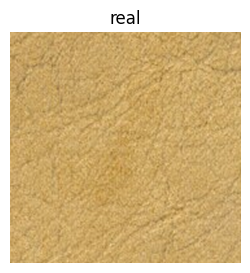

In [ ]:
# ===================== الخلية 5: Backgrounds =====================
_REAL_BG_WARNED = [False]

def list_real_backgrounds(cfg):
    """قراءة ديناميكية لمجلد الخلفيات (تُستدعى كل دفعة)."""
    d = Path(cfg["paths"]["backgrounds_dir"])
    if not d.is_dir():
        return []
    exts = set(e.lower() for e in cfg["paths"]["background_extensions"])
    return sorted(str(p) for p in d.iterdir() if p.is_file() and p.suffix.lower() in exts)

def _sample_key(rng, prob_dict):
    """اختيار مفتاح حسب احتمالات قاموس."""
    keys = list(prob_dict.keys())
    p = np.array([prob_dict[k] for k in keys], dtype=np.float64)
    return keys[int(rng.choice(len(keys), p=p / p.sum()))]

def _lowfreq_noise(rng, S, cfg):
    """3 طبقات ضوضاء منخفضة التردد (sigma كنسبة من S، سعات amps)."""
    b = cfg["backgrounds"]
    out = np.zeros((S, S), np.float32)
    for frac, amp in zip(b["lowfreq_noise_sigmas_frac"], b["lowfreq_noise_amps"]):
        n = rng.standard_normal((S, S)).astype(np.float32)
        n = cv2.GaussianBlur(n, (0, 0), max(1.0, frac * S))
        out += n / (n.std() + 1e-6) * amp
    return out

def _texture_paper(img, rng, S):
    """ألياف ورق: 30-80 خطا رفيعا فاتحا/داكنا."""
    overlay = np.zeros((S, S), np.float32)
    for _ in range(int(rng.integers(30, 81))):
        x0, y0 = rng.uniform(0, S, 2)
        ang, L = rng.uniform(0, np.pi), rng.uniform(0.05, 0.35) * S
        x1, y1 = x0 + math.cos(ang) * L, y0 + math.sin(ang) * L
        delta = float(rng.uniform(3, 10)) * (1.0 if rng.random() < 0.5 else -1.0)
        cv2.line(overlay, (int(x0), int(y0)), (int(x1), int(y1)), delta, 1, cv2.LINE_AA)
    img += overlay[..., None]

def _texture_parchment(img, rng, S):
    """رقّ: تبقّع ناعم + فينييت."""
    blot = np.zeros((S, S), np.float32)
    for _ in range(int(rng.integers(3, 9))):
        c = (int(rng.integers(0, S)), int(rng.integers(0, S)))
        ax = (int(rng.uniform(0.05, 0.25) * S), int(rng.uniform(0.05, 0.25) * S))
        cv2.ellipse(blot, c, ax, float(rng.uniform(0, 180)), 0, 360, 1.0, -1)
    blot = cv2.GaussianBlur(blot, (0, 0), max(1.0, 0.05 * S))
    img -= (blot * float(rng.uniform(10, 30)))[..., None]
    yy, xx = np.mgrid[0:S, 0:S].astype(np.float32)
    r2 = ((xx - S / 2) ** 2 + (yy - S / 2) ** 2) / (2 * (S / 2) ** 2)
    img *= (1.0 - float(rng.uniform(0.08, 0.20)) * r2)[..., None]

def _texture_stone(img, rng, S, cfg):
    """حجر: ضوضاء عالية التردد + شقوق polyline + بقع."""
    std = float(rng.uniform(*cfg["backgrounds"]["stone_highfreq_noise_std_range"]))
    img += rng.normal(0, std, (S, S)).astype(np.float32)[..., None]
    overlay = np.zeros((S, S), np.float32)
    for _ in range(int(rng.integers(2, 7))):
        npts = int(rng.integers(4, 11))
        pts = np.cumsum(rng.uniform(-0.12, 0.12, (npts, 2)) * S, axis=0) + rng.uniform(0, S, 2)
        pts = np.clip(pts, 0, S - 1).astype(np.int32).reshape(-1, 1, 2)
        cv2.polylines(overlay, [pts], False, -float(rng.uniform(20, 50)), int(rng.integers(1, 3)), cv2.LINE_AA)
    for _ in range(int(rng.integers(5, 21))):
        c = (int(rng.integers(0, S)), int(rng.integers(0, S)))
        cv2.circle(overlay, c, int(rng.uniform(0.005, 0.03) * S), float(rng.uniform(-10, 10)), -1, cv2.LINE_AA)
    img += cv2.GaussianBlur(overlay, (0, 0), 0.7)[..., None]

def synthetic_background_pipeline(rng, cfg, S, texture=None, bg_rgb=None):
    """خلفية اصطناعية RGB uint8 + meta."""
    b = cfg["backgrounds"]
    if texture is None:
        texture = _sample_key(rng, b["synthetic_texture_probs"])
    if bg_rgb is None:
        _, bg_rgb = pick_colors(rng, cfg)
    img = np.empty((S, S, 3), np.float32)
    img[:] = bg_rgb
    img += _lowfreq_noise(rng, S, cfg)[..., None]
    if texture == "paper":
        _texture_paper(img, rng, S)
    elif texture == "parchment":
        _texture_parchment(img, rng, S)
    else:
        _texture_stone(img, rng, S, cfg)
    img = np.clip(img, 0, 255).astype(np.uint8)
    meta = {"source": "synthetic", "texture": texture, "bg_rgb": tuple(int(c) for c in bg_rgb),
            "bg_mean_lum": float(luminance(img.reshape(-1, 3).mean(0)))}
    return img, meta

def real_background_pipeline(rng, cfg, S, files, texture=None):
    """خلفية حقيقية: اختيار ملف ووضع قص، resize، سطوع/تباين ±10%، مزج اختياري."""
    b = cfg["backgrounds"]
    path = files[int(rng.integers(len(files)))]
    raw = cv2.imread(path, cv2.IMREAD_COLOR)
    if raw is None:
        print(f"⚠ تعذر قراءة الخلفية {os.path.basename(path)} → اصطناعية.")
        return synthetic_background_pipeline(rng, cfg, S, texture)
    raw = cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)
    H, W = raw.shape[:2]
    m = min(H, W)
    mode = _sample_key(rng, b["real_mode_probs"])
    if mode == "full":
        side = m
    elif mode == "medium_crop":
        side = int(m * rng.uniform(*b["medium_crop_frac_range"]))
    else:
        side = int(m * rng.uniform(*b["small_crop_frac_range"]))
    side = max(8, min(side, m))
    y0, x0 = int(rng.integers(0, H - side + 1)), int(rng.integers(0, W - side + 1))
    crop = raw[y0:y0 + side, x0:x0 + side]
    interp = cv2.INTER_AREA if side > S else cv2.INTER_CUBIC  # AREA للتصغير، CUBIC للتكبير
    crop = cv2.resize(crop, (S, S), interpolation=interp).astype(np.float32)
    bj, cj = cfg["colors"]["brightness_jitter"], cfg["colors"]["contrast_jitter"]
    crop = (crop - 127.5) * (1.0 + rng.uniform(-cj, cj)) + 127.5 + rng.uniform(-bj, bj) * 255.0
    alpha = float(b["real_blend_alpha"])
    if alpha > 0:
        syn, _ = synthetic_background_pipeline(rng, cfg, S, texture)
        crop = crop * (1.0 - alpha) + syn.astype(np.float32) * alpha
    img = np.clip(crop, 0, 255).astype(np.uint8)
    mean_rgb = img.reshape(-1, 3).mean(0)
    meta = {"source": "real", "file": os.path.basename(path), "mode": mode, "texture": texture,
            "bg_rgb": tuple(int(c) for c in mean_rgb), "bg_mean_lum": float(luminance(mean_rgb))}
    return img, meta

def build_background(rng, cfg, size, texture=None, bg_rgb=None, real_files=None):
    """الموزع الرئيسي: حقيقية إن مفعّلة ومتاحة وإلا اصطناعية (تحذير مرة واحدة)."""
    if cfg["backgrounds"]["use_real_backgrounds"]:
        files = real_files if real_files is not None else list_real_backgrounds(cfg)
        if files:
            return real_background_pipeline(rng, cfg, size, files, texture)
        if not _REAL_BG_WARNED[0]:
            print("⚠ use_real_backgrounds=True لكن لا صور في Backgrounds → اصطناعية.")
            _REAL_BG_WARNED[0] = True
    return synthetic_background_pipeline(rng, cfg, size, texture, bg_rgb)

def build_outer_surface(rng, cfg, size, bg_rgb):
    """سطح داكن خلف الصفحة عند page_inset. يعيد (img, outer_color)."""
    dk = float(rng.uniform(*cfg["backgrounds"]["outer_surface_darken_range"]))
    outer = tuple(int(round(c * (1.0 - dk))) for c in bg_rgb)
    img = np.empty((size, size, 3), np.float32)
    img[:] = outer
    img += rng.normal(0, 3.0, (size, size)).astype(np.float32)[..., None]
    return np.clip(img, 0, 255).astype(np.uint8), outer

def draw_ruling_lines(bg, baselines, rng, cfg):
    """خطوط تسطير باهتة: baselines = [(y, x0, x1), ...]. تُستدعى بعد Layout."""
    d = cfg["decorations"]
    t = px(d["ruling_thickness_px_at_640"])
    out = bg.astype(np.float32)
    H, W = out.shape[:2]
    for (y, x0, x1) in baselines:
        frac = float(rng.uniform(*d["ruling_darken_frac_range"]))
        yi = int(round(y)) + int(rng.integers(-1, 2))
        ya, yb = max(0, yi), min(H, yi + t)
        xa, xb = max(0, int(x0)), min(W, int(x1))
        if ya < yb and xa < xb:
            out[ya:yb, xa:xb] *= (1.0 - frac)
    return np.clip(out, 0, 255).astype(np.uint8)

# اختبار سريع
_r = np.random.default_rng(1)
_S = CONFIG["derived"]["S"]
_bg, _meta = build_background(_r, CONFIG, _S)
print("backgrounds detected:", len(list_real_backgrounds(CONFIG)), "| sample meta:", _meta)
plt.figure(figsize=(3, 3)); plt.imshow(_bg); plt.axis("off"); plt.title(_meta["texture"] or _meta["source"]); plt.show()

تعرّف أوزان الموازنة الصنفية، عيّنة الحرف/الكلمة، خطة محتوى الوثيقة (نقاط/عنوان/كلمات كسولة) وخطة الزينة. المخرج: تأكيد الأوزان المنتظمة عند البداية، كلمة عينة، قرارات زينة، ونسبة تعزيز الصنف النادر.

In [ ]:
# ===================== الخلية 6: Content Sampler =====================
def class_weights(counts, beta):
    """أوزان موازنة للحروف الـ22: (1/(counts+1))^beta مسوّاة."""
    c = np.asarray(counts, dtype=np.float64)[:NUM_LETTERS]
    w = (1.0 / (c + 1.0)) ** float(beta)
    return w / w.sum()

def sample_letter(rng, weights):
    """صنف حرف 0..21 حسب الأوزان."""
    return int(rng.choice(NUM_LETTERS, p=weights))

def sample_word(rng, cfg, weights):
    """كلمة: قائمة أصناف بطول من word_length_range."""
    lo, hi = cfg["text"]["word_length_range"]
    n = int(rng.integers(lo, hi + 1))
    return [sample_letter(rng, weights) for _ in range(n)]

class DocumentContentPlan:
    """خطة محتوى وثيقة: نقاط، عنوان، مولد كلمات كسول."""
    def __init__(self, rng, cfg, weights):
        self.rng, self.cfg, self.weights = rng, cfg, weights
        self.has_dots = bool(rng.random() < cfg["dot"]["document_has_dots_prob"])
        self.has_title = bool(rng.random() < cfg["text"]["title_prob"])
        self.words_generated = 0

    def next_word(self):
        self.words_generated += 1
        return sample_word(self.rng, self.cfg, self.weights)

    def dot_after_word(self):
        return self.has_dots and bool(self.rng.random() < self.cfg["dot"]["dot_after_word_prob"])

def decoration_plan(rng, cfg):
    """قرارات الزينة غير المصنفة باحتمالات decorations."""
    d = cfg["decorations"]
    return {
        "ruling": bool(rng.random() < d["ruling_lines_prob"]),
        "colon": bool(rng.random() < d["line_end_colon_prob"]),
        "dash": bool(rng.random() < d["line_end_dash_prob"]),
        "extender": bool(rng.random() < d["extender_prob"]),
        "residue": bool(rng.random() < d["ink_residue_prob"]),
    }

# اختبار سريع
_r = np.random.default_rng(2)
_w = class_weights(np.zeros(NUM_CLASSES), CONFIG["text"]["class_balance_beta"])
_plan = DocumentContentPlan(_r, CONFIG, _w)
print("weights uniform:", np.allclose(_w, 1.0 / NUM_LETTERS))
print("word:", [CLASS_NAMES[c] for c in _plan.next_word()], "| dots:", _plan.has_dots, "| title:", _plan.has_title)
print("decorations:", decoration_plan(_r, CONFIG))
_w2 = class_weights(np.array([500] * 21 + [50] + [0]), 1.5)
print("rare class boosted: w[21]/w[0] =", round(_w2[21] / _w2[0], 2))

weights uniform: True
word: ['GAMAN', 'NUN', 'FI', 'IY'] | dots: True | title: False
decorations: {'ruling': True, 'colon': False, 'dash': False, 'extender': False, 'residue': False}
rare class boosted: w[21]/w[0] = 30.79


تنفّذ خوارزمية التخطيط الـ13 خطوة حرفيا: ارتفاع لوغاريتمي، صفحة مدرَجة/كاملة، عنوان، أسطر RTL بتلاصق وفجوات، نقاط في منتصف الفجوات، ضبط justify بجيتر، خط أساس متموج+ميل، احتواء بحذف الكلمة، كثافة بحذف الأسطر السفلية، إعادة محاولة 0.85×، زينة غير مصنفة، وخطوط تسطير. المخرج: ملخص عددي + رسم تخطيطي للصناديق (أزرق حروف، أحمر نقاط، أخضر زينة، برتقالي تسطير).

قرارات تنفيذية صغيرة أضيفت في هذه الخلية: (أ) page_inset كوسيط اختياري يُمرَّر من sample_image_params، وإلا يُسحب من page_inset_prob؛ (ب) الإمالة shear تُسحب مرة لكل وثيقة والباقي لكل حرف؛ (ج) قرارات الزينة على مستوى الوثيقة ثم 50% لكل سطر مؤهل؛ (د) سطر فارغ يعيد سحب الكلمة حتى 5 مرات قبل تركه.

{'font_name': 'NotoSansSamaritan-Regular.ttf', 'n_lines': 12, 'n_glyphs': 188, 'n_dots': 37, 'below_min': False, 'attempts': 1, 'has_title': False, 'page_inset': False} char_h=22.3 density=0.304 decor=0


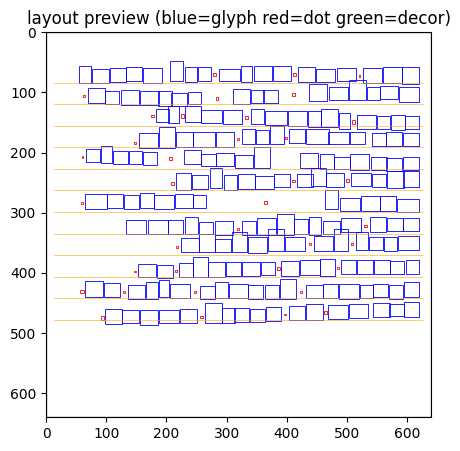

In [ ]:
# ===================== الخلية 7: Layout Engine =====================
@lru_cache(maxsize=8192)
def glyph_bbox(font_path, size, ch):
    """صندوق الحرف الخام نسبة إلى نقطة خط الأساس (anchor 'ls') أو None."""
    bb = get_font(font_path, size).getbbox(ch, anchor="ls")
    if bb is None or bb[2] <= bb[0] or bb[3] <= bb[1]:
        return None
    return tuple(int(v) for v in bb)

def glyph_affine_matrix(sx, sy, shear, rot_deg):
    """مصفوفة 2x2 حول مركز الحرف: دوران ∘ قص ∘ تحجيم (نفس الاصطلاح في الخلية 8)."""
    th = math.radians(rot_deg)
    c, s = math.cos(th), math.sin(th)
    R = np.array([[c, -s], [s, c]], np.float64)
    Sh = np.array([[1.0, shear], [0.0, 1.0]], np.float64)
    Sc = np.array([[sx, 0.0], [0.0, sy]], np.float64)
    return R @ Sh @ Sc

def affine_extents(w0, h0, M):
    """عرض/ارتفاع مستطيل w0×h0 بعد التحويل M."""
    corners = np.array([[-w0/2, -h0/2], [w0/2, -h0/2], [w0/2, h0/2], [-w0/2, h0/2]], np.float64) @ M.T
    return float(np.ptp(corners[:, 0])), float(np.ptp(corners[:, 1]))

def _make_glyph_item(rng, cfg, font_entry, font_size, class_id, char_h, shear, line_idx, word_idx):
    """عنصر حرف: بارامترات أفينية + أبعاد الصندوق المتوقعة."""
    f = cfg["fonts"]
    ch = glyph_char_for(font_entry, class_id)
    bb = glyph_bbox(font_entry["path"], font_size, ch)
    if bb is None:
        return None
    sx = float(rng.uniform(*f["glyph_scale_x_range"]))
    sy = float(rng.uniform(*f["glyph_scale_y_range"]))
    rot = float(rng.uniform(*f["glyph_rotation_deg_range"]))
    jit = float(rng.uniform(-1.0, 1.0)) * f["glyph_baseline_jitter_frac"] * char_h
    w, h = affine_extents(bb[2] - bb[0], bb[3] - bb[1], glyph_affine_matrix(sx, sy, shear, rot))
    cy_off = (bb[1] + bb[3]) / 2.0 * sy + jit   # إزاحة مركز الحرف عن خط الأساس
    return {"kind": "glyph", "class_id": int(class_id), "char": ch, "font_size": int(font_size), "bbox0": bb,
            "scale_x": sx, "scale_y": sy, "shear": shear, "rot_deg": rot, "w": w, "h": h,
            "cx": 0.0, "cy": 0.0, "cy_off": cy_off, "line_idx": line_idx, "word_idx": word_idx, "gap_k": None}

def _build_word(rng, cfg, font_entry, font_size, char_h, shear, classes, line_idx, word_idx):
    """كلمة RTL: عناصر + عرض إجمالي، فجوات داخلية أو تلاصق (فجوة سالبة)."""
    t = cfg["text"]
    items, total = [], 0.0
    for cid in classes:
        it = _make_glyph_item(rng, cfg, font_entry, font_size, cid, char_h, shear, line_idx, word_idx)
        if it is None:
            continue
        if items:
            if rng.random() < t["touch_prob"]:
                total += -float(rng.uniform(*t["touch_overlap_frac_range"])) * it["w"]
            else:
                total += float(rng.uniform(*t["intra_word_gap_frac_range"])) * char_h
        it["rel_x"] = total            # مسافة من يمين الكلمة إلى يمين الحرف
        total += it["w"]
        items.append(it)
    return items, total

def _make_dot(rng, cfg, cx, char_h, line_idx, word_idx, gap_k):
    """نقطة فاصلة صنف 22 مرفوعة عن خط الأساس."""
    d = cfg["dot"]
    r = float(rng.uniform(*d["dot_radius_frac_range"])) * char_h
    return {"kind": "dot", "class_id": DOT_CLASS_ID, "cx": cx, "cy": 0.0, "cy_off": -d["dot_raise_frac"] * char_h,
            "r": r, "w": 2 * r, "h": 2 * r, "line_idx": line_idx, "word_idx": word_idx, "gap_k": gap_k}

def _build_line(rng, cfg, font_entry, font_size, char_h, shear, content_plan, line_idx, x_right, limit):
    """سطر RTL من اليمين حتى limit. يعيد (items, gaps, cursor, n_words)."""
    t = cfg["text"]
    items, gaps, cursor, word_idx, empty_tries = [], [], x_right, 0, 0
    while True:
        witems, wwidth = _build_word(rng, cfg, font_entry, font_size, char_h, shear,
                                     content_plan.next_word(), line_idx, word_idx)
        if not witems:
            empty_tries += 1
            if empty_tries > 5:
                break
            continue
        gap = float(rng.uniform(*t["inter_word_gap_frac_range"])) * char_h if items else 0.0
        if cursor - gap - wwidth < limit:           # لا يتسع: أوقف عند آخر كلمة كاملة
            if not items and empty_tries < 5:
                empty_tries += 1
                continue
            break
        if items:
            if content_plan.dot_after_word():         # نقطة في منتصف الفجوة بين الكلمتين
                items.append(_make_dot(rng, cfg, cursor - gap / 2.0, char_h, line_idx, word_idx - 1, len(gaps)))
            gaps.append({"word_after": word_idx, "width": gap})
        cursor -= gap
        for it in witems:
            it["cx"] = cursor - it["rel_x"] - it["w"] / 2.0
        items.extend(witems)
        cursor -= wwidth
        word_idx += 1
    # نقطة بعد آخر كلمة إن بقي مكان
    if items and content_plan.dot_after_word():
        gap = float(rng.uniform(*t["inter_word_gap_frac_range"])) * char_h
        if cursor - gap >= limit:
            items.append(_make_dot(rng, cfg, cursor - gap / 2.0, char_h, line_idx, word_idx - 1, None))
            cursor -= gap
    return items, gaps, cursor, word_idx

def _plan_layout_once(rng, cfg, font_entry, font_name, char_h, density_max, content_plan, page_inset, S):
    """محاولة تخطيط واحدة بارتفاع حرف محدد."""
    t, dim, deco = cfg["text"], cfg["dimensions"], cfg["decorations"]
    hr = font_entry["height_ratio"]
    font_size = max(4, int(round(char_h / hr)))              # 2
    shear = float(rng.uniform(*cfg["fonts"]["italic_shear_range"]))  # إمالة على مستوى الوثيقة
    # 3. مستطيل الصفحة + 4 هوامش
    if page_inset:
        sc = float(rng.uniform(*dim["page_inset_scale_range"]))
        pw = int(round(S * sc))
        x0, y0 = int(rng.integers(0, S - pw + 1)), int(rng.integers(0, S - pw + 1))
        page_rect = (x0, y0, x0 + pw, y0 + pw)
    else:
        sc, page_rect = 1.0, (0, 0, S, S)
    pw, ph = page_rect[2] - page_rect[0], page_rect[3] - page_rect[1]
    mt, mr, mb, ml = [float(rng.uniform(*dim["margin_frac_range"])) for _ in range(4)]
    c_top, c_right = page_rect[1] + mt * ph, page_rect[2] - mr * pw
    c_bottom, c_left = page_rect[3] - mb * ph, page_rect[0] + ml * pw
    # 4. ارتفاع السطر وعدد الأسطر
    line_h = char_h * float(rng.uniform(*dim["line_height_factor_range"]))
    avail = (c_bottom - c_top) - 0.30 * char_h                # سماحية النازل
    n_max = int(avail // line_h)
    if n_max < 1:
        return None
    n = int(rng.integers(1, n_max + 1))
    # 5. عنوان
    has_title, title_scale = False, 1.0
    if content_plan.has_title and n >= 3:
        ts = float(rng.uniform(*t["title_scale_range"]))
        n_body = min(n - 1, int((avail - ts * line_h) // line_h))
        if n_body >= 1:
            has_title, title_scale, n = True, ts, n_body
    # 6-8. الأسطر
    items, lines_meta, y = [], [], c_top
    total_lines = n + (1 if has_title else 0)
    for li in range(total_lines):
        is_title = has_title and li == 0
        k = title_scale if is_title else 1.0
        ch_l, fs_l, lh_l = char_h * k, max(4, int(round(char_h * k / hr))), line_h * k
        baseline = y + ch_l
        y += lh_l
        limit = c_right - 0.60 * (c_right - c_left) if is_title else c_left
        litems, gaps, cursor, nwords = _build_line(rng, cfg, font_entry, fs_l, ch_l, shear, content_plan, li, c_right, limit)
        if not litems:
            continue
        leftover, justified = cursor - limit, False
        if is_title:                                          # توسيط العنوان
            delta = (c_left + c_right) / 2.0 - (cursor + c_right) / 2.0
            for it in litems:
                it["cx"] += delta
            cursor += delta
        elif gaps and rng.random() < t["justify_prob"]:       # 7. ضبط
            is_last = (li == total_lines - 1)
            if not (is_last and rng.random() < t["last_line_short_prob"]):
                wts = 1.0 + rng.uniform(-t["justify_jitter_frac"], t["justify_jitter_frac"], len(gaps))
                extras = leftover * wts / wts.sum()
                shift = np.concatenate([[0.0], np.cumsum(extras)])   # إزاحة كل كلمة
                for it in litems:
                    s_ = shift[it["word_idx"]]
                    if it["kind"] == "dot" and it["gap_k"] is not None:
                        s_ += extras[it["gap_k"]] / 2.0
                    it["cx"] -= s_
                cursor, leftover, justified = limit, 0.0, True
        # 8. خط أساس متموج + ميل
        amp = float(rng.uniform(*t["baseline_wave_amp_frac_range"])) * ch_l
        period = max(1.0, float(rng.uniform(*t["baseline_wave_period_frac_range"])) * (c_right - c_left))
        phase = float(rng.uniform(0, 2 * math.pi))
        skew = math.tan(math.radians(float(rng.uniform(*t["line_skew_deg_range"]))))
        for it in litems:
            it["cy"] = baseline + it["cy_off"] + amp * math.sin(2 * math.pi * (it["cx"] - c_right) / period + phase) \
                       + (c_right - it["cx"]) * skew
        lines_meta.append({"line_idx": li, "baseline": baseline, "char_h": ch_l, "cursor": cursor,
                           "leftover": leftover, "justified": justified, "is_title": is_title, "n_words": nwords})
        items.extend(litems)
    # 12. زينة غير مصنفة (قرار وثيقة ثم 50% لكل سطر مؤهل)
    plan = decoration_plan(rng, cfg)
    decor = []
    for lm in lines_meta:
        chl, bl, xe = lm["char_h"], lm["baseline"], lm["cursor"]
        if lm["is_title"] or lm["leftover"] < 0.6 * chl:
            continue
        placed = False
        if plan["colon"] and rng.random() < 0.5:
            r, x = 0.06 * chl, xe - 0.30 * chl - 0.06 * chl
            decor.append({"kind": "decor", "dtype": "colon", "points": [(x, bl - 0.25 * chl), (x, bl - 0.65 * chl)],
                          "r": r, "line_idx": lm["line_idx"], "w": 2 * r, "h": 0.4 * chl + 2 * r, "cx": x, "cy": bl - 0.45 * chl})
            placed = True
        elif plan["dash"] and rng.random() < 0.5:
            x1 = xe - 0.20 * chl; x0 = x1 - 0.35 * chl
            decor.append({"kind": "decor", "dtype": "dash", "x0": x0, "x1": x1, "y": bl - 0.40 * chl, "t": 0.08 * chl,
                          "line_idx": lm["line_idx"], "w": x1 - x0, "h": 0.08 * chl, "cx": (x0 + x1) / 2, "cy": bl - 0.40 * chl})
            placed = True
        if not placed and plan["extender"] and not lm["justified"] and lm["leftover"] >= chl and rng.random() < 0.5:
            x1, x0 = xe - 0.05 * chl, c_left + 0.10 * chl
            decor.append({"kind": "decor", "dtype": "extender", "x0": x0, "x1": x1, "y": bl - 0.08 * chl, "t": 0.10 * chl,
                          "line_idx": lm["line_idx"], "w": x1 - x0, "h": 0.10 * chl, "cx": (x0 + x1) / 2, "cy": bl - 0.08 * chl})
    if plan["residue"]:
        for _ in range(int(rng.integers(3, 11))):
            r = float(rng.uniform(0.02, 0.06)) * char_h
            cx, cy = float(rng.uniform(c_left, c_right)), float(rng.uniform(c_top, c_bottom))
            decor.append({"kind": "decor", "dtype": "residue", "cx": cx, "cy": cy, "r": r, "w": 2 * r, "h": 2 * r, "line_idx": -1})
    # 9. احتواء: عنصر خارج الصفحة يلغي كلمته
    def inside(it):
        return (it["cx"] - it["w"] / 2 >= page_rect[0] and it["cx"] + it["w"] / 2 <= page_rect[2] and
                it["cy"] - it["h"] / 2 >= page_rect[1] and it["cy"] + it["h"] / 2 <= page_rect[3])
    bad_words = {(it["line_idx"], it["word_idx"]) for it in items if not inside(it)}
    items = [it for it in items if (it["line_idx"], it["word_idx"]) not in bad_words]
    decor = [dc for dc in decor if inside(dc)]
    # 10. كثافة: حذف أسطر من الأسفل
    area = float(pw * ph)
    while items and sum(it["w"] * it["h"] for it in items) / area > density_max:
        last = max(it["line_idx"] for it in items)
        items = [it for it in items if it["line_idx"] != last]
        decor = [dc for dc in decor if dc["line_idx"] != last]
        lines_meta = [lm for lm in lines_meta if lm["line_idx"] != last]
    kept = {it["line_idx"] for it in items}
    lines_meta = [lm for lm in lines_meta if lm["line_idx"] in kept]
    # 13. خطوط التسطير
    ruling = [(lm["baseline"] + 0.15 * lm["char_h"], page_rect[0] + 0.02 * pw, page_rect[2] - 0.02 * pw) for lm in lines_meta]
    n_glyphs = sum(1 for it in items if it["kind"] == "glyph")
    return {"font_name": font_name, "char_h": char_h, "font_size": font_size, "shear": shear, "page_rect": page_rect,
            "page_inset": bool(page_inset), "page_inset_scale": sc, "content_rect": (c_left, c_top, c_right, c_bottom),
            "line_h": line_h, "has_title": has_title, "title_scale": title_scale, "items": items, "decor": decor,
            "decor_plan": plan, "ruling_baselines": ruling, "lines": lines_meta, "n_lines": len(lines_meta),
            "n_glyphs": n_glyphs, "n_dots": sum(1 for it in items if it["kind"] == "dot"),
            "density": (sum(it["w"] * it["h"] for it in items) / area) if items else 0.0}

def plan_layout(rng, cfg, fonts, font_name, char_height_range, density_max, content_plan, page_inset=None):
    """التخطيط الكامل مع إعادة المحاولة بـ char_h*0.85 حتى 4 مرات عند نقص الحروف."""
    dim, S = cfg["dimensions"], cfg["derived"]["S"]
    font_entry = fonts[font_name]
    if page_inset is None:
        page_inset = bool(rng.random() < dim["page_inset_prob"])
    lo, hi = char_height_range
    char_h = float(math.exp(rng.uniform(math.log(lo), math.log(hi))))   # 1. لوغاريتمي منتظم
    abs_min, min_chars = float(dim["absolute_min_char_height_px"]), cfg["text"]["min_chars_per_document"]
    best, attempts = None, 0
    for attempts in range(1, 6):                                        # أصلية + 4 إعادات
        lay = _plan_layout_once(rng, cfg, font_entry, font_name, char_h, density_max, content_plan, page_inset, S)
        if lay is not None and (best is None or lay["n_glyphs"] > best["n_glyphs"]):
            best = lay
        if lay is not None and lay["n_glyphs"] >= min_chars:
            break
        if char_h <= abs_min + 1e-9:
            break
        char_h = max(abs_min, char_h * 0.85)                            # 11. لا يهبط تحت absolute_min
    if best is None:
        best = {"font_name": font_name, "char_h": char_h, "font_size": 4, "shear": 0.0, "page_rect": (0, 0, S, S),
                "page_inset": bool(page_inset), "page_inset_scale": 1.0, "content_rect": (0, 0, S, S), "line_h": char_h,
                "has_title": False, "title_scale": 1.0, "items": [], "decor": [], "decor_plan": decoration_plan(rng, cfg),
                "ruling_baselines": [], "lines": [], "n_lines": 0, "n_glyphs": 0, "n_dots": 0, "density": 0.0}
    best["below_min"] = best["n_glyphs"] < min_chars
    best["attempts"] = attempts
    return best

# اختبار سريع + رسم صناديق التخطيط
_r = np.random.default_rng(7)
_plan = DocumentContentPlan(_r, CONFIG, class_weights(np.zeros(NUM_CLASSES), CONFIG["text"]["class_balance_beta"]))
_lay = plan_layout(_r, CONFIG, FONTS, FONT_NAMES[0], scaled_char_limits(CONFIG), 0.85, _plan)
print({k: _lay[k] for k in ("font_name", "n_lines", "n_glyphs", "n_dots", "below_min", "attempts", "has_title", "page_inset")},
      "char_h=%.1f density=%.3f decor=%d" % (_lay["char_h"], _lay["density"], len(_lay["decor"])))
_S = CONFIG["derived"]["S"]
fig, ax = plt.subplots(figsize=(5, 5)); ax.set_xlim(0, _S); ax.set_ylim(_S, 0); ax.set_aspect("equal")
pr = _lay["page_rect"]; ax.add_patch(plt.Rectangle((pr[0], pr[1]), pr[2]-pr[0], pr[3]-pr[1], fill=False, ec="gray"))
for it in _lay["items"]:
    ax.add_patch(plt.Rectangle((it["cx"]-it["w"]/2, it["cy"]-it["h"]/2), it["w"], it["h"], fill=False,
                               ec="red" if it["kind"] == "dot" else "blue", lw=0.6))
for dc in _lay["decor"]:
    ax.add_patch(plt.Rectangle((dc["cx"]-dc["w"]/2, dc["cy"]-dc["h"]/2), dc["w"], dc["h"], fill=False, ec="green", lw=0.6))
for (yy, xa, xb) in _lay["ruling_baselines"]:
    ax.plot([xa, xb], [yy, yy], color="orange", lw=0.4)
plt.title("layout preview (blue=glyph red=dot green=decor)"); plt.show()

ترسم كل حرف على قناع صغير بحجم صندوقه + 25% بـ PIL (anchor ls متطابق مع الخلية 7)، تطبّق نفس المصفوفة الأفينية بـ warpAffine LINEAR، تلصق بـ maximum وتختم id_map بـ id متزايد حيث القناع ≥128 (الأحدث فوق الأقدم). النقطة مضلع 10 نقاط غير منتظم + blur 0.3px×SC. الزينة تُرسم في ink_alpha فقط. المخرج: عدد المثيلات وإحصاء بكسلاتها، وصورتان (الحبر الكامل مع الزينة / خريطة الهويات بدونها).

قراران صغيران: (أ) ثوابت الرسم المنصوصة وضعتها في CONFIG["render"] بدل كتابتها داخل الدوال، مع إضافة residue_alpha_range (بقايا الحبر باهتة حتى لا تُشبه النقاط المصنفة)؛ (ب) حرف حُجب كليا بحرف أحدث قبل أي تدهور (0 بكسل) يُستبعد من instances ويُحسب في n_dropped_occluded.

instances: 225 | dropped(occluded): 0 | min/median/max px per glyph: (9, 146, 245) | ids in map: 225


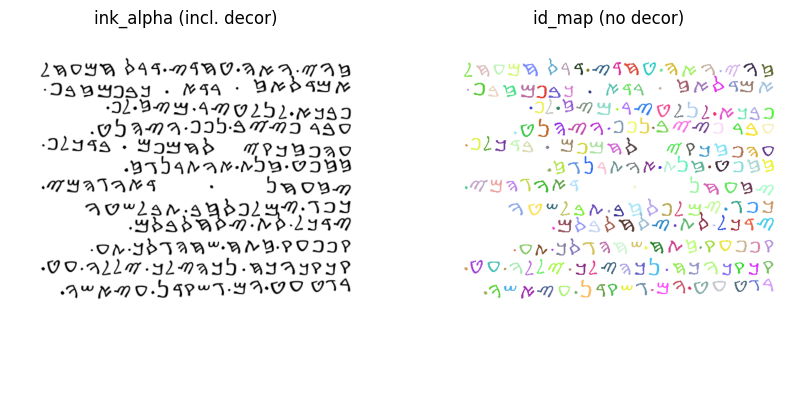

In [ ]:
# ===================== الخلية 8: Glyph Renderer =====================
# ثوابت الرسم المنصوصة في المواصفة (هامش 25%، 10 نقاط للنقطة، blur 0.3px@640، عتبة 128) + قرار: عتامة بقايا الحبر
CONFIG.setdefault("render", {
    "glyph_margin_frac": 0.25, "dot_polygon_points": 10, "dot_blur_px_at_640": 0.3,
    "id_threshold": 128, "residue_alpha_range": (0.25, 0.60), "subpixel_shift_bits": 4,
})

def _glyph_small_mask(font_path, item, cfg):
    """قناع L صغير للحرف (صندوقه + هامش 25%) ثم أفيني (scale/shear/rotation) بـ warpAffine LINEAR."""
    bb = item["bbox0"]
    w0, h0 = bb[2] - bb[0], bb[3] - bb[1]
    pad = int(math.ceil(cfg["render"]["glyph_margin_frac"] * max(w0, h0))) + 1
    cw, ch = w0 + 2 * pad, h0 + 2 * pad
    img = Image.new("L", (cw, ch), 0)
    ImageDraw.Draw(img).text((pad - bb[0], pad - bb[1]), item["char"],
                             font=get_font(font_path, item["font_size"]), fill=255, anchor="ls")
    src = np.asarray(img)
    M = glyph_affine_matrix(item["scale_x"], item["scale_y"], item["shear"], item["rot_deg"])
    ow, oh = int(math.ceil(item["w"])) + 2 * pad, int(math.ceil(item["h"])) + 2 * pad
    in_c = np.array([pad + w0 / 2.0, pad + h0 / 2.0])
    out_c = np.array([ow / 2.0, oh / 2.0])
    t = out_c - M @ in_c
    A = np.hstack([M, t[:, None]]).astype(np.float32)
    return cv2.warpAffine(src, A, (ow, oh), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

def _dot_mask(rng, r, cfg):
    """نقطة: مضلع 10 نقاط حول دائرة نصف قطرها r*(1±irregularity) مملوء + blur 0.3px*SC."""
    rc = cfg["render"]
    irr, npts, sh = cfg["dot"]["dot_irregularity"], rc["dot_polygon_points"], rc["subpixel_shift_bits"]
    size = int(math.ceil(2 * r * (1 + irr))) + 4
    c = size / 2.0
    ang = 2 * math.pi * np.arange(npts) / npts + rng.uniform(0, 2 * math.pi / npts)
    rad = r * (1.0 + rng.uniform(-irr, irr, npts))
    pts = np.stack([c + rad * np.cos(ang), c + rad * np.sin(ang)], 1)
    pts = np.round(pts * (1 << sh)).astype(np.int32).reshape(-1, 1, 2)
    mask = np.zeros((size, size), np.uint8)
    cv2.fillPoly(mask, [pts], 255, cv2.LINE_AA, shift=sh)
    sigma = rc["dot_blur_px_at_640"] * SC
    return cv2.GaussianBlur(mask, (0, 0), max(0.1, sigma))

def _paste_max(ink_alpha, id_map, mask, cx, cy, gid, thr):
    """لصق قناع بمركز (cx,cy): maximum في ink_alpha، ختم id_map حيث القناع>=thr (الأحدث فوق الأقدم)."""
    oh, ow = mask.shape
    H, W = ink_alpha.shape
    x0, y0 = int(round(cx - ow / 2.0)), int(round(cy - oh / 2.0))
    xa, ya, xb, yb = max(0, x0), max(0, y0), min(W, x0 + ow), min(H, y0 + oh)
    if xa >= xb or ya >= yb:
        return
    sub = mask[ya - y0:yb - y0, xa - x0:xb - x0]
    region = ink_alpha[ya:yb, xa:xb]
    np.maximum(region, sub, out=region)
    if id_map is not None and gid is not None:
        id_map[ya:yb, xa:xb][sub >= thr] = gid

def _draw_decor(ink_alpha, decor, rng, cfg):
    """الزينة غير المصنفة في ink_alpha فقط (لا id_map)."""
    rc = cfg["render"]
    sh = rc["subpixel_shift_bits"]
    f = 1 << sh
    for dc in decor:
        dt = dc["dtype"]
        if dt == "colon":
            r = max(1, int(round(dc["r"] * f)))
            for (x, y) in dc["points"]:
                cv2.circle(ink_alpha, (int(round(x * f)), int(round(y * f))), r, 255, -1, cv2.LINE_AA, shift=sh)
        elif dt in ("dash", "extender"):
            t = max(1, int(round(dc["t"])))
            p0 = (int(round(dc["x0"] * f)), int(round(dc["y"] * f)))
            p1 = (int(round(dc["x1"] * f)), int(round(dc["y"] * f)))
            cv2.line(ink_alpha, p0, p1, 255, t, cv2.LINE_AA, shift=sh)
        elif dt == "residue":
            m = _dot_mask(rng, dc["r"], cfg).astype(np.float32) * float(rng.uniform(*rc["residue_alpha_range"]))
            _paste_max(ink_alpha, None, m.astype(np.uint8), dc["cx"], dc["cy"], None, 0)

def render_document(layout, fonts, font_name, rng, cfg, size):
    """يرسم كل الحروف والنقاط والزينة. يعيد ink_alpha uint8، id_map int32، instances مع count_before."""
    thr = cfg["render"]["id_threshold"]
    font_path = fonts[font_name]["path"]
    ink_alpha = np.zeros((size, size), np.uint8)
    id_map = np.zeros((size, size), np.int32)
    instances, gid = [], 0
    for it in layout["items"]:
        gid += 1
        if it["kind"] == "glyph":
            mask = _glyph_small_mask(font_path, it, cfg)
        else:
            mask = _dot_mask(rng, it["r"], cfg)
        _paste_max(ink_alpha, id_map, mask, it["cx"], it["cy"], gid, thr)
        instances.append({"id": gid, "class_id": it["class_id"], "kind": it["kind"], "line_idx": it["line_idx"],
                          "planned_cx": it["cx"], "planned_cy": it["cy"], "planned_w": it["w"], "planned_h": it["h"]})
    _draw_decor(ink_alpha, layout["decor"], rng, cfg)
    # عدّ البكسلات قبل التدهور؛ المحجوب كليا بحرف أحدث (count=0) يُستبعد
    counts = np.bincount(id_map.ravel(), minlength=gid + 1)
    dropped = 0
    kept = []
    for ins in instances:
        ins["count_before"] = int(counts[ins["id"]])
        if ins["count_before"] > 0:
            kept.append(ins)
        else:
            dropped += 1
    return {"ink_alpha": ink_alpha, "id_map": id_map, "instances": kept, "n_dropped_occluded": dropped}

# اختبار سريع على تخطيط الخلية 7
_r = np.random.default_rng(8)
_ren = render_document(_lay, FONTS, _lay["font_name"], _r, CONFIG, CONFIG["derived"]["S"])
_cnts = [i["count_before"] for i in _ren["instances"]]
print("instances:", len(_ren["instances"]), "| dropped(occluded):", _ren["n_dropped_occluded"],
      "| min/median/max px per glyph:", (min(_cnts), int(np.median(_cnts)), max(_cnts)) if _cnts else None,
      "| ids in map:", len(np.unique(_ren["id_map"])) - 1)
_pal = np.random.default_rng(0).integers(40, 255, (len(_ren["instances"]) + 2, 3)).astype(np.uint8); _pal[0] = 255
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(255 - _ren["ink_alpha"], cmap="gray"); axs[0].set_title("ink_alpha (incl. decor)"); axs[0].axis("off")
axs[1].imshow(_pal[np.clip(_ren["id_map"], 0, len(_pal) - 1)]); axs[1].set_title("id_map (no decor)"); axs[1].axis("off")
plt.show()

تنفّذ المراحل الثلاث: (أ) حبر نسبي لـ char_h×s (سمك عام وسطري مع تحديث id_map، bleed، fade عام + jitter لكل مثيل، ضربات مكسورة بقناع ضوضاء، حبيبية، مرونة بـ remap LINEAR/NEAREST، وظل/إضاءة للحجر)؛ (ب) هندسة الصفحة في remap واحد يدمج curl+wave مع homography الدوران+المنظور، والحدود من سطح خارجي لا REPLICATE؛ (ج) كاميرا لا تحرك بكسلات إلا الثقوب (تمسح الهويات)، بترتيب المواصفة حتى JPEG في الذاكرة والثنائية التكيفية؛ وحارس legibility_check. المخرج: ثلاثة قواميس meta + نتيجة المقروئية + ثلاث صور (بعد الحبر/الهندسة/الكاميرا).

قرارات تنفيذية صغيرة: (أ) الأرقام غير المحددة (عتبة الرؤية 48، gain الانتشار، أشكال البقع...) في CONFIG["degradation_consts"]؛ (ب) المقادير تُسحب من [lo, lo+(hi-lo)·s] والمتماثلة تُضرب في s، اتساقا مع أمثلة المواصفة (U(0,max*s)، 92-60s)؛ (ج) بعد مرحلة الحبر تُمسح هوية البكسلات غير المرئية (alpha<48) كي تعكس صناديق ومقروئية الحبر الفعلي؛ (د) قاعدة min_pixels لا تُطبَّق على حرف كان أصلا أصغر من 12 بكسل (نقاط صغيرة عند char_h=14) وإلا فشلت المقروئية دائما.

ink meta: {'s': 0.7, 'fade': 0.3097402069501453}
geom meta: {'rot_deg': 2.3525956478761425, 'perspective': True, 'curl_amp': 0.0, 'wave_amp': 0.0}
cam meta: {'s': 0.7, 'blur_sigma': 0.7987186131548042, 'jpeg_q': 74}
legibility: {'ok': True, 'bad_frac': 0.0044444444444444444, 'n_vanished': 0} | bad ids: 1


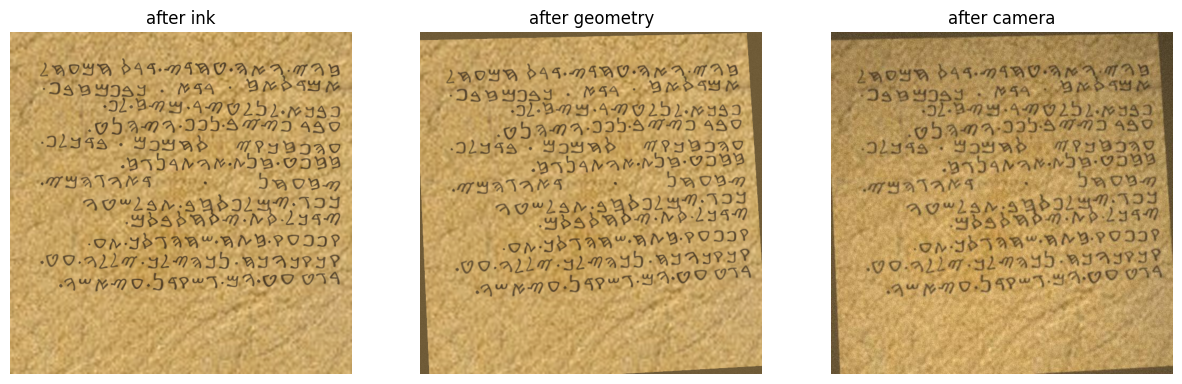

In [ ]:
# ===================== الخلية 9: Degradations =====================
# ثوابت مساعدة للتدهورات لم تُحدد أرقامها في المواصفة (قرار تنفيذي، كلها هنا لا داخل الدوال)
CONFIG.setdefault("degradation_consts", {
    "visible_alpha_threshold": 48,          # بكسل حبر "مرئي" لأغراض id_map والمقروئية
    "bleed_gain": 1.5,                      # تضخيم بعد Blur قبل clip
    "broken_noise_sigma_frac": 0.12, "broken_strength_range": (0.6, 1.0),
    "stone_relief_offset_px_at_640": 1,
    "curl_wave_period_frac_range": (0.20, 0.60),
    "shadow_sigma_frac_range": (0.15, 0.40),
    "showthrough_char_frac_range": (1.0, 2.5), "showthrough_blur_px_at_640": 1.5, "showthrough_line_factor": 1.6,
    "stain_points": 12, "stain_irregularity": 0.35, "stain_blur_frac": 0.15,
    "hole_points": 10, "hole_irregularity": 0.30, "hole_noise_std": 4.0,
    "scratch_len_frac_range": (0.05, 0.40), "scratch_delta_range": (15, 45), "scratch_light_prob": 0.7,
    "motion_blur_len_min_px": 3, "poisson_lambda_range": (4.0, 20.0),
    "sharpen_amount_range": (0.3, 1.0), "sharpen_sigma_px_at_640": 1.0,
    "binarize_block_frac_of_min_char": 2.0, "binarize_C_range": (5, 15),
    "binarize_light_gray_prob": 0.5, "binarize_light_gray_range": (200, 240),
})

def _u(rng, lo, hi, s):
    """سحب من [lo, lo+(hi-lo)*s]: الحد الأعلى يتمدد مع الشدة."""
    return float(lo + (hi - lo) * rng.uniform() * max(0.0, min(1.0, s)))

def _us(rng, lo, hi, s):
    """سحب متماثل حول الصفر مضروب بالشدة."""
    return float(rng.uniform(lo, hi)) * max(0.0, min(1.0, s))

@lru_cache(maxsize=4)
def _pixel_grid(S):
    """شبكة إحداثيات (لا تُعدَّل في مكانها)."""
    yy, xx = np.mgrid[0:S, 0:S].astype(np.float32)
    return xx, yy

def _disk(r):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))

def _shift_alpha(a, dx, dy):
    """إزاحة صحيحة بملء أصفار."""
    out = np.zeros_like(a)
    H, W = a.shape
    ys, yd = (0, dy) if dy >= 0 else (-dy, 0)
    xs, xd = (0, dx) if dx >= 0 else (-dx, 0)
    hh, ww = H - abs(dy), W - abs(dx)
    if hh > 0 and ww > 0:
        out[yd:yd + hh, xd:xd + ww] = a[ys:ys + hh, xs:xs + ww]
    return out

def _morph_with_ids(alpha, ids, r, grow, thr, region=None):
    """تسميك/ترقيق مع تحديث id_map. region قناع bool اختياري (سطر واحد)."""
    k = _disk(r)
    src = alpha if region is None else np.where(region, alpha, 0).astype(np.uint8)
    if grow:
        new_a = cv2.dilate(src, k)
        idf = ids if region is None else np.where(region, ids, 0)
        new_id = cv2.dilate(idf.astype(np.float32), k).astype(np.int32)   # الأقرب/الأحدث يملأ البكسلات الجديدة
        out_a = np.maximum(alpha, new_a)
        fill = (ids == 0) & (new_a >= thr)
        out_id = ids.copy(); out_id[fill] = new_id[fill]
    else:
        new_a = cv2.erode(src, k)
        out_a = new_a if region is None else np.where(region, new_a, alpha).astype(np.uint8)
        gone = (ids != 0) & (out_a < thr)
        if region is not None:
            gone &= region
        out_id = np.where(gone, 0, ids)
    return out_a, out_id

def apply_ink_degradations(ink_alpha, id_map, char_h, s, rng, cfg, stone_mode, instances=None):
    """(أ) تدهورات الحبر النسبية لـ char_h والشدة s. يعيد dict: ink_alpha, id_map, shadow/highlight (stone), meta."""
    ink, dc = cfg["degradations"]["ink"], cfg["degradation_consts"]
    thr = cfg["render"]["id_threshold"]
    S = ink_alpha.shape[0]
    alpha, ids = ink_alpha.copy(), id_map.copy()
    max_id = int(ids.max()) if ids.size else 0
    meta = {"s": float(s)}
    # 1. تغيير السمك العام
    if rng.random() < ink["stroke_change_prob"]:
        frac = float(rng.uniform(*ink["stroke_change_frac_range"]))
        r = int(round(abs(frac) * char_h * s))
        if r >= 1:
            alpha, ids = _morph_with_ids(alpha, ids, r, frac > 0, thr)
            meta["stroke_px"] = r if frac > 0 else -r
    # 2. تفاوت سمك لكل سطر
    if instances and max_id > 0:
        lut = np.full(max_id + 1, -1, np.int32)
        for ins in instances:
            lut[ins["id"]] = ins["line_idx"]
        line_map = lut[np.clip(ids, 0, max_id)]
        for li in np.unique(line_map[line_map >= 0]):
            delta = float(rng.uniform(-1, 1)) * ink["line_stroke_variation_frac"] * char_h * s
            r = int(round(abs(delta)))
            if r >= 1:
                alpha, ids = _morph_with_ids(alpha, ids, r, delta > 0, thr, region=(line_map == li))
    af = alpha.astype(np.float32)
    # 3. انتشار الحبر
    if rng.random() < ink["bleed_prob"]:
        sigma = float(rng.uniform(0, ink["bleed_sigma_frac_max"])) * char_h * s
        if sigma >= 0.3:
            b = cv2.GaussianBlur(af, (0, 0), sigma) * dc["bleed_gain"]
            af = np.clip(np.maximum(af, b), 0, 255)
            meta["bleed_sigma"] = sigma
    # 4. بهتان عام + jitter لكل مثيل
    fade_g = float(rng.uniform(0, ink["fade_max"])) * s
    lut_f = np.full(max_id + 1, 1.0 - fade_g, np.float32)
    if max_id > 0:
        lut_f[1:] = np.clip(1.0 - fade_g + rng.uniform(-1, 1, max_id) * ink["glyph_fade_jitter"] * s, 0.15, 1.0)
    af *= lut_f[np.clip(ids, 0, max_id)]
    meta["fade"] = fade_g
    # 5. ضربات مكسورة
    if rng.random() < ink["broken_prob"]:
        frac = float(rng.uniform(0, ink["broken_removal_frac_max"])) * s
        inkpix = af > 0
        if frac > 0.005 and inkpix.any():
            n = cv2.GaussianBlur(rng.standard_normal((S, S)).astype(np.float32), (0, 0),
                                 max(1.0, dc["broken_noise_sigma_frac"] * char_h))
            q = float(np.quantile(n[inkpix], frac))
            strength = float(rng.uniform(*dc["broken_strength_range"]))
            af = np.where(n < q, af * (1.0 - strength), af)
            meta["broken_frac"] = frac
    # 6. حبيبية
    if rng.random() < ink["granularity_prob"]:
        glo, ghi = ink["granularity_range"]
        af *= rng.uniform(1.0 - (1.0 - glo) * s, ghi, (S, S)).astype(np.float32)
    # 7. تشوه مرن
    if rng.random() < ink["elastic_prob"]:
        amp = float(rng.uniform(0, ink["elastic_amp_frac_max"])) * char_h * s
        if amp >= 0.3:
            sig = max(1.0, ink["elastic_smooth_frac"] * char_h)
            xx, yy = _pixel_grid(S)
            fields = []
            for _ in range(2):
                f = cv2.GaussianBlur(rng.uniform(-1, 1, (S, S)).astype(np.float32), (0, 0), sig)
                fields.append(f / (np.abs(f).max() + 1e-6) * amp)
            mx, my = xx + fields[0], yy + fields[1]
            af = cv2.remap(af, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
            ids = cv2.remap(ids.astype(np.float32), mx, my, cv2.INTER_NEAREST,
                            borderMode=cv2.BORDER_CONSTANT, borderValue=0).astype(np.int32)
            meta["elastic_amp"] = amp
    alpha_u8 = np.clip(np.round(af), 0, 255).astype(np.uint8)
    ids[alpha_u8 < dc["visible_alpha_threshold"]] = 0            # الحبر غير المرئي لا يحمل هوية
    out = {"ink_alpha": alpha_u8, "id_map": ids, "shadow_alpha": None, "highlight_alpha": None, "meta": meta}
    if stone_mode:                                                  # نقش: ظل (+1,+1) وإضاءة (-1,-1) بالمقياس
        d = px(dc["stone_relief_offset_px_at_640"])
        out["shadow_alpha"] = _shift_alpha(alpha_u8, d, d)
        out["highlight_alpha"] = _shift_alpha(alpha_u8, -d, -d)
    return out

def apply_page_geometry(img, id_map, s, rng, cfg, outer=None):
    """(ب) تحويل هندسي واحد: curl+wave ثم دوران+منظور، remap واحد (LINEAR للصورة، NEAREST للهويات)."""
    g, dc = cfg["degradations"]["geometry"], cfg["degradation_consts"]
    S = img.shape[0]
    if outer is None:
        med = np.median(np.concatenate([img[0], img[-1], img[:, 0], img[:, -1]]), axis=0)
        outer = np.empty_like(img); outer[:] = (med * 0.6).astype(np.uint8)
    # دوران
    th = float(rng.uniform(*(g["rotation_large_deg_range"] if rng.random() < g["rotation_large_prob"]
                              else g["rotation_small_deg_range"])))
    th *= (1.0 if rng.random() < 0.5 else -1.0) * (0.3 + 0.7 * s)
    R = np.vstack([cv2.getRotationMatrix2D((S / 2.0, S / 2.0), th, 1.0), [0, 0, 1]]).astype(np.float64)
    # منظور
    P = np.eye(3)
    if rng.random() < g["perspective_prob"]:
        sh = g["perspective_shift_frac_max"] * S * s
        src = np.array([[0, 0], [S, 0], [S, S], [0, S]], np.float32)
        dst = (src + rng.uniform(-1, 1, (4, 2)) * sh).astype(np.float32)
        P = cv2.getPerspectiveTransform(src, dst).astype(np.float64)
    Hinv = np.linalg.inv(P @ R)
    xx, yy = _pixel_grid(S)
    den = Hinv[2, 0] * xx + Hinv[2, 1] * yy + Hinv[2, 2]
    sx = (Hinv[0, 0] * xx + Hinv[0, 1] * yy + Hinv[0, 2]) / den
    sy = (Hinv[1, 0] * xx + Hinv[1, 1] * yy + Hinv[1, 2]) / den
    # انحناء + تموج ورقي (في إحداثيات الصفحة)
    dy = np.zeros_like(sx)
    curl_amp = wave_amp = 0.0
    if rng.random() < g["curl_prob"]:
        curl_amp = float(rng.uniform(0, g["curl_amp_frac_max"])) * S * s
        dy += curl_amp * np.sin(np.pi * sx / S)
    if rng.random() < g["paper_wave_prob"]:
        wave_amp = float(rng.uniform(0, g["paper_wave_amp_frac_max"])) * S * s
        period = float(rng.uniform(*dc["curl_wave_period_frac_range"])) * S
        dy += wave_amp * np.sin(2 * np.pi * sx / period + float(rng.uniform(0, 2 * np.pi)))
    sy = (sy - dy).astype(np.float32); sx = sx.astype(np.float32)
    fill = tuple(int(v) for v in np.median(outer.reshape(-1, 3), axis=0))
    warped = cv2.remap(img, sx, sy, cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=fill)
    valid = cv2.remap(np.full((S, S), 255, np.uint8), sx, sy, cv2.INTER_NEAREST,
                      borderMode=cv2.BORDER_CONSTANT, borderValue=0) > 0
    warped[~valid] = outer[~valid]                                  # الحدود من السطح الخارجي لا REPLICATE
    ids = cv2.remap(id_map.astype(np.float32), sx, sy, cv2.INTER_NEAREST,
                    borderMode=cv2.BORDER_CONSTANT, borderValue=0).astype(np.int32)
    return warped, ids, {"rot_deg": th, "perspective": not np.allclose(P, np.eye(3)), "curl_amp": curl_amp, "wave_amp": wave_amp}

def _blob(rng, S, cx, cy, r, npts, irr, blur_sigma):
    """بقعة غير منتظمة float32 في [0,1]."""
    m = np.zeros((S, S), np.uint8)
    ang = 2 * np.pi * np.arange(npts) / npts + rng.uniform(0, 2 * np.pi / npts)
    rad = r * (1.0 + rng.uniform(-irr, irr, npts))
    pts = np.stack([cx + rad * np.cos(ang), cy + rad * np.sin(ang)], 1).astype(np.int32).reshape(-1, 1, 2)
    cv2.fillPoly(m, [pts], 255, cv2.LINE_AA)
    m = m.astype(np.float32) / 255.0
    return cv2.GaussianBlur(m, (0, 0), blur_sigma) if blur_sigma >= 0.3 else m

def _showthrough_mask(rng, cfg, S, min_char_h, fonts):
    """نص عشوائي مقلوب أفقيا ومموه (خلية واحدة بحجم الكانفاس لكل صورة، لا لكل حرف)."""
    dc = cfg["degradation_consts"]
    name = FONT_NAMES[int(rng.choice(len(FONT_NAMES), p=FONT_WEIGHTS))]
    entry = fonts[name]
    ch_h = float(rng.uniform(*dc["showthrough_char_frac_range"])) * min_char_h
    size = max(6, int(round(ch_h / entry["height_ratio"])))
    font = get_font(entry["path"], size)
    canvas = Image.new("L", (S, S), 0)
    draw = ImageDraw.Draw(canvas)
    n_per_line = int(S / max(1.0, ch_h * 0.9)) + 2
    y = float(rng.uniform(0, ch_h))
    while y < S:
        txt = "".join(glyph_char_for(entry, int(rng.integers(NUM_LETTERS))) for _ in range(n_per_line))
        draw.text((float(rng.uniform(-ch_h, 0)), y), txt, font=font, fill=255)
        y += ch_h * dc["showthrough_line_factor"]
    m = np.asarray(canvas)[:, ::-1].astype(np.float32) / 255.0        # مقلوب (وجه الورقة الخلفي)
    return cv2.GaussianBlur(m, (0, 0), max(0.3, dc["showthrough_blur_px_at_640"] * SC))

def apply_camera_degradations(img, id_map, s, rng, cfg, min_char_h, stone_mode, outer_color=None, fonts=None):
    """(ج) تدهورات الكاميرا/المسح. لا تحرك بكسلات إلا holes (تمسح id_map فيها)."""
    cam, dc = cfg["degradations"]["camera"], cfg["degradation_consts"]
    S = img.shape[0]
    f = img.astype(np.float32)
    ids = id_map.copy()
    xx, yy = _pixel_grid(S)
    ux, uy = xx / S, yy / S
    meta = {"s": float(s)}
    if outer_color is None:
        outer_color = tuple(int(v * 0.5) for v in np.median(f.reshape(-1, 3), axis=0))
    # إضاءة متدرجة (مستوى)
    if rng.random() < cam["illum_gradient_prob"]:
        amp = _u(rng, *cam["illum_amp_range"], s)
        a = float(rng.uniform(0, 2 * np.pi))
        plane = (ux - 0.5) * math.cos(a) + (uy - 0.5) * math.sin(a)
        f *= (1.0 + amp * plane / 0.5)[..., None]
    # ظل
    if rng.random() < cam["shadow_prob"]:
        sig = float(rng.uniform(*dc["shadow_sigma_frac_range"]))
        cx, cy = rng.uniform(0, 1, 2)
        blob = np.exp(-((ux - cx) ** 2 + (uy - cy) ** 2) / (2 * sig ** 2))
        f *= (1.0 - _u(rng, *cam["shadow_darken_range"], s) * blob)[..., None]
    # فينييت
    if rng.random() < cam["vignette_prob"]:
        r2 = ((ux - 0.5) ** 2 + (uy - 0.5) ** 2) / 0.5
        f *= (1.0 - _u(rng, *cam["vignette_strength_range"], s) * r2)[..., None]
    # نفاذ الوجه الخلفي
    if rng.random() < cam["showthrough_prob"]:
        m = _showthrough_mask(rng, cfg, S, min_char_h, fonts if fonts is not None else FONTS)
        f *= (1.0 - _u(rng, *cam["showthrough_opacity_range"], s) * m)[..., None]
        meta["showthrough"] = True
    # بقع
    if rng.random() < cam["stains_prob"]:
        for _ in range(int(rng.integers(cam["stains_count_range"][0], cam["stains_count_range"][1] + 1))):
            r = float(rng.uniform(*cam["stains_radius_frac_range"])) * S
            blob = _blob(rng, S, rng.uniform(0, S), rng.uniform(0, S), r, dc["stain_points"], dc["stain_irregularity"], dc["stain_blur_frac"] * r)
            f *= (1.0 - _u(rng, *cam["stains_darken_range"], s) * blob)[..., None]
    # ثقوب: تملأ بلون السطح الخارجي وتمسح الهويات
    if rng.random() < cam["holes_prob"]:
        for _ in range(int(rng.integers(cam["holes_count_range"][0], cam["holes_count_range"][1] + 1))):
            r = float(rng.uniform(*cam["holes_radius_frac_range"])) * S
            hole = _blob(rng, S, rng.uniform(0, S), rng.uniform(0, S), r, dc["hole_points"], dc["hole_irregularity"], 0.0) > 0.5
            f[hole] = np.asarray(outer_color, np.float32) + rng.normal(0, dc["hole_noise_std"], (int(hole.sum()), 1)).astype(np.float32)
            ids[hole] = 0
        meta["holes"] = True
    # خدوش (حجر فقط)
    if stone_mode and rng.random() < cam["scratches_prob_stone"]:
        ov = np.zeros((S, S), np.float32)
        for _ in range(int(rng.integers(cam["scratches_count_range"][0], cam["scratches_count_range"][1] + 1))):
            x0, y0 = rng.uniform(0, S, 2)
            L, a = float(rng.uniform(*dc["scratch_len_frac_range"])) * S, float(rng.uniform(0, np.pi))
            d = _u(rng, *dc["scratch_delta_range"], max(s, 0.3)) * (1.0 if rng.random() < dc["scratch_light_prob"] else -1.0)
            cv2.line(ov, (int(x0), int(y0)), (int(x0 + L * math.cos(a)), int(y0 + L * math.sin(a))), d, 1, cv2.LINE_AA)
        f += ov[..., None]
    # تمويه غاوسي مقيّد بحجم أصغر حرف
    sigma = min(float(rng.uniform(0, cam["blur_sigma_max_px"] * SC * s)), cam["blur_cap_frac_of_min_char"] * min_char_h)
    if sigma >= 0.15:
        f = cv2.GaussianBlur(f, (0, 0), sigma); meta["blur_sigma"] = sigma
    # تمويه حركة خطي
    if rng.random() < cam["motion_blur_prob"]:
        L = int(round(_u(rng, dc["motion_blur_len_min_px"], cam["motion_blur_len_max_px"] * SC, s)))
        if L >= 2:
            k = np.zeros((L, L), np.float32); c = (L - 1) / 2.0; a = float(rng.uniform(0, np.pi))
            cv2.line(k, (int(round(c - c * math.cos(a))), int(round(c - c * math.sin(a)))),
                     (int(round(c + c * math.cos(a))), int(round(c + c * math.sin(a)))), 1.0, 1)
            f = cv2.filter2D(f, -1, k / max(k.sum(), 1e-6)); meta["motion_len"] = L
    # ضوضاء
    if rng.random() < cam["gauss_noise_prob"]:
        f += rng.normal(0, _u(rng, *cam["gauss_noise_std_range"], s), (S, S, 1)).astype(np.float32)
    if rng.random() < cam["sp_noise_prob"]:
        d = float(rng.uniform(0, cam["sp_noise_density_max"])) * s
        u = rng.uniform(0, 1, (S, S))
        f[u < d / 2] = 0.0; f[u > 1 - d / 2] = 255.0
    if rng.random() < cam["poisson_noise_prob"]:
        llo, lhi = dc["poisson_lambda_range"]
        lam = lhi - (lhi - llo) * float(rng.uniform()) * s
        ch = np.clip(f[..., 0], 0, 255)
        f += (rng.poisson(ch * lam) / lam - ch).astype(np.float32)[..., None]
    # سطوع/تباين/غاما
    b, c = _us(rng, *cam["brightness_range"], s), _us(rng, *cam["contrast_range"], s)
    f = (f - 128.0) * (1.0 + c) + 128.0 + b * 255.0
    gamma = 1.0 + (float(rng.uniform(*cam["gamma_range"])) - 1.0) * s
    lut = (255.0 * (np.arange(256) / 255.0) ** gamma).astype(np.uint8)
    u8 = cv2.LUT(np.clip(f, 0, 255).astype(np.uint8), lut)
    f = u8.astype(np.float32)
    # تحديد
    if rng.random() < cam["sharpen_prob"]:
        amt = _u(rng, *dc["sharpen_amount_range"], max(s, 0.3))
        f = f + amt * (f - cv2.GaussianBlur(f, (0, 0), max(0.3, dc["sharpen_sigma_px_at_640"] * SC)))
    u8 = np.clip(f, 0, 255).astype(np.uint8)
    # JPEG في الذاكرة
    if rng.random() < cam["jpeg_prob"]:
        q = int(round(rng.uniform(max(cam["jpeg_quality_min"], 92 - 60 * s), cam["jpeg_quality_max"])))
        ok, enc = cv2.imencode(".jpg", cv2.cvtColor(u8, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, q])
        if ok:
            u8 = cv2.cvtColor(cv2.imdecode(enc, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB); meta["jpeg_q"] = q
    # ثنائية تكيفية
    if rng.random() < cam["binarize_prob_base"] + cam["binarize_prob_extra"] * s:
        gray = cv2.cvtColor(u8, cv2.COLOR_RGB2GRAY)
        blk = max(11, int(round(dc["binarize_block_frac_of_min_char"] * min_char_h))) | 1
        C = float(rng.uniform(*dc["binarize_C_range"]))
        bw = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, blk, C)
        if rng.random() < dc["binarize_light_gray_prob"]:
            bw = np.where(bw > 0, int(rng.integers(*dc["binarize_light_gray_range"])), 0).astype(np.uint8)
        u8 = np.repeat(bw[..., None], 3, axis=2); meta["binarized"] = True
    return u8, ids, meta

def legibility_check(before, after, instances, cfg):
    """before/after: id_map (2D) أو عدّادات bincount. سيء إن ratio<min أو count_after<min_pixels (لحرف كان كبيرا بما يكفي)."""
    lg = cfg["degradations"]["legibility"]
    ids = [ins["id"] for ins in instances]
    mx = max(ids) if ids else 0
    cb = np.bincount(before.ravel(), minlength=mx + 1) if getattr(before, "ndim", 0) == 2 else np.asarray(before)
    ca = np.bincount(after.ravel(), minlength=mx + 1) if getattr(after, "ndim", 0) == 2 else np.asarray(after)
    bad, vanished = [], 0
    for ins in instances:
        i = ins["id"]
        b = int(cb[i]) if i < len(cb) else int(ins.get("count_before", 0))
        a = int(ca[i]) if i < len(ca) else 0
        ratio = a / max(b, 1)
        if ratio < lg["min_ink_remaining_ratio"] or (a < lg["min_remaining_pixels_per_glyph"] and b >= lg["min_remaining_pixels_per_glyph"]):
            bad.append(i)
        if a < 4:
            vanished += 1
    n = len(instances)
    bad_frac = len(bad) / n if n else 0.0
    return {"ok": bad_frac <= lg["max_bad_glyph_frac"], "bad_frac": bad_frac, "bad_ids": bad,
            "n_vanished": vanished, "counts_after": ca}

# اختبار سريع على مخرجات الخلايا 5 و 7 و 8 (دمج مبسط للاختبار فقط؛ الدمج الرسمي في الخلية 11)
_r = np.random.default_rng(9)
_S = CONFIG["derived"]["S"]
_min_h = min([i["planned_h"] for i in _ren["instances"] if i["kind"] == "glyph"] or [_lay["char_h"]])
_inkres = apply_ink_degradations(_ren["ink_alpha"], _ren["id_map"], _lay["char_h"], 0.7, _r, CONFIG, False, _ren["instances"])
_a = _inkres["ink_alpha"].astype(np.float32)[..., None] / 255.0
_img = np.clip(_bg.astype(np.float32) * (1 - _a) + np.array((30, 22, 18), np.float32) * _a, 0, 255).astype(np.uint8)
_outer, _oc = build_outer_surface(_r, CONFIG, _S, _meta["bg_rgb"])
_img2, _ids2, _gm = apply_page_geometry(_img, _inkres["id_map"], 0.7, _r, CONFIG, outer=_outer)
_img3, _ids3, _cm = apply_camera_degradations(_img2, _ids2, 0.7, _r, CONFIG, _min_h, False, outer_color=_oc)
_leg = legibility_check(_ren["id_map"], _ids3, _ren["instances"], CONFIG)
print("ink meta:", _inkres["meta"]); print("geom meta:", _gm); print("cam meta:", _cm)
print("legibility:", {k: _leg[k] for k in ("ok", "bad_frac", "n_vanished")}, "| bad ids:", len(_leg["bad_ids"]))
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(_img); axs[0].set_title("after ink"); axs[1].imshow(_img2); axs[1].set_title("after geometry")
axs[2].imshow(_img3); axs[2].set_title("after camera")
for ax in axs: ax.axis("off")
plt.show()

تعرّف حالة الجدولة، controlled_params (تدرج خطي في الحد الأدنى لارتفاع الحرف والكثافة، وسلالم شدة بتأخيرات الحبر/الكاميرا/الهندسة مع حماية K=0)، sample_image_params (شدات من الجدول للـ controlled أو U(0,1) للـ fullrandom مع نفس نطاق/كثافة الجدول، خط بالأوزان، ملمس، حجر منقوش، ألوان، عتامة، نقاط، عنوان، إدراج صفحة، أوزان الموازنة من العدادات التراكمية)، وadvance_schedule. المخرج: جدول بكل الخطوات (20 عند 200k) + عينتا معاملات للنوعين تُظهران نفس char_height_range.

قراران صغيران: (أ) has_dots/has_title/page_inset تُسحب هنا وتُفرض على DocumentContentPlan وplan_layout في الخلية 11 بدل سحبها مرتين؛ (ب) ألوان الخلفية الحقيقية يُعاد اختيار حبرها بـ bg_mean بعد بناء الخلفية في الخلية 11.

In [ ]:
# ===================== الخلية 10: Severity & Schedule =====================
class ScheduleState:
    """حالة الجدولة: step يتقدم فقط بعد دفعة controlled."""
    def __init__(self, step=0, completed_batches=0):
        self.step = int(step)
        self.completed_batches = int(completed_batches)

    def to_dict(self):
        return {"step": self.step, "completed_batches": self.completed_batches}

def _ramp(k, K, delay):
    """clip((k-delay)/(K-delay),0,1) مع حماية K<=delay (اختبار دخاني)."""
    if K - delay <= 0:
        return 1.0 if k >= delay else 0.0
    return float(np.clip((k - delay) / float(K - delay), 0.0, 1.0))

def controlled_params(step, cfg):
    """معاملات الدفعة controlled عند step: نطاق ارتفاع الحرف، الكثافة، وحدود الشدة الثلاثة."""
    sch = cfg["schedule"]
    K = int(sch["controlled_steps"]) - 1
    k = int(min(max(step, 0), max(K, 0)))
    frac = (k / K) if K > 0 else 0.0
    abs_min = int(cfg["dimensions"]["absolute_min_char_height_px"])
    lower_640 = sch["char_lower_start_at_640"] + (sch["char_lower_end_at_640"] - sch["char_lower_start_at_640"]) * frac
    char_upper = max(abs_min + 1, px(sch["char_upper_at_640"]))
    char_lower = min(max(abs_min, px(lower_640)), char_upper - 1)
    density = sch["density_start"] + (sch["density_end"] - sch["density_start"]) * frac
    return {
        "step": int(step), "k": k, "K": K,
        "char_height_range": (int(char_lower), int(char_upper)),
        "density_max": float(density),
        "ink_s_max": _ramp(k, K, sch["ink_severity_delay_steps"]),
        "camera_s_max": _ramp(k, K, sch["camera_severity_delay_steps"]),
        "geometry_s_max": _ramp(k, K, sch["geometry_severity_delay_steps"]),
    }

def sample_image_params(rng, kind, sched_params, cfg, fonts=None):
    """معاملات صورة واحدة. controlled: شدات U(0,max) من الجدول. fullrandom: نفس النطاق/الكثافة لكن شدات U(0,1)."""
    fonts = fonts if fonts is not None else FONTS
    names = list(fonts.keys())
    weights = np.array([fonts[n]["weight"] for n in names], np.float64)
    if kind == "controlled":
        ink_s = float(rng.uniform(0, sched_params["ink_s_max"]))
        cam_s = float(rng.uniform(0, sched_params["camera_s_max"]))
        geo_s = float(rng.uniform(0, sched_params["geometry_s_max"]))
    elif kind == "fullrandom":
        ink_s, cam_s, geo_s = (float(v) for v in rng.uniform(0, 1, 3))
    else:
        raise ValueError(f"kind غير معروف: {kind}")
    b = cfg["backgrounds"]
    texture = _sample_key(rng, b["synthetic_texture_probs"])
    stone_mode = bool(texture == "stone" and rng.random() < b["engraved_mode_prob_when_stone"])
    ink_rgb, bg_rgb = pick_colors(rng, cfg)
    counts = sched_params.get("class_counts", np.zeros(NUM_CLASSES))
    return {
        "kind": kind,
        "char_height_range": tuple(sched_params["char_height_range"]),
        "density_max": float(sched_params["density_max"]),
        "ink_s": ink_s, "camera_s": cam_s, "geometry_s": geo_s,
        "font_name": names[int(rng.choice(len(names), p=weights / weights.sum()))],
        "texture": texture, "stone_mode": stone_mode,
        "ink_rgb": tuple(ink_rgb), "bg_rgb": tuple(bg_rgb),
        "ink_opacity": float(rng.uniform(*cfg["colors"]["ink_opacity_range"])),
        "has_dots": bool(rng.random() < cfg["dot"]["document_has_dots_prob"]),
        "has_title": bool(rng.random() < cfg["text"]["title_prob"]),
        "page_inset": bool(rng.random() < cfg["dimensions"]["page_inset_prob"]),
        "class_weights": class_weights(counts, cfg["text"]["class_balance_beta"]),
    }

def advance_schedule(state, kind):
    """يتقدم step فقط بعد دفعة controlled."""
    state.completed_batches += 1
    if kind == "controlled":
        state.step += 1
    return state

# اختبار سريع: جدول الخطوات + عينة معاملات
print(f"{'step':>4s} {'char_range':>12s} {'density':>8s} {'ink':>5s} {'cam':>5s} {'geo':>5s}")
for st in range(CONFIG["schedule"]["controlled_steps"]):
    cp = controlled_params(st, CONFIG)
    print(f"{st:4d} {str(cp['char_height_range']):>12s} {cp['density_max']:8.3f} {cp['ink_s_max']:5.2f} {cp['camera_s_max']:5.2f} {cp['geometry_s_max']:5.2f}")
_r = np.random.default_rng(10)
_sp = controlled_params(0, CONFIG); _sp["class_counts"] = np.zeros(NUM_CLASSES)
for _k in ("controlled", "fullrandom"):
    _p = sample_image_params(_r, _k, _sp, CONFIG)
    print(_k, {k: (round(v, 3) if isinstance(v, float) else v) for k, v in _p.items() if k != "class_weights"})

step   char_range  density   ink   cam   geo
   0    (60, 110)    0.400  0.00  0.00  0.00
   1    (55, 110)    0.450  0.11  0.00  0.00
   2    (50, 110)    0.500  0.22  0.00  0.00
   3    (45, 110)    0.550  0.33  0.00  0.00
   4    (40, 110)    0.600  0.44  0.17  0.00
   5    (34, 110)    0.650  0.56  0.33  0.00
   6    (29, 110)    0.700  0.67  0.50  0.25
   7    (24, 110)    0.750  0.78  0.67  0.50
   8    (19, 110)    0.800  0.89  0.83  0.75
   9    (14, 110)    0.850  1.00  1.00  1.00
controlled {'kind': 'controlled', 'char_height_range': (60, 110), 'density_max': 0.4, 'ink_s': 0.0, 'camera_s': 0.0, 'geometry_s': 0.0, 'font_name': 'Hebrew-Samaritan_new.ttf', 'texture': 'paper', 'stone_mode': False, 'ink_rgb': (30, 22, 18), 'bg_rgb': (210, 210, 205), 'ink_opacity': 0.96, 'has_dots': True, 'has_title': False, 'page_inset': False}
fullrandom {'kind': 'fullrandom', 'char_height_range': (60, 110), 'density_max': 0.4, 'ink_s': 0.338, 'camera_s': 0.576, 'geometry_s': 0.753, 'font_name': 

تنفّذ خط أنابيب الصورة الواحدة بالخطوات التسع المنصوصة: rng من base_seed+global_index، وثيقة فارغة باحتمال 4% (خلفية + كاميرا عشوائية)، معاملات من الجدول، خلفية + سطح خارجي (حبر يعاد اختياره بـ bg_mean للخلفيات الحقيقية)، تخطيط بقرارات has_dots/has_title/page_inset المسحوبة مسبقا، تسطير، رسم، حلقة مقروئية تخفض ink_s بـ 0.25 حتى 3 إعادات، صناديق من id_map النهائي بـ reduceat سريع، ترميز JPEG بجودة التخزين. المخرج: سطران إحصائيان + صورتان بصناديق (أزرق حروف، أحمر نقاط)، وزمن الصورة بالثواني.

قرارات تنفيذية صغيرة: (أ) تتبّع العدّادات بعد كل مرحلة (حبر/هندسة/كاميرا) لتحديد سبب اختفاء الحرف: ثقوب (اختفى في الكاميرا) أو حدود (اختفى في الهندسة) → يُحذف؛ بهتان حبر مع بقاء 1–3 بكسل → يبقى بصندوق بحجمه المخطط حول البقايا؛ صفر بكسل → لا صندوق ممكن فيُحذف (وفاء بمعيار "لا صندوق بلا حبر")؛ (ب) السطح الخارجي يُبنى دائما ويُستخدم لحدود الهندسة والثقوب حتى بلا إدراج صفحة؛ (ج) حلقة المقروئية = محاولة أصلية + max_retries إعادات، وتتوقف مبكرا إن بلغت ink_s صفرا.

[0] controlled: empty=False char_h=54.5 labels=22 deleted={'holes': 0, 'border': 0, 'ink': 0} leg={'ok': True, 'bad_frac': 0.0, 'attempts': 1, 'final_ink_s': 0.0} sev={'ink': 0.0, 'camera': 0.0, 'geometry': 0.0} min_box_h=14 t=0.17s
[1] fullrandom: empty=False char_h=63.4 labels=10 deleted={'holes': 0, 'border': 0, 'ink': 0} leg={'ok': True, 'bad_frac': 0.0, 'attempts': 1, 'final_ink_s': 0.7827242670196971} sev={'ink': 0.78, 'camera': 0.29, 'geometry': 0.25} min_box_h=65 t=0.22s


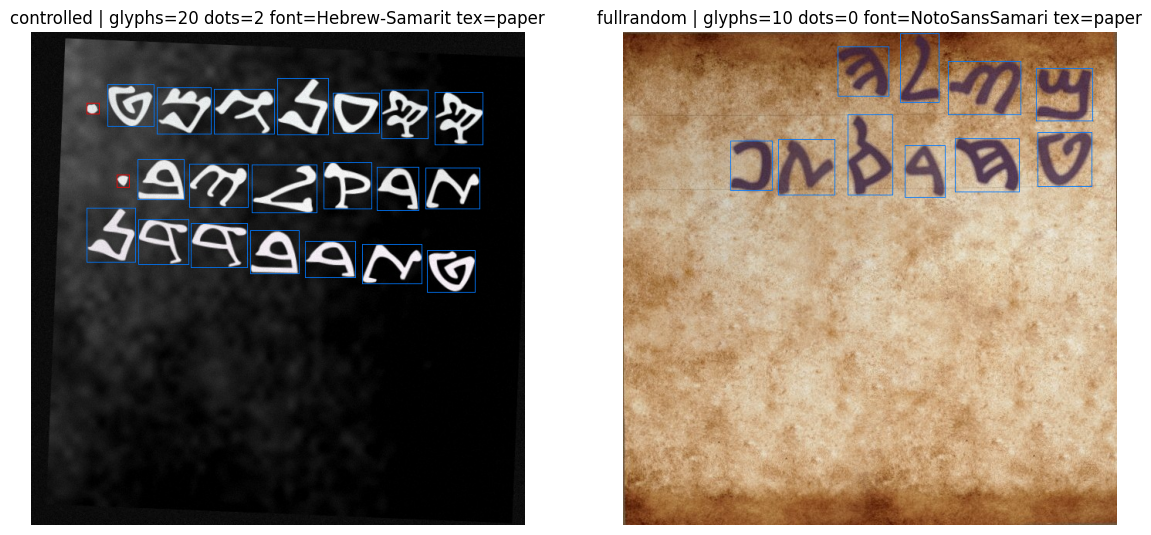

In [ ]:
# ===================== الخلية 11: Single-Image Pipeline =====================
# ثوابت الدمج غير المحددة رقميا في المواصفة (قرار تنفيذي) + عتبة الاختفاء المنصوصة (<4 بكسل)
CONFIG.setdefault("compose", {
    "stone_shadow_strength": 0.45, "stone_highlight_strength": 0.35, "stone_ink_opacity_factor": 0.60,
    "vanish_pixel_threshold": 4,
})

def _boxes_from_ids(ids, max_id):
    """عدّادات وصناديق (xmin,ymin,xmax,ymax شاملة) لكل id دفعة واحدة عبر فرز + reduceat."""
    ys, xs = np.nonzero(ids)
    vals = ids[ys, xs]
    counts = np.bincount(vals, minlength=max_id + 1)
    if vals.size == 0:
        return counts, {}
    order = np.argsort(vals, kind="stable")
    v, xs, ys = vals[order], xs[order], ys[order]
    uniq, starts = np.unique(v, return_index=True)
    xmin, xmax = np.minimum.reduceat(xs, starts), np.maximum.reduceat(xs, starts)
    ymin, ymax = np.minimum.reduceat(ys, starts), np.maximum.reduceat(ys, starts)
    boxes = {int(u): (int(xmin[i]), int(ymin[i]), int(xmax[i]), int(ymax[i])) for i, u in enumerate(uniq)}
    return counts, boxes

def _inset_canvas(bg, outer_img, page_rect):
    """لصق الخلفية مصغّرة داخل page_rect فوق السطح الخارجي."""
    x0, y0, x1, y1 = page_rect
    canvas = outer_img.copy()
    canvas[y0:y1, x0:x1] = cv2.resize(bg, (x1 - x0, y1 - y0), interpolation=cv2.INTER_AREA)
    return canvas

def _compose_ink(bg_canvas, ink_res, instances, params, rng, cfg):
    """img = bg*(1-alpha*op) + ink_color_line*alpha*op ؛ الحجر يدمج الظل/الإضاءة."""
    comp = cfg["compose"]
    ids = ink_res["id_map"]
    mx = int(ids.max()) if ids.size else 0
    lut = np.empty((mx + 1, 3), np.float32)
    lut[:] = np.asarray(params["ink_rgb"], np.float32)          # الزينة والحبر بلا هوية: اللون الأساسي
    line_colors = {}
    for ins in instances:                                        # لون لكل سطر ± jitter
        li = ins["line_idx"]
        if li not in line_colors:
            line_colors[li] = np.asarray(line_ink_color(params["ink_rgb"], rng, cfg), np.float32)
        if ins["id"] <= mx:
            lut[ins["id"]] = line_colors[li]
    color = lut[np.clip(ids, 0, mx)]
    op = params["ink_opacity"] * (comp["stone_ink_opacity_factor"] if params["stone_mode"] else 1.0)
    a = (ink_res["ink_alpha"].astype(np.float32) / 255.0 * op)[..., None]
    img = bg_canvas.astype(np.float32) * (1.0 - a) + color * a
    if params["stone_mode"] and ink_res["shadow_alpha"] is not None:
        sh = ink_res["shadow_alpha"].astype(np.float32) / 255.0
        hl = ink_res["highlight_alpha"].astype(np.float32) / 255.0
        img *= (1.0 - comp["stone_shadow_strength"] * sh)[..., None]
        img += (comp["stone_highlight_strength"] * hl)[..., None] * (255.0 - img)
    return np.clip(img, 0, 255).astype(np.uint8)

def _finalize_boxes(ids_cam, instances, counts_ink, counts_geo, cfg, S):
    """صناديق YOLO من id_map النهائي. حذف فقط عند الاختفاء الفعلي (<4) بسبب ثقوب/حدود أو صفر بكسل."""
    pad, vt = int(cfg["degradations"]["bbox_pad_px"]), int(cfg["compose"]["vanish_pixel_threshold"])
    mx = max(ins["id"] for ins in instances)
    counts_cam, boxes = _boxes_from_ids(ids_cam, mx)
    labels, heights = [], []
    deleted, kept_small = {"holes": 0, "border": 0, "ink": 0}, 0
    for ins in instances:
        i, ca = ins["id"], int(counts_cam[ins["id"]])
        if ca < vt:
            cause = "holes" if counts_geo[i] >= vt else ("border" if counts_ink[i] >= vt else "ink")
            if cause != "ink" or ca == 0:                        # لا بكسلات = لا صندوق ممكن
                deleted[cause] += 1
                continue
            x0, y0, x1, y1 = boxes[i]                            # بقايا حبر: صندوق بالحجم المخطط حولها
            cx, cy, hw, hh = (x0 + x1) / 2.0, (y0 + y1) / 2.0, ins["planned_w"] / 2.0, ins["planned_h"] / 2.0
            x0, y0, x1, y1 = int(cx - hw), int(cy - hh), int(cx + hw), int(cy + hh)
            kept_small += 1
        else:
            x0, y0, x1, y1 = boxes[i]
        xa, ya, xb, yb = max(0, x0 - pad), max(0, y0 - pad), min(S, x1 + 1 + pad), min(S, y1 + 1 + pad)
        if xb <= xa or yb <= ya:
            deleted["border"] += 1
            continue
        labels.append((int(ins["class_id"]), round((xa + xb) / 2.0 / S, 6), round((ya + yb) / 2.0 / S, 6),
                       round((xb - xa) / S, 6), round((yb - ya) / S, 6)))
        heights.append(int(yb - ya))
    return labels, heights, deleted, kept_small

def _encode_jpeg(img_rgb, cfg):
    ok, enc = cv2.imencode(".jpg", cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR),
                           [cv2.IMWRITE_JPEG_QUALITY, int(cfg["storage"]["jpeg_quality"])])
    if not ok:
        raise RuntimeError("فشل ترميز JPEG")
    return enc.tobytes()

def generate_one(global_index, kind, sched_params, cfg_static=None):
    """توليد صورة واحدة كاملة. يعيد dict: jpeg_bytes, labels, إحصاءات. حتمية بالكامل عبر seed."""
    cfg = cfg_static if cfg_static is not None else CONFIG
    t0 = time.time()
    S = cfg["derived"]["S"]
    rng = np.random.default_rng(int(cfg["general"]["base_seed"]) + int(global_index))     # 1
    name = cfg["storage"]["image_name_pattern"].format(index=int(global_index))
    real_files = sched_params.get("real_files")
    is_empty = bool(rng.random() < cfg["general"]["empty_document_prob"])
    params = sample_image_params(rng, kind, sched_params, cfg)                             # 2
    result = {"global_index": int(global_index), "name": name, "kind": kind, "empty": is_empty,
              "font_name": params["font_name"], "texture": params["texture"], "stone_mode": params["stone_mode"],
              "char_height_range": params["char_height_range"], "density_max": params["density_max"],
              "severity": {"ink": params["ink_s"], "camera": params["camera_s"], "geometry": params["geometry_s"]}}
    # 3. الخلفية + السطح الخارجي
    bg, bg_meta = build_background(rng, cfg, S, texture=params["texture"], bg_rgb=params["bg_rgb"], real_files=real_files)
    if bg_meta["source"] == "real":                                                        # حبر يحقق الفرق مع الحقيقية
        params["ink_rgb"], _ = pick_colors(rng, cfg, bg_mean=bg_meta["bg_mean_lum"])
    outer_img, outer_color = build_outer_surface(rng, cfg, S, bg_meta["bg_rgb"])
    result["background"] = bg_meta
    min_h_default = scaled_char_limits(cfg)[0]
    if is_empty:                                                                           # وثيقة فارغة: خلفية + كاميرا عشوائية
        canvas = bg
        if params["page_inset"]:
            sc = float(rng.uniform(*cfg["dimensions"]["page_inset_scale_range"]))
            pw = int(round(S * sc)); x0, y0 = int(rng.integers(0, S - pw + 1)), int(rng.integers(0, S - pw + 1))
            canvas = _inset_canvas(bg, outer_img, (x0, y0, x0 + pw, y0 + pw))
        img, _, cmeta = apply_camera_degradations(canvas, np.zeros((S, S), np.int32), float(rng.uniform()), rng, cfg,
                                                  min_h_default, params["stone_mode"], outer_color=outer_color)
        result.update({"jpeg_bytes": _encode_jpeg(img, cfg), "labels": [], "n_glyphs": 0, "n_dots": 0,
                       "class_counts": np.zeros(NUM_CLASSES, np.int64), "box_heights_px": [], "char_h": None,
                       "legibility": None, "deleted": {}, "elapsed": time.time() - t0})
        return result
    # 4. التخطيط
    plan = DocumentContentPlan(rng, cfg, params["class_weights"])
    plan.has_dots, plan.has_title = params["has_dots"], params["has_title"]
    layout = plan_layout(rng, cfg, FONTS, params["font_name"], params["char_height_range"], params["density_max"],
                         plan, page_inset=params["page_inset"])
    canvas = _inset_canvas(bg, outer_img, layout["page_rect"]) if layout["page_inset"] else bg
    # 5. خطوط التسطير
    if layout["decor_plan"]["ruling"] and layout["ruling_baselines"]:
        canvas = draw_ruling_lines(canvas, layout["ruling_baselines"], rng, cfg)
    # 6. الرسم
    render = render_document(layout, FONTS, params["font_name"], rng, cfg, S)
    instances = render["instances"]
    result.update({"char_h": layout["char_h"], "n_lines": layout["n_lines"], "below_min": layout["below_min"],
                   "layout_attempts": layout["attempts"], "n_occluded": render["n_dropped_occluded"]})
    if not instances:                                                                      # لا حروف: تُعامل كفارغة
        img, _, _ = apply_camera_degradations(canvas, np.zeros((S, S), np.int32), params["camera_s"], rng, cfg,
                                              min_h_default, params["stone_mode"], outer_color=outer_color)
        result.update({"empty": True, "jpeg_bytes": _encode_jpeg(img, cfg), "labels": [], "n_glyphs": 0, "n_dots": 0,
                       "class_counts": np.zeros(NUM_CLASSES, np.int64), "box_heights_px": [], "legibility": None,
                       "deleted": {}, "elapsed": time.time() - t0})
        return result
    mx = max(ins["id"] for ins in instances)
    counts_before = np.bincount(render["id_map"].ravel(), minlength=mx + 1)
    glyph_hs = [ins["planned_h"] for ins in instances if ins["kind"] == "glyph"]
    min_char_h = float(min(glyph_hs)) if glyph_hs else float(layout["char_h"])
    # 7. حلقة المقروئية
    lg = cfg["degradations"]["legibility"]
    ink_s, attempts = params["ink_s"], 0
    for attempts in range(1, lg["max_retries"] + 2):
        ink_res = apply_ink_degradations(render["ink_alpha"], render["id_map"], layout["char_h"], ink_s, rng, cfg,
                                         params["stone_mode"], instances)
        counts_ink = np.bincount(ink_res["id_map"].ravel(), minlength=mx + 1)
        img = _compose_ink(canvas, ink_res, instances, params, rng, cfg)
        img, ids_geo, gmeta = apply_page_geometry(img, ink_res["id_map"], params["geometry_s"], rng, cfg, outer=outer_img)
        counts_geo = np.bincount(ids_geo.ravel(), minlength=mx + 1)
        img, ids_cam, cmeta = apply_camera_degradations(img, ids_geo, params["camera_s"], rng, cfg, min_char_h,
                                                        params["stone_mode"], outer_color=outer_color)
        leg = legibility_check(counts_before, ids_cam, instances, cfg)
        if leg["ok"] or ink_s <= 0.0:
            break
        ink_s = max(0.0, ink_s - lg["severity_step_down"])                                # خفض شدة الحبر وإعادة
    # 8. الصناديق
    labels, heights, deleted, kept_small = _finalize_boxes(ids_cam, instances, counts_ink, counts_geo, cfg, S)
    cc = np.bincount([l[0] for l in labels], minlength=NUM_CLASSES).astype(np.int64)
    # 9. JPEG
    result.update({
        "jpeg_bytes": _encode_jpeg(img, cfg), "labels": labels,
        "n_glyphs": int(cc[:NUM_LETTERS].sum()), "n_dots": int(cc[DOT_CLASS_ID]), "class_counts": cc,
        "box_heights_px": heights, "deleted": deleted, "kept_small": kept_small,
        "legibility": {"ok": bool(leg["ok"]), "bad_frac": float(leg["bad_frac"]), "attempts": attempts, "final_ink_s": ink_s},
        "meta": {"ink": ink_res["meta"], "geometry": gmeta, "camera": cmeta, "ink_rgb": params["ink_rgb"],
                 "bg_rgb": params["bg_rgb"], "page_inset": layout["page_inset"], "has_title": layout["has_title"]},
        "elapsed": time.time() - t0,
    })
    return result

# اختبار سريع: صورتان (controlled عند step 0 و fullrandom) مع رسم الصناديق
_sp = controlled_params(0, CONFIG); _sp["class_counts"] = np.zeros(NUM_CLASSES); _sp["real_files"] = list_real_backgrounds(CONFIG)
_S = CONFIG["derived"]["S"]
fig, axs = plt.subplots(1, 2, figsize=(14, 7))
for ax, (gi, kd) in zip(axs, [(0, "controlled"), (1, "fullrandom")]):
    _res = generate_one(gi, kd, _sp, CONFIG)
    _im = cv2.cvtColor(cv2.imdecode(np.frombuffer(_res["jpeg_bytes"], np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    for (c, xc, yc, w, h) in _res["labels"]:
        x0, y0, x1, y1 = int((xc - w / 2) * _S), int((yc - h / 2) * _S), int((xc + w / 2) * _S), int((yc + h / 2) * _S)
        cv2.rectangle(_im, (x0, y0), (x1, y1), (255, 0, 0) if c == DOT_CLASS_ID else (0, 120, 255), 1)
    ax.imshow(_im); ax.axis("off")
    ax.set_title(f"{kd} | glyphs={_res['n_glyphs']} dots={_res['n_dots']} font={_res['font_name'][:14]} tex={_res['texture']}")
    print(f"[{gi}] {kd}: empty={_res['empty']} char_h={_res['char_h'] and round(_res['char_h'],1)} labels={len(_res['labels'])} "
          f"deleted={_res['deleted']} leg={_res['legibility']} sev={ {k: round(v,2) for k,v in _res['severity'].items()} } "
          f"min_box_h={min(_res['box_heights_px']) if _res['box_heights_px'] else None} t={_res['elapsed']:.2f}s")
plt.show()

تكتب الصورة والتسمية محليا بصيغة YOLO (ملف فارغ للوثائق الفارغة)، وتوفر worker_init (يحقن CONFIG والجدول والمجلد في كل عملية ويصفّر الكاشات ويقيّد خيوط cv2) وworker_task (يولّد ويكتب مباشرة ويعيد إحصاءات خفيفة فقط؛ أي استثناء يُعاد كحقل error ليعالجه مدير الدفعات). المخرج: إحصاءات عينة واحدة، حجم ملف الصورة، عدد أسطر التسمية وأول سطر بصيغة class xc yc w h.

قرار صغير: العامل لا يرفع الاستثناء بل يعيده كنص؛ الخلية 13 ستُفشل الدفعة صراحة إن وُجد أي خطأ (لا تخمين ولا تخطٍّ صامت).

In [ ]:
# ===================== الخلية 12: Writer =====================
def write_sample(result, local_batch_dir, cfg):
    """كتابة images/<name>.jpg و labels/<name>.txt (سطر لكل صندوق، ملف فارغ للفارغة). يعيد المسارين."""
    base = Path(local_batch_dir)
    img_path = base / "images" / f"{result['name']}.{cfg['storage']['image_format']}"
    lbl_path = base / "labels" / f"{result['name']}.txt"
    with open(img_path, "wb") as f:
        f.write(result["jpeg_bytes"])
    lines = [f"{c} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}" for (c, xc, yc, w, h) in result["labels"]]
    with open(lbl_path, "w", encoding="utf-8") as f:
        f.write("\n".join(lines) + ("\n" if lines else ""))
    return str(img_path), str(lbl_path)

def result_to_stats(result):
    """اختزال نتيجة الصورة إلى إحصاءات خفيفة (بلا بايتات) لإرجاعها من العامل."""
    return {
        "global_index": result["global_index"], "name": result["name"], "kind": result["kind"],
        "empty": bool(result["empty"]), "n_glyphs": int(result["n_glyphs"]), "n_dots": int(result["n_dots"]),
        "n_labels": len(result["labels"]), "class_counts": [int(v) for v in result["class_counts"]],
        "box_heights_px": [int(h) for h in result["box_heights_px"]],
        "char_h": (None if result["char_h"] is None else float(result["char_h"])),
        "font_name": result["font_name"], "texture": result["texture"], "stone_mode": bool(result["stone_mode"]),
        "below_min": bool(result.get("below_min", False)), "deleted": dict(result.get("deleted", {})),
        "kept_small": int(result.get("kept_small", 0)), "n_occluded": int(result.get("n_occluded", 0)),
        "legibility": result.get("legibility"), "severity": result["severity"],
        "background_source": result.get("background", {}).get("source"), "elapsed": float(result["elapsed"]),
        "error": None,
    }

# حالة العامل (تُملأ في worker_init داخل كل عملية)
_WORKER = {"cfg": None, "sched_params": None, "kind": None, "batch_dir": None}

def worker_init(cfg, kind, sched_params, batch_dir):
    """تهيئة العامل مرة واحدة لكل عملية: يحفظ CONFIG والجدول والمجلد الهدف."""
    global CONFIG
    CONFIG = cfg
    _WORKER.update({"cfg": cfg, "kind": kind, "sched_params": sched_params, "batch_dir": batch_dir})
    cv2.setNumThreads(1)                     # تجنب تعارض الخيوط مع Pool
    get_font.cache_clear()
    glyph_bbox.cache_clear()

def worker_task(global_index):
    """مهمة عامل: توليد صورة، كتابتها مباشرة، إرجاع إحصاءات فقط. الخطأ يُعاد كنص لا يقتل الدفعة صامتا."""
    w = _WORKER
    try:
        res = generate_one(global_index, w["kind"], w["sched_params"], w["cfg"])
        write_sample(res, w["batch_dir"], w["cfg"])
        return result_to_stats(res)
    except Exception as e:                   # noqa: BLE001
        return {"global_index": int(global_index), "name": w["cfg"]["storage"]["image_name_pattern"].format(index=int(global_index)),
                "error": f"{type(e).__name__}: {e}", "empty": False, "n_glyphs": 0, "n_dots": 0, "n_labels": 0,
                "class_counts": [0] * NUM_CLASSES, "box_heights_px": [], "char_h": None, "font_name": None,
                "texture": None, "stone_mode": False, "below_min": False, "deleted": {}, "kept_small": 0,
                "n_occluded": 0, "legibility": None, "severity": None, "background_source": None, "elapsed": 0.0,
                "kind": w["kind"]}

# اختبار سريع: كتابة عينة محليا في العملية الحالية ثم حذفها
_sp = controlled_params(0, CONFIG); _sp["class_counts"] = np.zeros(NUM_CLASSES); _sp["real_files"] = list_real_backgrounds(CONFIG)
worker_init(CONFIG, "controlled", _sp, CONFIG["paths"]["local_batch_dir"])
_st = worker_task(2)
_ip, _lp = (Path(CONFIG["paths"]["local_batch_dir"]) / "images" / f"{_st['name']}.jpg",
            Path(CONFIG["paths"]["local_batch_dir"]) / "labels" / f"{_st['name']}.txt")
print("stats:", {k: _st[k] for k in ("name", "empty", "n_glyphs", "n_dots", "n_labels", "font_name", "texture", "error")})
print("image bytes:", _ip.stat().st_size, "| label lines:", sum(1 for _ in open(_lp)), "| first line:", open(_lp).readline().strip())
_ip.unlink(); _lp.unlink()

stats: {'name': 'img_0000002', 'empty': False, 'n_glyphs': 12, 'n_dots': 4, 'n_labels': 16, 'font_name': 'Hebrew-Samaritan_new.ttf', 'texture': 'parchment', 'error': None}
image bytes: 94126 | label lines: 16 | first line: 20 0.853906 0.075781 0.148438 0.067187


توفّر إدارة الدفعات كاملة: تسمية الأرشيفات (فردي controlled/زوجي fullrandom)، تحميل checkpoint بالمخطط المنصوص مع تحذير عند اختلاف المفاتيح الحرجة، أرشفة ZIP_STORED محليا ثم copy2 إلى Drive والتحقق (testzip + العدّ) مع إعادة نسخ مرة واحدة، absorb_existing_archive للاستئناف من أرشيف موجود صالح (يعيد عدّ الأصناف والارتفاعات من تسمياته كي تبقى الموازنة دقيقة)، finalize_batch بكتابة ذرّية للـ checkpoint وmetadata تراكمي (هيستوغرام 12 حاوية، متوسط حروف/صورة، زمن) ونقل الدفعة إلى keep_dir، وrun_batch بـ Pool مبني على fork مع imap_unordered(chunksize=16) وفشل صريح عند أي خطأ عامل. المخرج: حالة الاستئناف الحالية (الدفعات المكتملة، الدفعة التالية، وجود أرشيفها وصلاحيته) وحواف الهيستوغرام.

قرارات صغيرة: (أ) fork مطلوب لأن الدوال معرّفة في الدفتر؛ (ب) الأرشيف المحلي يُحذف بعد نجاح التحقق على Drive توفيرا للقرص؛ (ج) pct_boxes_below_min_px_approx في metadata تقريبي من حواف الهيستوغرام، والنسبة الدقيقة تُطبع لكل دفعة من الارتفاعات الفعلية.

In [ ]:
# ===================== الخلية 13: Batch Manager =====================
# ثوابت هيستوغرام أحجام الصناديق (12 حاوية منصوصة، الحد الأعلى قرار تنفيذي)
CONFIG.setdefault("metadata", {"box_height_hist_bins": 12, "box_height_hist_max_px_at_640": 120})
_ZIP_COMPRESSION = {"stored": zipfile.ZIP_STORED, "deflated": zipfile.ZIP_DEFLATED}

def batch_kind(batch_no):
    """فردي controlled، زوجي fullrandom."""
    return "controlled" if batch_no % 2 == 1 else "fullrandom"

def archive_name(batch_no, cfg):
    return cfg["storage"]["archive_name_pattern"].format(batch_no=int(batch_no), kind=batch_kind(batch_no))

def archive_path(batch_no, cfg):
    return str(Path(cfg["paths"]["dataset_dir"]) / archive_name(batch_no, cfg))

def checkpoint_path(cfg):
    return str(Path(cfg["paths"]["dataset_dir"]) / cfg["paths"]["checkpoint_filename"])

def metadata_path(cfg):
    return str(Path(cfg["paths"]["dataset_dir"]) / cfg["paths"]["metadata_filename"])

def _json_safe(o):
    """تحويل numpy/tuple إلى أنواع JSON."""
    if isinstance(o, dict):
        return {str(k): _json_safe(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_json_safe(v) for v in o]
    if isinstance(o, np.ndarray):
        return _json_safe(o.tolist())
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o

def save_json_atomic(path, obj):
    """كتابة ذرّية: tmp ثم replace."""
    tmp = str(path) + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(_json_safe(obj), f, indent=2, ensure_ascii=False)
    os.replace(tmp, path)

def _config_snapshot(cfg):
    keys = ("general", "dimensions", "text", "dot", "colors", "backgrounds", "schedule", "storage")
    snap = {k: cfg[k] for k in keys}
    snap["fonts_registry"] = cfg["fonts"]["registry"]
    return _json_safe(snap)

def empty_checkpoint(cfg):
    return {"completed_batches": 0, "schedule_step": 0, "class_counts": [0] * NUM_CLASSES, "batches": [],
            "config_snapshot": _config_snapshot(cfg), "fonts_loaded": FONT_NAMES,
            "backgrounds_detected": len(list_real_backgrounds(cfg))}

def load_checkpoint(cfg):
    """تحميل checkpoint.json أو إنشاء فارغ، مع تحذير عند اختلاف المفاتيح الحرجة."""
    p = checkpoint_path(cfg)
    if not os.path.isfile(p):
        return empty_checkpoint(cfg)
    with open(p, "r", encoding="utf-8") as f:
        ck = json.load(f)
    for k, v in empty_checkpoint(cfg).items():
        ck.setdefault(k, v)
    snap = ck.get("config_snapshot", {})
    for sec, key in (("general", "total_images"), ("general", "batch_size"), ("general", "base_seed"), ("dimensions", "image_size")):
        old = snap.get(sec, {}).get(key)
        if old is not None and old != cfg[sec][key]:
            print(f"⚠ checkpoint: {sec}.{key} كان {old} والآن {cfg[sec][key]} — الاستئناف قد يكون غير متسق.")
    return ck

def hist_edges(cfg):
    m = cfg["metadata"]
    return np.linspace(0, px(m["box_height_hist_max_px_at_640"]), m["box_height_hist_bins"] + 1)

def box_height_hist(heights, cfg):
    """هيستوغرام 12 حاوية، ما فوق الحد يقع في الأخيرة."""
    edges = hist_edges(cfg)
    h = np.clip(np.asarray(heights, np.float64), 0, edges[-1] - 1e-6) if len(heights) else np.zeros(0)
    return np.histogram(h, bins=edges)[0].tolist()

def _strip_sched(sched_params):
    """نسخة قابلة للحفظ من sched_params (بلا مصفوفات/قوائم ملفات)."""
    s = {k: v for k, v in sched_params.items() if k not in ("class_counts", "real_files")}
    s["n_real_files"] = len(sched_params.get("real_files") or [])
    return _json_safe(s)

def aggregate_stats(stats, cfg, elapsed):
    """تجميع إحصاءات دفعة من مخرجات العمال."""
    min_h = scaled_char_limits(cfg)[0]
    cc = np.zeros(NUM_CLASSES, np.int64)
    heights, fonts, textures, deleted = [], {}, {}, {}
    n_empty = n_below = n_leg_fail = n_kept_small = n_occl = n_stone = n_real = 0
    attempts = []
    for st in stats:
        cc += np.asarray(st["class_counts"], np.int64)
        heights.extend(st["box_heights_px"])
        n_empty += int(st["empty"]); n_below += int(st["below_min"]); n_kept_small += st["kept_small"]
        n_occl += st["n_occluded"]; n_stone += int(st["stone_mode"]); n_real += int(st["background_source"] == "real")
        if st["font_name"]:
            fonts[st["font_name"]] = fonts.get(st["font_name"], 0) + 1
        if st["texture"]:
            textures[st["texture"]] = textures.get(st["texture"], 0) + 1
        for k, v in (st["deleted"] or {}).items():
            deleted[k] = deleted.get(k, 0) + int(v)
        if st["legibility"]:
            n_leg_fail += int(not st["legibility"]["ok"]); attempts.append(st["legibility"]["attempts"])
    n = len(stats)
    n_glyphs, n_dots = int(cc[:NUM_LETTERS].sum()), int(cc[DOT_CLASS_ID])
    heights_a = np.asarray(heights)
    return {"n_images": n, "n_glyphs": n_glyphs, "n_dots": n_dots, "n_boxes": int(cc.sum()), "n_empty": n_empty,
            "avg_chars_per_image": n_glyphs / max(1, n - n_empty), "dot_fraction": n_dots / max(1, int(cc.sum())),
            "class_counts": cc.tolist(), "box_height_hist": box_height_hist(heights, cfg),
            "pct_boxes_below_min_px": float((heights_a < min_h).mean() * 100) if heights_a.size else 0.0,
            "n_below_min_docs": n_below, "n_legibility_fail": n_leg_fail,
            "avg_legibility_attempts": float(np.mean(attempts)) if attempts else 0.0,
            "n_kept_small": n_kept_small, "n_occluded": n_occl, "deleted": deleted, "n_stone_mode": n_stone,
            "n_real_backgrounds": n_real, "fonts": fonts, "textures": textures,
            "elapsed": float(elapsed), "img_per_s": n / max(elapsed, 1e-6)}

def verify_archive(path, expected, cfg):
    """صحة zip + عدد images==expected و labels==expected. يعيد (ok, msg)."""
    try:
        with zipfile.ZipFile(path, "r") as z:
            if z.testzip() is not None:
                return False, "testzip فشل"
            names = z.namelist()
        ext = "." + cfg["storage"]["image_format"]
        n_img = sum(1 for n in names if n.startswith("images/") and n.endswith(ext))
        n_lbl = sum(1 for n in names if n.startswith("labels/") and n.endswith(".txt"))
        if n_img != expected or n_lbl != expected:
            return False, f"images={n_img} labels={n_lbl} expected={expected}"
        return True, "ok"
    except (zipfile.BadZipFile, OSError) as e:
        return False, f"{type(e).__name__}: {e}"

def archive_batch(batch_no, expected, cfg):
    """zip STORED محلي → copy2 إلى Drive → verify على نسخة Drive وإلا إعادة نسخ مرة واحدة."""
    p = cfg["paths"]
    local_zip = Path(p["local_work_dir"]) / archive_name(batch_no, cfg)
    comp = _ZIP_COMPRESSION[cfg["storage"]["zip_compression"]]
    base = Path(p["local_batch_dir"])
    with zipfile.ZipFile(local_zip, "w", compression=comp) as z:
        for sub in ("images", "labels"):
            for f in sorted((base / sub).iterdir()):
                z.write(f, arcname=f"{sub}/{f.name}")
    ok, msg = verify_archive(local_zip, expected, cfg)
    if not ok:
        raise RuntimeError(f"الأرشيف المحلي غير صالح: {msg}")
    dest = archive_path(batch_no, cfg)
    for attempt in range(2):
        shutil.copy2(local_zip, dest)
        ok, msg = verify_archive(dest, expected, cfg)
        if ok:
            break
        print(f"⚠ نسخة Drive غير صالحة ({msg})، إعادة النسخ ({attempt + 1}/2)...")
    if not ok:
        raise RuntimeError(f"فشل التحقق من أرشيف Drive بعد إعادة النسخ: {msg}")
    local_zip.unlink()
    return dest

def absorb_existing_archive(batch_no, cfg):
    """استئناف: أرشيف موجود وصالح → إحصاءات من تسمياته (أصناف وارتفاعات) دون إعادة توليد."""
    S = cfg["derived"]["S"]
    cc = np.zeros(NUM_CLASSES, np.int64)
    heights, n_empty, n_img = [], 0, 0
    with zipfile.ZipFile(archive_path(batch_no, cfg), "r") as z:
        for n in z.namelist():
            if not (n.startswith("labels/") and n.endswith(".txt")):
                continue
            n_img += 1
            rows = [r.split() for r in z.read(n).decode("utf-8").splitlines() if r.strip()]
            if not rows:
                n_empty += 1
            for r in rows:
                cc[int(r[0])] += 1
                heights.append(float(r[4]) * S)
    n_glyphs = int(cc[:NUM_LETTERS].sum())
    min_h = scaled_char_limits(cfg)[0]
    return {"n_images": n_img, "n_glyphs": n_glyphs, "n_dots": int(cc[DOT_CLASS_ID]), "n_boxes": int(cc.sum()),
            "n_empty": n_empty, "avg_chars_per_image": n_glyphs / max(1, n_img - n_empty),
            "dot_fraction": int(cc[DOT_CLASS_ID]) / max(1, int(cc.sum())), "class_counts": cc.tolist(),
            "box_height_hist": box_height_hist(heights, cfg),
            "pct_boxes_below_min_px": float((np.asarray(heights) < min_h).mean() * 100) if heights else 0.0,
            "absorbed": True, "elapsed": None, "img_per_s": None}

def finalize_batch(batch_no, kind, summary, sched_params, ckpt, cfg):
    """تحديث checkpoint ذرّيا، metadata تراكمي، نقل الدفعة إلى keep_dir أو حذفها، تهيئة current_batch."""
    p, g = cfg["paths"], cfg["general"]
    ckpt["completed_batches"] = int(batch_no)
    ckpt["class_counts"] = (np.asarray(ckpt["class_counts"], np.int64) + np.asarray(summary["class_counts"], np.int64)).tolist()
    ckpt["backgrounds_detected"] = len(sched_params.get("real_files") or [])
    ckpt["fonts_loaded"] = FONT_NAMES
    ckpt["batches"].append({"batch_no": int(batch_no), "kind": kind, "archive": archive_name(batch_no, cfg),
                            "n_images": summary["n_images"], "n_glyphs": summary["n_glyphs"],
                            "sched_params": _strip_sched(sched_params), "elapsed": summary["elapsed"],
                            "img_per_s": summary["img_per_s"]})
    save_json_atomic(checkpoint_path(cfg), ckpt)
    # metadata تراكمي
    mp = metadata_path(cfg)
    meta = {"class_names": CLASS_NAMES, "image_size": cfg["derived"]["S"], "box_height_hist_edges": hist_edges(cfg).tolist(),
            "total_images": 0, "total_glyphs": 0, "total_dots": 0, "total_empty": 0, "total_elapsed_sec": 0.0,
            "class_counts": [0] * NUM_CLASSES, "box_height_hist": [0] * cfg["metadata"]["box_height_hist_bins"], "batches": []}
    if os.path.isfile(mp):
        with open(mp, "r", encoding="utf-8") as f:
            meta.update(json.load(f))
    meta["total_images"] += summary["n_images"]; meta["total_glyphs"] += summary["n_glyphs"]
    meta["total_dots"] += summary["n_dots"]; meta["total_empty"] += summary["n_empty"]
    meta["total_elapsed_sec"] += float(summary["elapsed"] or 0.0)
    meta["class_counts"] = (np.asarray(meta["class_counts"]) + np.asarray(summary["class_counts"])).tolist()
    meta["box_height_hist"] = (np.asarray(meta["box_height_hist"]) + np.asarray(summary["box_height_hist"])).tolist()
    meta["avg_chars_per_image"] = meta["total_glyphs"] / max(1, meta["total_images"] - meta["total_empty"])
    all_h = np.asarray(meta["box_height_hist"], np.float64)
    below_bins = hist_edges(cfg)[1:] <= scaled_char_limits(cfg)[0]
    meta["pct_boxes_below_min_px_approx"] = float(all_h[below_bins].sum() / max(1.0, all_h.sum()) * 100)
    meta["batches"].append({"batch_no": int(batch_no), "kind": kind, **summary, "sched_params": _strip_sched(sched_params)})
    save_json_atomic(mp, meta)
    # الملفات المحلية
    if not summary.get("absorbed"):
        cur = Path(p["local_batch_dir"])
        if g["keep_last_batch_local"]:
            keep = Path(p["local_keep_dir"])
            shutil.rmtree(keep, ignore_errors=True)
            shutil.move(str(cur), str(keep))
        else:
            shutil.rmtree(cur, ignore_errors=True)
        clean_batch_dir(cfg)
    return ckpt, meta

def clean_batch_dir(cfg):
    """تهيئة current_batch فارغا بمجلدي images/ و labels/."""
    cur = Path(cfg["paths"]["local_batch_dir"])
    shutil.rmtree(cur, ignore_errors=True)
    for sub in ("images", "labels"):
        (cur / sub).mkdir(parents=True, exist_ok=True)

def batch_indices(batch_no, cfg):
    """global_index=(batch_no-1)*batch_size+i مع قصّ آخر دفعة على total_images."""
    bs, total = cfg["general"]["batch_size"], cfg["general"]["total_images"]
    start = (batch_no - 1) * bs
    return list(range(start, min(start + bs, total)))

def run_batch(batch_no, kind, sched_params, cfg):
    """Pool(num_workers).imap_unordered(chunksize=16) مع tqdm. يعيد (stats, elapsed). أي خطأ عامل = فشل صريح."""
    clean_batch_dir(cfg)
    idx = batch_indices(batch_no, cfg)
    nw = cfg["performance"]["num_workers"] or os.cpu_count() or 1
    t0 = time.time()
    stats, errors = [], []
    ctx = multiprocessing.get_context("fork")
    with ctx.Pool(nw, initializer=worker_init,
                  initargs=(cfg, kind, sched_params, cfg["paths"]["local_batch_dir"])) as pool:
        for st in tqdm(pool.imap_unordered(worker_task, idx, chunksize=16), total=len(idx),
                       desc=f"batch {batch_no:03d} {kind}", leave=False):
            if st.get("error"):
                errors.append(st)
            else:
                stats.append(st)
    elapsed = time.time() - t0
    if errors:
        for e in errors[:5]:
            print(f"✗ {e['name']}: {e['error']}")
        raise RuntimeError(f"فشل {len(errors)} صورة في الدفعة {batch_no}. أوقف.")
    return stats, elapsed

# اختبار سريع: حالة checkpoint الحالية على Drive
_ck = load_checkpoint(CONFIG)
print("completed_batches:", _ck["completed_batches"], "| schedule_step:", _ck["schedule_step"],
      "| total boxes so far:", int(np.sum(_ck["class_counts"])), "| n_batches planned:", CONFIG["derived"]["n_batches"])
_next = _ck["completed_batches"] + 1
if _next <= CONFIG["derived"]["n_batches"]:
    _ap = archive_path(_next, CONFIG)
    print("next batch:", _next, batch_kind(_next), "| archive exists:", os.path.isfile(_ap),
          "| valid:", verify_archive(_ap, len(batch_indices(_next, CONFIG)), CONFIG) if os.path.isfile(_ap) else "-")
print("hist edges:", hist_edges(CONFIG).astype(int).tolist())

⚠ checkpoint: general.total_images كان 200000 والآن 100000 — الاستئناف قد يكون غير متسق.
completed_batches: 13 | schedule_step: 7 | total boxes so far: 1376883 | n_batches planned: 20
next batch: 14 fullrandom | archive exists: False | valid: -
hist edges: [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120]


الحلقة الرئيسية: تستأنف من checkpoint.json، تحدد النوع بالرقم (فردي controlled/زوجي fullrandom)، تحسب sched_params من state.step مع العدادات التراكمية للموازنة وقائمة الخلفيات المقروءة ديناميكيا، تستوعب الأرشيف الموجود الصالح بدل إعادة توليده، وإلا تشغّل الدفعة وتؤرشفها وتتحقق، ثم تُحدّث الجدول وتكتب checkpoint/metadata ذرّيا، وتطبع الملخص المنصوص (النوع، step، نطاق الارتفاع، الكثافة، s_max، متوسط حروف/صورة، نسبة نقاط، أكثر/أقل حرف بالدفعة وتراكميا مع فارق %، السرعة، الزمن المتبقي)، وتعرض شبكة 5×6 وتحفظها previews/batch_XXX.png. المخرج: لكل دفعة شريط tqdm ثم ملخص وشبكة معاينة؛ وفي الدفعة fullrandom يظهر نفس char_height_range للدفعة controlled السابقة.

قراران صغيران: (أ) advance_schedule يُستدعى قبل finalize_batch كي يُكتب schedule_step والعدادات في كتابة ذرّية واحدة (نفس المعنى المنصوص: التقدم فقط بعد controlled)؛ (ب) الزمن المتبقي يُقدَّر من متوسط زمن دفعات الجلسة الحالية فقط.

In [ ]:
# ===================== الخلية 14: Main Loop =====================
# 23 لونا ثابتا للصناديق: tab20 + 3 من tab20b (ألوان معاينة، تُستخدم هنا وفي الخلية 15)
CLASS_COLORS = [tuple(int(c * 255) for c in matplotlib.cm.tab20(i)[:3]) for i in range(20)] + \
               [tuple(int(c * 255) for c in matplotlib.cm.tab20b(i)[:3]) for i in range(3)]
CONFIG.setdefault("preview", {"grid_cols": 5, "cell_inches": 3.0, "box_thickness": 1, "dpi": 100})

def _draw_boxes(img_rgb, labels, S, thickness):
    """رسم صناديق YOLO على نسخة من الصورة بلون الصنف الثابت."""
    out = img_rgb.copy()
    for (c, xc, yc, w, h) in labels:
        x0, y0 = int(round((xc - w / 2) * S)), int(round((yc - h / 2) * S))
        x1, y1 = int(round((xc + w / 2) * S)), int(round((yc + h / 2) * S))
        cv2.rectangle(out, (x0, y0), (x1, y1), CLASS_COLORS[int(c)], thickness)
    return out

def _parse_label_text(txt):
    rows = []
    for r in txt.splitlines():
        p = r.split()
        if len(p) == 5:
            rows.append((int(p[0]), float(p[1]), float(p[2]), float(p[3]), float(p[4])))
    return rows

def load_batch_samples(batch_no, n, cfg, rng):
    """n عينة عشوائية من دفعة: من local_keep_dir إن كانت تحويها وإلا من الأرشيف على Drive (zipfile.read بلا فك كامل)."""
    idx = set(batch_indices(batch_no, cfg))
    ext = "." + cfg["storage"]["image_format"]
    keep = Path(cfg["paths"]["local_keep_dir"]) / "images"
    samples = []
    if keep.is_dir():
        files = [f for f in keep.iterdir() if f.suffix == ext and int(f.stem.split("_")[-1]) in idx]
        if len(files) >= min(n, len(idx)):
            for f in [files[i] for i in rng.choice(len(files), min(n, len(files)), replace=False)]:
                img = cv2.cvtColor(cv2.imread(str(f), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
                lbl = _parse_label_text(open(keep.parent / "labels" / f"{f.stem}.txt", encoding="utf-8").read())
                samples.append((f.stem, img, lbl))
            return samples, "local_keep"
    ap = archive_path(batch_no, cfg)
    if not os.path.isfile(ap):
        return [], "none"
    with zipfile.ZipFile(ap, "r") as z:
        names = [m for m in z.namelist() if m.startswith("images/") and m.endswith(ext)]
        for m in [names[i] for i in rng.choice(len(names), min(n, len(names)), replace=False)]:
            stem = Path(m).stem
            img = cv2.cvtColor(cv2.imdecode(np.frombuffer(z.read(m), np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
            samples.append((stem, img, _parse_label_text(z.read(f"labels/{stem}.txt").decode("utf-8"))))
    return samples, "archive"

def show_batch_preview(batch_no, cfg, n=None, save_png=None):
    """شبكة 5 أعمدة بصناديق ملونة، وحفظ previews/batch_XXX.png إن مفعّل."""
    g, pv, S = cfg["general"], cfg["preview"], cfg["derived"]["S"]
    n = n or g["preview_samples_per_batch"]
    save_png = g["save_preview_png_to_drive"] if save_png is None else save_png
    rng = np.random.default_rng(int(g["base_seed"]) + int(batch_no))       # عشوائية معاينة حتمية بلا random عالمي
    samples, source = load_batch_samples(batch_no, n, cfg, rng)
    if not samples:
        print(f"⚠ لا عينات للمعاينة للدفعة {batch_no}."); return None
    cols = pv["grid_cols"]; rows = int(math.ceil(len(samples) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(cols * pv["cell_inches"], rows * pv["cell_inches"]))
    axs = np.atleast_1d(axs).ravel()
    for ax in axs:
        ax.axis("off")
    for ax, (stem, img, lbl) in zip(axs, samples):
        ax.imshow(_draw_boxes(img, lbl, S, pv["box_thickness"]))
        ax.set_title(f"{stem}  n={len(lbl)}", fontsize=7)
    fig.suptitle(f"batch {batch_no:03d} {batch_kind(batch_no)}  ({source})", fontsize=10)
    plt.tight_layout()
    path = None
    if save_png:
        path = str(Path(cfg["paths"]["previews_dir"]) / f"batch_{int(batch_no):03d}.png")
        fig.savefig(path, dpi=pv["dpi"])
    plt.show(); plt.close(fig)
    return path

def _class_extremes(counts):
    """أكثر/أقل حرف (الحروف الـ22 فقط) وفارق % نسبة إلى الأكثر."""
    c = np.asarray(counts, np.int64)[:NUM_LETTERS]
    hi, lo = int(c.argmax()), int(c.argmin())
    diff = (c[hi] - c[lo]) / max(1, c[hi]) * 100.0
    return CLASS_NAMES[hi], int(c[hi]), CLASS_NAMES[lo], int(c[lo]), float(diff)

def print_batch_summary(batch_no, kind, sched, summary, ckpt, cfg, remaining_sec):
    bh, bn, bl, bln, bd = _class_extremes(summary["class_counts"])
    ch, cn, cl, cln, cd = _class_extremes(ckpt["class_counts"])
    spd = summary["img_per_s"]
    print(f"\n━━━ الدفعة {batch_no:03d}/{cfg['derived']['n_batches']} | {kind} | step={sched['step']} ━━━")
    print(f"  char_height_range={sched['char_height_range']} px | density_max={sched['density_max']:.3f} | "
          f"s_max ink/cam/geo={sched['ink_s_max']:.2f}/{sched['camera_s_max']:.2f}/{sched['geometry_s_max']:.2f}")
    print(f"  images={summary['n_images']} empty={summary['n_empty']} | متوسط حروف/صورة={summary['avg_chars_per_image']:.1f} | "
          f"نسبة النقاط={summary['dot_fraction']*100:.1f}% | صناديق تحت {scaled_char_limits(cfg)[0]}px={summary['pct_boxes_below_min_px']:.2f}%")
    print(f"  الدفعة: أكثر {bh}={bn} / أقل {bl}={bln} (فارق {bd:.1f}%) | تراكمي: أكثر {ch}={cn} / أقل {cl}={cln} (فارق {cd:.1f}%)")
    if not summary.get("absorbed"):
        print(f"  مقروئية فاشلة={summary['n_legibility_fail']} محذوف={summary['deleted']} kept_small={summary['n_kept_small']} "
              f"| خطوط={summary['fonts']} | ملامس={summary['textures']} حجر={summary['n_stone_mode']} حقيقية={summary['n_real_backgrounds']}")
        print(f"  زمن={summary['elapsed']:.0f}s | سرعة={spd:.2f} img/s | متبقٍ تقديري={remaining_sec/3600:.2f} h")
    else:
        print("  (مستوعبة من أرشيف موجود — استئناف)")

def run_generation(cfg):
    """الحلقة الرئيسية: استئناف من checkpoint، دفعات فردية controlled/زوجية fullrandom، أرشفة وتحقق ومعاينة."""
    ckpt = load_checkpoint(cfg)
    state = ScheduleState(ckpt["schedule_step"], ckpt["completed_batches"])
    n_batches = cfg["derived"]["n_batches"]
    session_elapsed = []
    print(f"▶ بدء من الدفعة {ckpt['completed_batches'] + 1}/{n_batches} | step={state.step} | خطوط={FONT_NAMES}")
    try:
        for batch_no in range(ckpt["completed_batches"] + 1, n_batches + 1):
            kind = batch_kind(batch_no)
            sched = controlled_params(state.step, cfg)
            sched["class_counts"] = np.asarray(ckpt["class_counts"], np.int64)
            sched["real_files"] = list_real_backgrounds(cfg)                  # قراءة ديناميكية كل دفعة
            if cfg["backgrounds"]["use_real_backgrounds"]:
                print(f"  خلفيات حقيقية مكتشفة: {len(sched['real_files'])}")
            expected = len(batch_indices(batch_no, cfg))
            ap = archive_path(batch_no, cfg)
            if os.path.isfile(ap) and verify_archive(ap, expected, cfg)[0]:
                print(f"↺ الأرشيف {archive_name(batch_no, cfg)} موجود وصالح → يُعدّ مكتملا.")
                summary = absorb_existing_archive(batch_no, cfg)
            else:
                stats, elapsed = run_batch(batch_no, kind, sched, cfg)
                archive_batch(batch_no, expected, cfg)
                summary = aggregate_stats(stats, cfg, elapsed)
                session_elapsed.append(elapsed)
            advance_schedule(state, kind)                                      # step+=1 بعد controlled فقط
            ckpt["schedule_step"] = state.step
            ckpt, _ = finalize_batch(batch_no, kind, summary, sched, ckpt, cfg)  # كتابة ذرّية واحدة
            remaining = (n_batches - batch_no) * (float(np.mean(session_elapsed)) if session_elapsed else 0.0)
            print_batch_summary(batch_no, kind, sched, summary, ckpt, cfg, remaining)
            show_batch_preview(batch_no, cfg)
    except KeyboardInterrupt:
        print("\n⏹ إيقاف يدوي. آخر دفعة مكتملة محفوظة في checkpoint:", ckpt["completed_batches"])
    except Exception as e:                                                     # noqa: BLE001
        save_json_atomic(checkpoint_path(cfg), ckpt)
        print(f"\n✗ خطأ: {type(e).__name__}: {e} | checkpoint محفوظ عند الدفعة {ckpt['completed_batches']}")
        raise
    else:
        print(f"\n✔ اكتملت كل الدفعات ({n_batches}). صناديق كلية={int(np.sum(ckpt['class_counts']))}")
    return ckpt

# التشغيل
# ckpt = run_generation(CONFIG)

تعرّف random_preview المستقلة التي لا تعتمد إلا على الخلايا 0–2، تقرأ من last_batch_keep أو أرشيف عشوائي عبر zipfile.read دون فك كامل. ترسم شبكة 5 أعمدة بصناديق ملونة ثابتة (tab20+3). المخرج: شبكة صور مع عدد الصناديق لكل صورة وسطر المصدر المستخدم.

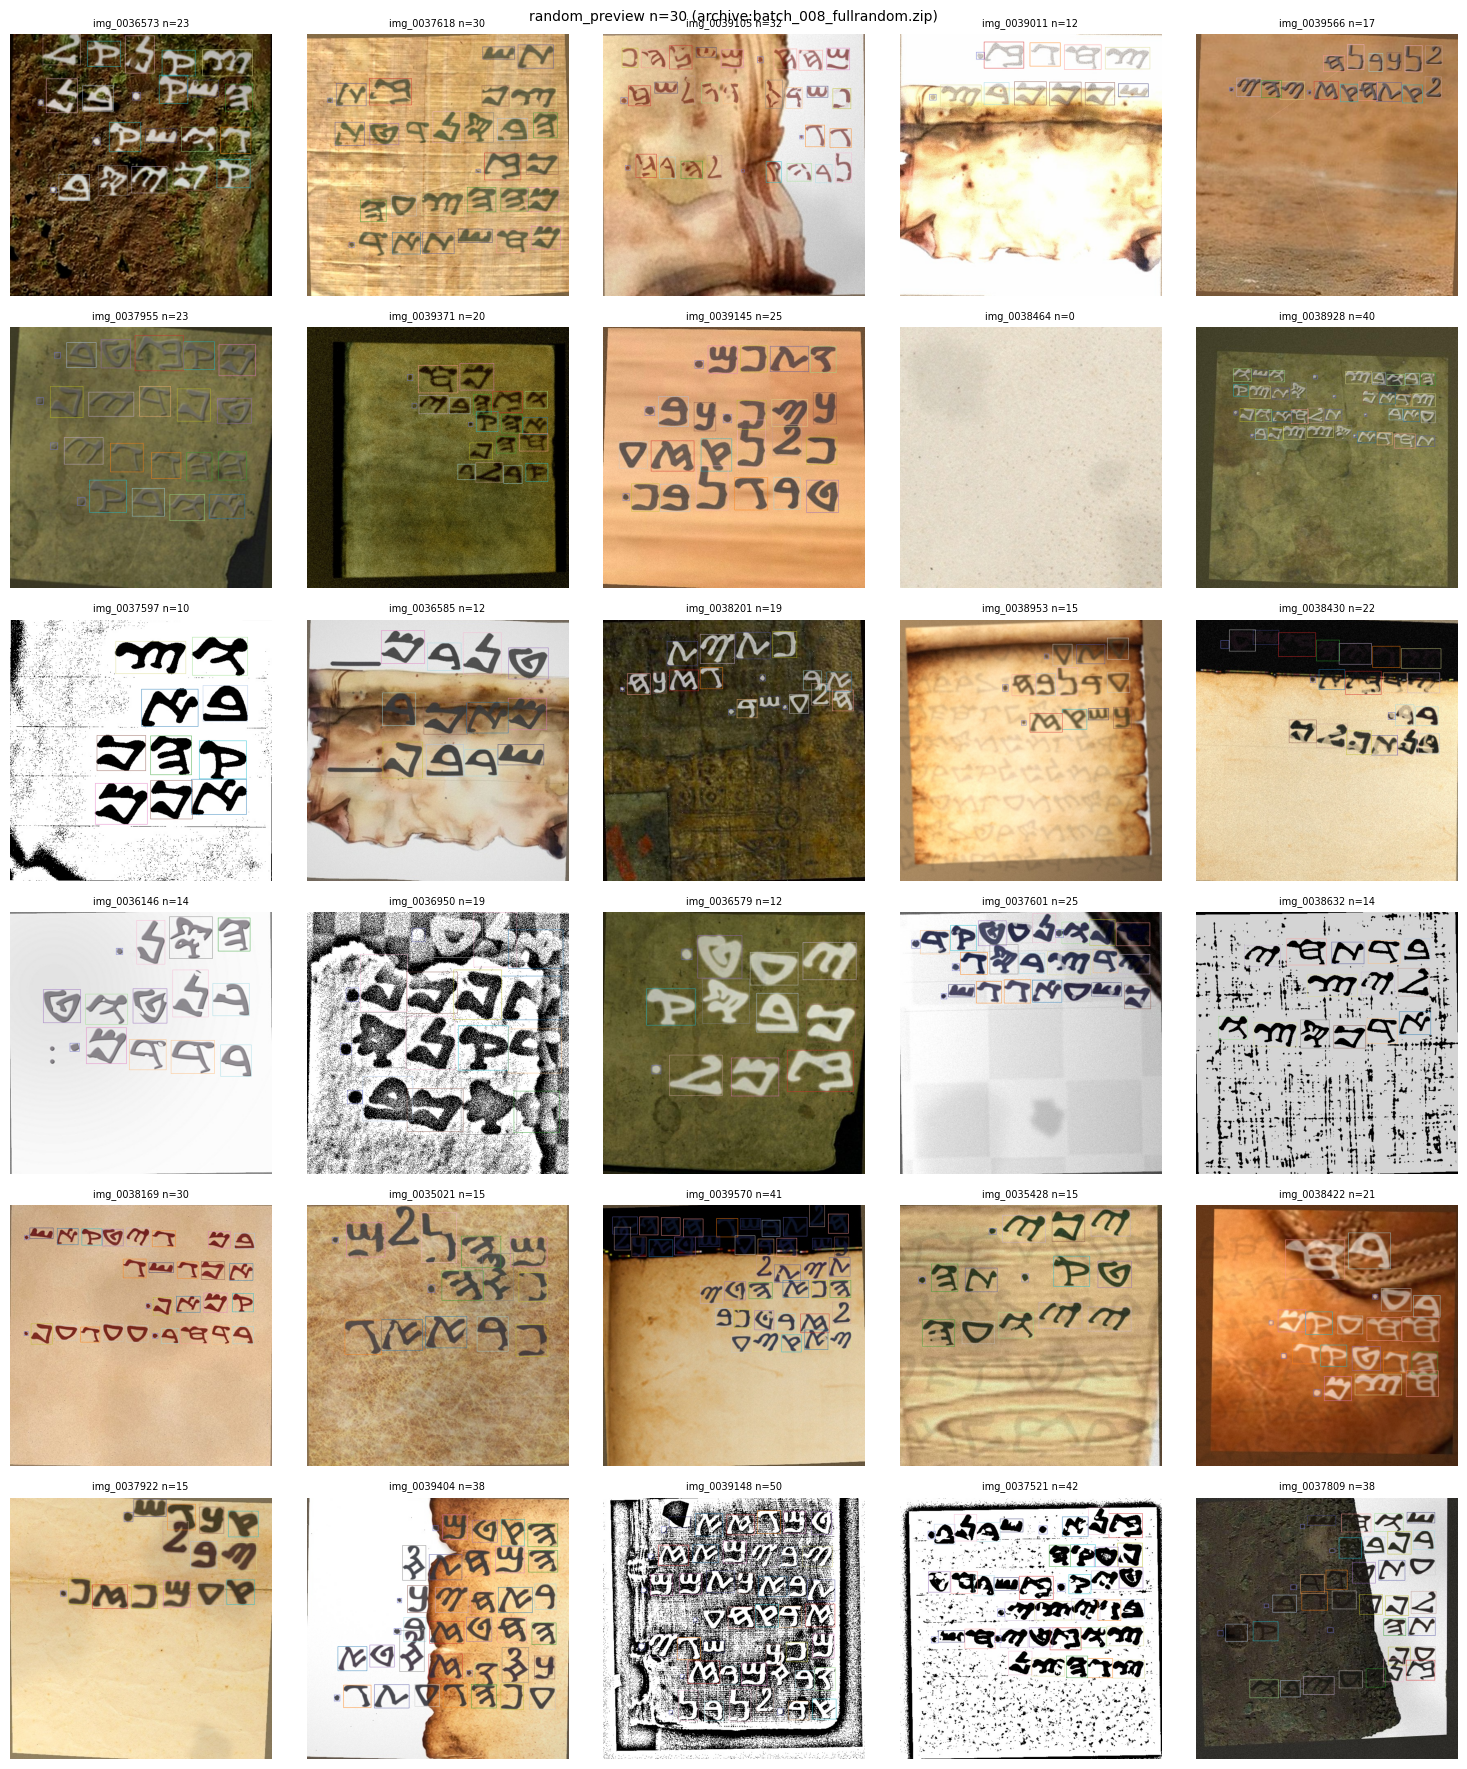

[('img_0036573',
  array([[[12,  5,  0],
          [12,  7,  1],
          [ 9,  4,  0],
          ...,
          [24, 14,  4],
          [11,  3,  0],
          [ 9,  4,  1]],
  
         [[11,  4,  0],
          [10,  5,  0],
          [ 7,  2,  0],
          ...,
          [21, 11,  1],
          [11,  3,  0],
          [ 5,  0,  0]],
  
         [[ 7,  0,  0],
          [ 8,  3,  0],
          [ 9,  4,  1],
          ...,
          [20, 10,  0],
          [ 8,  0,  0],
          [ 5,  0,  0]],
  
         ...,
  
         [[55, 36,  6],
          [56, 40,  7],
          [61, 42, 10],
          ...,
          [ 7,  2,  0],
          [ 8,  3,  0],
          [ 8,  3,  0]],
  
         [[39, 21,  0],
          [41, 25,  0],
          [44, 27,  1],
          ...,
          [ 7,  2,  0],
          [ 7,  2,  0],
          [ 7,  2,  0]],
  
         [[32, 15,  0],
          [35, 19,  0],
          [37, 21,  0],
          ...,
          [ 8,  3,  0],
          [ 8,  3,  0],
          [ 8,  

In [ ]:
### الخلية 15 — Standalone Random Preview

# ===================== الخلية 15: Standalone Random Preview =====================
def random_preview(n=30, cfg=None):
    """معاينة عشوائية مستقلة (تحتاج الخلايا 0-2 فقط): من keep المحلي وإلا من أرشيف عشوائي بلا فك كامل."""
    import matplotlib.pyplot as _plt  # استيراد محلي للاستقلالية
    cfg = cfg if cfg is not None else CONFIG
    S = int(cfg.get("derived", {}).get("S", cfg["dimensions"]["image_size"]))
    ext = "." + cfg["storage"]["image_format"]
    cols = 5  # شبكة 5 أعمدة
    # 23 لونا ثابتا: tab20 + 3 من tab20b
    colors = [tuple(int(c * 255) for c in matplotlib.cm.tab20(i)[:3]) for i in range(20)] + \
             [tuple(int(c * 255) for c in matplotlib.cm.tab20b(i)[:3]) for i in range(3)]
    rng = np.random.default_rng()  # عشوائية معاينة فقط، لا تمس التوليد
    samples, source = [], ""
    # المصدر 1: local_keep_dir
    keep_img = Path(cfg["paths"]["local_keep_dir"]) / "images"
    keep_lbl = Path(cfg["paths"]["local_keep_dir"]) / "labels"
    keep_files = sorted(keep_img.glob(f"*{ext}")) if keep_img.is_dir() else []
    if keep_files:
        source = f"local_keep ({len(keep_files)} img)"
        pick = [keep_files[i] for i in rng.choice(len(keep_files), min(n, len(keep_files)), replace=False)]
        for f in pick:
            img = cv2.cvtColor(cv2.imread(str(f), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
            rows = []
            lp = keep_lbl / f"{f.stem}.txt"
            if lp.is_file():
                for line in open(lp, encoding="utf-8").read().splitlines():
                    p = line.split()
                    if len(p) == 5:
                        rows.append((int(p[0]), float(p[1]), float(p[2]), float(p[3]), float(p[4])))
            samples.append((f.stem, img, rows))
    else:
        # المصدر 2: أرشيف عشوائي من dataset_dir وقراءة n صور عبر zipfile.read
        zips = sorted(Path(cfg["paths"]["dataset_dir"]).glob("batch_*.zip"))
        if not zips:
            print("⚠ لا معاينة: لا keep محلي ولا أرشيفات على Drive.")
            return None
        zp = zips[int(rng.integers(len(zips)))]
        source = f"archive:{zp.name}"
        with zipfile.ZipFile(zp, "r") as z:
            names = [m for m in z.namelist() if m.startswith("images/") and m.endswith(ext)]
            for m in [names[i] for i in rng.choice(len(names), min(n, len(names)), replace=False)]:
                stem = Path(m).stem
                img = cv2.cvtColor(cv2.imdecode(np.frombuffer(z.read(m), np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
                rows = []
                try:
                    txt = z.read(f"labels/{stem}.txt").decode("utf-8")
                except KeyError:
                    txt = ""
                for line in txt.splitlines():
                    p = line.split()
                    if len(p) == 5:
                        rows.append((int(p[0]), float(p[1]), float(p[2]), float(p[3]), float(p[4])))
                samples.append((stem, img, rows))
    if not samples:
        print("⚠ لا عينات."); return None
    rows_n = int(math.ceil(len(samples) / cols))
    fig, axs = _plt.subplots(rows_n, cols, figsize=(cols * 3.0, rows_n * 3.0))
    axs = np.atleast_1d(axs).ravel()
    for ax in axs:
        ax.axis("off")
    for ax, (stem, img, lbl) in zip(axs, samples):
        out = img.copy()
        for (c, xc, yc, w, h) in lbl:  # رسم الصناديق بلون الصنف
            x0, y0 = int(round((xc - w / 2) * S)), int(round((yc - h / 2) * S))
            x1, y1 = int(round((xc + w / 2) * S)), int(round((yc + h / 2) * S))
            cv2.rectangle(out, (x0, y0), (x1, y1), colors[int(c)], 1)
        ax.imshow(out); ax.set_title(f"{stem} n={len(lbl)}", fontsize=7)
    fig.suptitle(f"random_preview n={len(samples)} ({source})", fontsize=10)
    _plt.tight_layout(); _plt.show(); _plt.close(fig)
    return samples

# اختبار سريع
random_preview(n=30, cfg=CONFIG)

تفحص عينة من أرشيف (الأحدث افتراضيا): أخطاء الصيغة والصنف والمدى والأبعاد، نسبة الحبر داخل كل صندوق مقابل وسيط إطار 3×، المكونات الكبيرة غير المغطاة ≥50% (باستثناء التسطير الأفقي الطويل)، هيستوغرام IoU مع تحذير >0.30، توزيع الارتفاع مع تحذير تحت الحد، توزيع الأصناف ونسبة الفارغة. المخرج: تقرير نسب مطبوع + شبكة حتى 15 صورة مشكوكة بأسبابها، أو رسالة جاهزية إن لم توجد أرشيفات بعد.

QA batch_013_controlled.zip:   0%|          | 0/20 [00:00<?, ?it/s]

━━━ QA: batch_013_controlled.zip | عينة=20 ━━━
  صيغة=0 صنف_خارج=0 قيم_خارج=0 أبعاد_صفر=0 | صناديق=562 فارغة=0 (0.0%)
  حبر_ضعيف=0 (0.00%) | صور_بمفقود=10 | صور_IoU>0.3=0
  ارتفاع: تحت 14px=7.30% ⚠ تجاوز 2%
  أصناف: أكثر BIT أقل IT | IoU hist=[11686, 2, 0, 0, 0, 0, 0, 0, 0, 0]


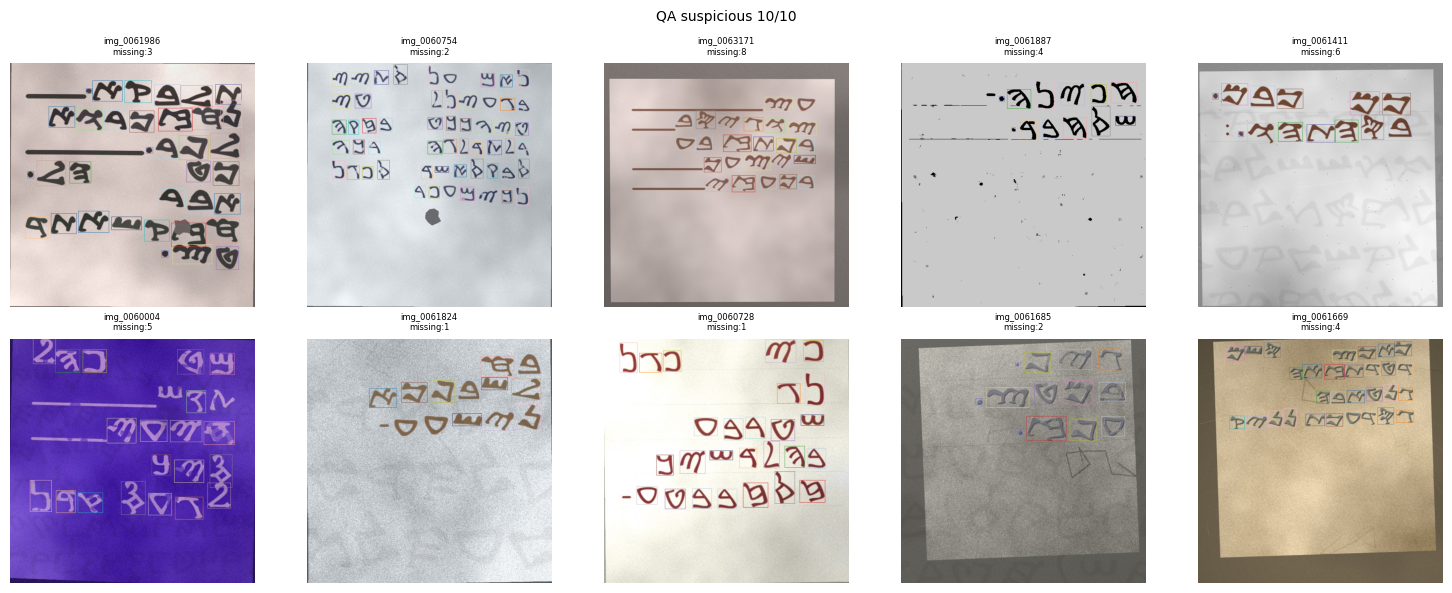

report keys: ['archive', 'n_sampled', 'n_boxes', 'n_empty', 'format_errors', 'class_errors', 'range_errors', 'wh_errors', 'low_ink_boxes', 'images_with_missing', 'images_high_iou', 'pct_below_min_px', 'iou_hist', 'class_counts']


In [ ]:
# ===================== الخلية 16: QA =====================
# عتبات مساعدة غير مرقمة في المواصفة (كلها هنا لا داخل الدوال)
CONFIG.setdefault("qa_consts", {
    "missing_uncovered_frac": 0.50, "ruling_aspect_min": 8.0,
    "ruling_max_thick_px_at_640": 5, "ruling_min_len_frac": 0.20,
    "bg_median_ksize_at_640": 31, "min_area_frac": 0.25,
    "max_area_factor": 4.0, "iou_hist_bins": 10,
    "below_min_warn_pct": 2.0, "n_display": 15, "demo_sample": 20,
})

def _qa_parse(txt):
    """تحليل تسمية: قائمة (class,xc,yc,w,h) + أخطاء صيغة."""
    rows, errs = [], 0
    for line in txt.splitlines():
        p = line.split()
        if len(p) != 5:
            errs += 1; continue
        try:
            rows.append((int(p[0]), float(p[1]), float(p[2]), float(p[3]), float(p[4])))
        except ValueError:
            errs += 1
    return rows, errs

def _qa_boxes_px(rows, S):
    """صناديق بالبكسل (x0,y0,x1,y1) مقصوصة للكانفاس."""
    out = []
    for (c, xc, yc, w, h) in rows:
        x0, y0 = int(round((xc - w / 2) * S)), int(round((yc - h / 2) * S))
        x1, y1 = int(round((xc + w / 2) * S)), int(round((yc + h / 2) * S))
        out.append((c, max(0, x0), max(0, y0), min(S, x1), min(S, y1), w, h))
    return out

def _qa_ink_ratios(gray, boxes_px, thr):
    """نسبة بكسلات الحبر داخل كل صندوق مقابل وسيط إطار 3x."""
    S = gray.shape[0]
    ratios = []
    g16 = gray.astype(np.int16)
    for (_, x0, y0, x1, y1, w, h) in boxes_px:
        if x1 <= x0 or y1 <= y0:
            ratios.append(0.0); continue
        bw, bh = max(1, x1 - x0), max(1, y1 - y0)
        cx, cy = (x0 + x1) / 2.0, (y0 + y1) / 2.0
        ox0, oy0 = max(0, int(cx - bw * 1.5)), max(0, int(cy - bh * 1.5))
        ox1, oy1 = min(S, int(cx + bw * 1.5)), min(S, int(cy + bh * 1.5))
        frame = g16[oy0:oy1, ox0:ox1].copy()
        frame[y0 - oy0:y1 - oy0, x0 - ox0:x1 - ox0] = -9999  # ثقب الداخل
        valid = frame[frame != -9999]
        med = float(np.median(valid)) if valid.size >= 10 else float(np.median(g16[oy0:oy1, ox0:ox1]))
        inner = g16[y0:y1, x0:x1]
        ratios.append(float((np.abs(inner - med) > thr).mean()))
    return ratios

def _qa_pairwise_ious(boxes_px):
    """كل IoU الزوجية داخل صورة (إحداثيات بكسل)."""
    n = len(boxes_px)
    if n < 2:
        return []
    b = np.array([[x0, y0, x1, y1] for (_, x0, y0, x1, y1, _, _) in boxes_px], np.float64)
    out = []
    for i in range(n):
        ix0 = np.maximum(b[i, 0], b[i+1:, 0]); iy0 = np.maximum(b[i, 1], b[i+1:, 1])
        ix1 = np.minimum(b[i, 2], b[i+1:, 2]); iy1 = np.minimum(b[i, 3], b[i+1:, 3])
        inter = np.clip(ix1 - ix0, 0, None) * np.clip(iy1 - iy0, 0, None)
        a_i = (b[i, 2] - b[i, 0]) * (b[i, 3] - b[i, 1])
        a_j = (b[i+1:, 2] - b[i+1:, 0]) * (b[i+1:, 3] - b[i+1:, 1])
        union = np.clip(a_i + a_j - inter, 1e-6, None)
        out.extend((inter / union).tolist())
    return out

def _qa_missing(gray, boxes_px, cfg, S, thr, min_h, max_h):
    """مكونات كبيرة غير مغطاة >=50% (يستثنى خط التسطير الأفقي الطويل)."""
    qc = cfg["qa_consts"]
    k = px(qc["bg_median_ksize_at_640"]) | 1  # فردي
    k = max(11, min(k, 63))
    bg = cv2.medianBlur(gray, k)
    fg = ((np.abs(gray.astype(np.int16) - bg.astype(np.int16)) > thr).astype(np.uint8)) * 255
    fg = cv2.morphologyEx(fg, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    num, lab, stats, _ = cv2.connectedComponentsWithStats(fg, 8)
    if num <= 1:
        return 0
    min_area = max(20.0, (min_h * min_h) * qc["min_area_frac"])
    max_area = (max_h * max_h) * qc["max_area_factor"]
    r_max_h, r_min_len = px(qc["ruling_max_thick_px_at_640"]), qc["ruling_min_len_frac"] * S
    mask = np.zeros((S, S), bool)
    for (_, x0, y0, x1, y1, _, _) in boxes_px:
        if x1 > x0 and y1 > y0:
            mask[y0:y1, x0:x1] = True
    n_miss = 0
    for i in range(1, num):
        area = float(stats[i, cv2.CC_STAT_AREA])
        if area < min_area or area > max_area:
            continue
        w, h = int(stats[i, cv2.CC_STAT_WIDTH]), int(stats[i, cv2.CC_STAT_HEIGHT])
        if h <= r_max_h and (w >= r_min_len or w > qc["ruling_aspect_min"] * max(1, h)):
            continue  # تسطير
        comp = (lab == i)
        covered = float((comp & mask).sum()) / max(1.0, area)
        if 1.0 - covered >= qc["missing_uncovered_frac"]:
            n_miss += 1
    return n_miss

def run_qa(cfg, archive_path=None, sample_size=None):
    """فحص عينة من أرشيف: صيغة، حبر، مفقود، IoU، ارتفاع، أصناف، فارغة + عرض مشكوك."""
    q, qc = cfg["qa"], cfg["qa_consts"]
    S = cfg["derived"]["S"]
    thr, min_ratio, iou_w = q["ink_diff_threshold"], q["min_box_ink_ratio"], q["iou_warn"]
    min_h, max_h = scaled_char_limits(cfg)
    if archive_path is None:  # الأحدث
        zips = sorted(Path(cfg["paths"]["dataset_dir"]).glob("batch_*.zip"))
        if not zips:
            print("⚠ لا أرشيفات للفحص."); return None
        archive_path = str(zips[-1])
    sample_size = int(sample_size or q["sample_size"])
    with zipfile.ZipFile(archive_path, "r") as z:
        names = [m for m in z.namelist() if m.startswith("images/") and m.endswith("." + cfg["storage"]["image_format"])]
        if not names:
            print("⚠ الأرشيف بلا صور."); return None
        rng = np.random.default_rng(int(cfg["general"]["base_seed"]) + 999983)
        pick = [names[i] for i in rng.choice(len(names), min(sample_size, len(names)), replace=False)]
        data = [(m, z.read(m), z.read(f"labels/{Path(m).stem}.txt").decode("utf-8", errors="replace")
                 if f"labels/{Path(m).stem}.txt" in z.namelist() else "") for m in pick]
    # مجاميع
    n_fmt = n_cls = n_rng = n_wh = n_low = n_miss_img = n_high_iou = 0
    n_empty, n_boxes, all_ious, heights = 0, 0, [], []
    class_counts = np.zeros(NUM_CLASSES, np.int64)
    sus = []  # (stem, img, rows, سبب)
    for m, raw, txt in tqdm(data, desc=f"QA {Path(archive_path).name}", leave=False):
        stem = Path(m).stem
        img = cv2.cvtColor(cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        rows, ferr = _qa_parse(txt)
        n_fmt += ferr
        bad_c = sum(1 for r in rows if r[0] < 0 or r[0] > 22)
        bad_r = sum(1 for r in rows if not (0.0 <= r[1] <= 1.0 and 0.0 <= r[2] <= 1.0 and 0.0 <= r[3] <= 1.0 and 0.0 <= r[4] <= 1.0))
        bad_w = sum(1 for r in rows if r[3] <= 0 or r[4] <= 0)
        n_cls += bad_c; n_rng += bad_r; n_wh += bad_w
        if not rows:
            n_empty += 1
        n_boxes += len(rows)
        for r in rows:
            if 0 <= r[0] <= 22:
                class_counts[r[0]] += 1
        boxes_px = _qa_boxes_px(rows, S)
        heights.extend([float(r[4]) * S for r in rows])
        ratios = _qa_ink_ratios(gray, boxes_px, thr)
        low = sum(1 for v in ratios if v < min_ratio)
        n_low += low
        ious = _qa_pairwise_ious(boxes_px)
        all_ious.extend(ious)
        hi = any(v > iou_w for v in ious)
        n_high_iou += int(hi)
        nm = _qa_missing(gray, boxes_px, cfg, S, thr, min_h, max_h)
        n_miss_img += int(nm > 0)
        reason = []
        if ferr or bad_c or bad_r or bad_w:
            reason.append(f"fmt:{ferr}+cls:{bad_c}+rng:{bad_r}+wh:{bad_w}")
        if low:
            reason.append(f"lowink:{low}")
        if nm:
            reason.append(f"missing:{nm}")
        if hi:
            reason.append(f"iou>{iou_w}")
        if reason:
            sus.append((stem, img, rows, ",".join(reason)))
    n = len(data)
    ha = np.asarray(heights, np.float64)
    pct_below = float((ha < min_h).mean() * 100) if ha.size else 0.0
    ia = np.asarray(all_ious, np.float64)
    iou_hist, _ = np.histogram(ia, bins=qc["iou_hist_bins"], range=(0, 1)) if ia.size else (np.zeros(qc["iou_hist_bins"]), None)
    c = class_counts[:NUM_LETTERS]
    hi_l, lo_l = (CLASS_NAMES[int(c.argmax())], CLASS_NAMES[int(c.argmin())]) if c.sum() else ("-", "-")
    print(f"━━━ QA: {Path(archive_path).name} | عينة={n} ━━━")
    print(f"  صيغة={n_fmt} صنف_خارج={n_cls} قيم_خارج={n_rng} أبعاد_صفر={n_wh} | صناديق={n_boxes} فارغة={n_empty} ({n_empty/max(1,n)*100:.1f}%)")
    print(f"  حبر_ضعيف={n_low} ({n_low/max(1,n_boxes)*100:.2f}%) | صور_بمفقود={n_miss_img} | صور_IoU>{iou_w}={n_high_iou}")
    print(f"  ارتفاع: تحت {min_h}px={pct_below:.2f}%" + (" ⚠ تجاوز 2%" if pct_below > qc["below_min_warn_pct"] else " ✓"))
    print(f"  أصناف: أكثر {hi_l} أقل {lo_l} | IoU hist={iou_hist.tolist()}")
    report = {"archive": Path(archive_path).name, "n_sampled": n, "n_boxes": n_boxes, "n_empty": n_empty,
              "format_errors": n_fmt, "class_errors": n_cls, "range_errors": n_rng, "wh_errors": n_wh,
              "low_ink_boxes": n_low, "images_with_missing": n_miss_img, "images_high_iou": n_high_iou,
              "pct_below_min_px": pct_below, "iou_hist": iou_hist.tolist(), "class_counts": class_counts.tolist()}
    if sus:  # عرض حتى 15 مشكوك
        try:
            cols_c = CLASS_COLORS
        except NameError:
            cols_c = [tuple(int(v * 255) for v in matplotlib.cm.tab20(i)[:3]) for i in range(20)] + \
                     [tuple(int(v * 255) for v in matplotlib.cm.tab20b(i)[:3]) for i in range(3)]
        show = sus[:qc["n_display"]]
        cols, rows_n = 5, int(math.ceil(len(show) / 5))
        fig, axs = plt.subplots(rows_n, cols, figsize=(cols * 3.0, rows_n * 3.0))
        for ax in np.atleast_1d(axs).ravel():
            ax.axis("off")
        for ax, (stem, img, rows, rs) in zip(np.atleast_1d(axs).ravel(), show):
            out = img.copy()
            for (cc, xc, yc, w, h) in rows:
                cv2.rectangle(out, (int((xc-w/2)*S), int((yc-h/2)*S)), (int((xc+w/2)*S), int((yc+h/2)*S)), cols_c[int(cc) % 23], 1)
            ax.imshow(out); ax.set_title(f"{stem}\n{rs}", fontsize=6)
        fig.suptitle(f"QA suspicious {len(show)}/{len(sus)}", fontsize=10)
        plt.tight_layout(); plt.show(); plt.close(fig)
    else:
        print("  ✓ بلا صور مشكوكة في العينة.")
    return report

# اختبار سريع (عينة صغيرة من الأحدث إن وجد)
_qa_zips = sorted(Path(CONFIG["paths"]["dataset_dir"]).glob("batch_*.zip"))
if _qa_zips:
    _rep = run_qa(CONFIG, sample_size=CONFIG["qa_consts"]["demo_sample"])
    print("report keys:", list(_rep.keys()) if _rep else None)
else:
    print("QA جاهز. لا أرشيفات بعد — سيعمل تلقائيا بعد أول دفعة.")

تكتب data.yaml داخل Dataset_Multi بمحتوى path: /content/dataset وtrain/val النسبية و23 اسما ثابتا، وتوفر extract_and_split التي تفك كل الأرشيفات إلى /content/dataset بتقسيم حتمي md5(filename)%100. المخرج: مسار yaml ومحتواه مختصرا، عدد الأرشيفات والدفعات المكتملة، وإجماليات metadata مع فارق الموازنة.

In [ ]:
# ===================== الخلية 17: Finalize =====================
def data_yaml_content(cfg, dest="/content/dataset"):
    """محتوى data.yaml: path ثابت + train/val نسبية + nc والأسماء الثابتة."""
    return {"path": dest, "train": "images/train", "val": "images/val",
            "nc": NUM_CLASSES, "names": list(CLASS_NAMES)}

def write_data_yaml(cfg, dest="/content/dataset"):
    """كتابة data.yaml داخل dataset_dir."""
    out = Path(cfg["paths"]["dataset_dir"]) / cfg["paths"]["data_yaml_filename"]
    with open(out, "w", encoding="utf-8") as f:
        yaml.safe_dump(data_yaml_content(cfg, dest), f, sort_keys=False, allow_unicode=True)
    return str(out)

def split_for_file(filename, val_fraction):
    """تقسيم حتمي: md5(filename)%100 < val_fraction*100 → val وإلا train."""
    h = int(hashlib.md5(filename.encode("utf-8")).hexdigest(), 16) % 100
    return "val" if h < float(val_fraction) * 100.0 else "train"

def extract_and_split(cfg, dest="/content/dataset"):
    """فك كل الأرشيفات إلى dest مع تقسيم حتمي لكل ملف. يعيد {train, val}."""
    dest_p = Path(dest)
    for sub in ("images/train", "images/val", "labels/train", "labels/val"):
        (dest_p / sub).mkdir(parents=True, exist_ok=True)
    val_frac = float(cfg["train"]["val_fraction"])
    ext = "." + cfg["storage"]["image_format"]
    zips = sorted(Path(cfg["paths"]["dataset_dir"]).glob("batch_*.zip"))
    counts = {"train": 0, "val": 0}
    for zp in tqdm(zips, desc="extract_and_split"):
        with zipfile.ZipFile(zp, "r") as z:
            imgs = [m for m in z.namelist() if m.startswith("images/") and m.endswith(ext)]
            for m in imgs:
                fname = Path(m).name  # اسم الملف للتجزئة الحتمية
                split = split_for_file(fname, val_frac)
                stem = Path(m).stem
                (dest_p / f"images/{split}" / fname).write_bytes(z.read(m))
                try:
                    txt = z.read(f"labels/{stem}.txt")
                except KeyError:
                    txt = b""
                (dest_p / f"labels/{split}" / f"{stem}.txt").write_bytes(txt)
                counts[split] += 1
    return counts

# كتابة data.yaml + ملخص نهائي
_yaml_path = write_data_yaml(CONFIG)
_ckpt, _meta = load_checkpoint(CONFIG), None
_mp = metadata_path(CONFIG)
if os.path.isfile(_mp):
    with open(_mp, "r", encoding="utf-8") as f:
        _meta = json.load(f)
print("data.yaml:", _yaml_path, "| content:", open(_yaml_path, encoding="utf-8").read().strip().replace("\n", " | ")[:220])
print("archives:", len(sorted(Path(CONFIG['paths']['dataset_dir']).glob('batch_*.zip'))),
      "| completed_batches:", _ckpt["completed_batches"], "/", CONFIG["derived"]["n_batches"])
if _meta:
    _c = np.asarray(_meta["class_counts"], np.int64)
    _hi, _lo = int(_c[:NUM_LETTERS].argmax()), int(_c[:NUM_LETTERS].argmin())
    print(f"total_images={_meta['total_images']} glyphs={_meta['total_glyphs']} dots={_meta['total_dots']} "
          f"avg/img={_meta['avg_chars_per_image']:.2f} | {CLASS_NAMES[_hi]}={_c[_hi]} vs {CLASS_NAMES[_lo]}={_c[_lo]} "
          f"(diff={(_c[_hi]-_c[_lo])/max(1,_c[_hi])*100:.2f}%)")
    print("لتدريب YOLO نفّذ: extract_and_split(CONFIG) ثم استخدم الخلية 18.")
else:
    print("لا metadata بعد — شغّل التوليد (الخلية 14) أولا، ثم extract_and_split(CONFIG).")
# extract_and_split(CONFIG)

⚠ checkpoint: general.total_images كان 200000 والآن 100000 — الاستئناف قد يكون غير متسق.
data.yaml: /content/drive/MyDrive/OCR_Alsameri_Lang_1/Dataset_Multi/data.yaml | content: path: /content/dataset | train: images/train | val: images/val | nc: 23 | names: | - ALAF | - BIT | - GAMAN | - DALAT | - IY | - BAA | - ZEN | - IT | - TIT | - YUT | - KAAF | - LABAT | - MIM | - NUN | - SINGAAT | - IN | 
archives: 13 | completed_batches: 13 / 20
total_images=65000 glyphs=1197141 dots=179742 avg/img=19.18 | RISH=55507 vs TSAADIY=52497 (diff=5.42%)
لتدريب YOLO نفّذ: extract_and_split(CONFIG) ثم استخدم الخلية 18.


خلية مرجعية معطلة افتراضيا تشغّل تدريب YOLO بإعدادات CONFIG فقط. المخرج المتوقع: رسالة عدم التنفيذ، وعند التفعيل يبدأ التدريب ويحفظ الأوزان في مجلد runs.

In [ ]:
# # ===================== الخلية 18: Train =====================
# # مرجعية فقط: لا تنفذ افتراضيا
# RUN_TRAINING = False

# if RUN_TRAINING:
#     # استيراد التدريب فقط هنا
#     from ultralytics import YOLO  # !pip install -q ultralytics عند الحاجة فقط

#     # مسار data.yaml من الخلية 17
#     _data = str(Path(CONFIG["paths"]["dataset_dir"]) / CONFIG["paths"]["data_yaml_filename"])
#     _t = CONFIG["train"]
#     _imgsz = _t["imgsz"] if _t["imgsz"] is not None else CONFIG["dimensions"]["image_size"]

#     # نموذج من الصفر ثم تدريب
#     _model = YOLO(_t["model_name"])
#     _model.train(data=_data, imgsz=_imgsz, epochs=_t["epochs"], batch=_t["batch"], max_det=_t["max_det"],
#                  fliplr=_t["fliplr"], flipud=_t["flipud"], degrees=_t["degrees"],
#                  mosaic=_t["mosaic"], close_mosaic=_t["close_mosaic"],
#                  hsv_h=_t["hsv_h"], hsv_s=_t["hsv_s"], hsv_v=_t["hsv_v"])
#     # ملاحظة: للحروف الصغيرة جرب yolov8n-p2.yaml
#     # ملاحظة: للـ fine-tune لاحقا استخدم lr0=0.001 مع تجميد اختياري freeze
# else:
#     print("RUN_TRAINING=False — خلية مرجعية لم تنفذ. ضع True للتدريب بعد extract_and_split.")